# Feature Extraction and Price Prediction for Mobile Phones

**Scenario:** an organisation that sells mobile phones wants to improve its pricing strategy by finding out which phone features really drive price, and by building a model that predicts price from features.

**Dataset:** `Processed_Flipdata.xlsx` (model, colour, memory, RAM, battery, rear camera, front camera, AI lens, mobile height, processor, price). Keep the file in the same folder as this notebook (or in `./data`).

## How this notebook follows the project brief

| # | Task in the brief | Section |
|---|---|---|
| 1 | Data Exploration | 2 |
| 2 | Data Preprocessing (missing values, outliers, inconsistencies, categorical encoding) | 3 and 6 |
| – | **Feature Engineering** (extra, built before the EDA) | 4 |
| – | **EDA** (extra, runs on the cleaned data with the engineered features): univariate 5.1, bivariate 5.2, multivariate 5.3 | 5 |
| 3 | Feature Extraction (correlation, feature selection, dimensionality reduction) | 7 |
| 4 | Model Building (leakage audit, train/test split **by phone model**, several algorithms) | 8 |
| 5 | Model Evaluation (MAE, RMSE, R², MAPE; grouped cross-validation, nested tuning, model choice on training rows only, residual analysis, model comparison table, data gaps) | 9 |
| 6 | Feature Importance Analysis (permutation, impurity and SHAP explainability) | 10 |
| 7 | Report and Visualization | 11 |
| 8 | Recommendations (prioritised action plan, pricing corridors, pricing audit) | 12 |
| – | Deliverables | 13 |

## Rules used in this notebook
- **Box plots are used only for outlier checks and group comparisons** (Sections 3.5a, 3.5b, 5.2.4); every other distribution uses histograms, density or violin plots.
- **Code and analysis are kept apart.** Code cells contain only code. After every code cell comes a **📊 Analysis** markdown cell that explains the result in words, using the numbers from the run saved in this notebook. If you change the data or the code, re-run the notebook and update those markdown cells.
- **Model section added in this version:** repeated cross-validation (9.2a), tuning of every model (9.4a), residual analysis (9.7), one consolidated model comparison table (9.8), SHAP explainability (10.6), a prioritised business action plan (12.2) and pricing corridors with a pricing audit (12.3).
- **Added in earlier versions (all in simple pandas / scipy code):** outlier box plots and a cap-vs-log comparison (3.5a, 3.5b); the EDA is now grouped into univariate (5.1), bivariate (5.2) and multivariate (5.3) analysis; extended statistics with CV, standard error, percentiles, 95 % confidence intervals and normality tests (5.1.2); QQ plots (5.1.3); Pearson / Spearman / Kendall correlation with p-values and covariance (5.2.2); group statistics, box plots by group, t-test, Mann-Whitney and chi-square tests (5.2.4); ECDF, violin, density and trend-line plots (5.2.5); heatmap, pair plot and VIF (5.3.1, 5.3.2); count heatmap, strip plot and camera scatter (5.3.3).

## 1. Setup

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from scipy import stats
from scipy.stats import f_oneway, kruskal, spearmanr
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, cross_val_predict, KFold, RepeatedKFold, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression, f_regression, RFE
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")              # one global look for both libraries
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

**📊 Analysis**

- The imports are grouped by job (data, charts, statistics, modelling).
- `RANDOM_STATE = 42` makes every random step repeat exactly, so the report numbers can be reproduced.
- Each code cell below is followed by a **📊 Analysis** markdown cell with the reading of its result.

## 2. Data Exploration
**Task:** load the dataset and understand its structure, data types and the range of values of every feature.

In [2]:
def find_data_file(name="Processed_Flipdata.xlsx"):
    for folder in (Path.cwd(), Path.cwd() / "data", Path.cwd().parent):
        if (folder / name).exists():
            return folder / name
    try:                                              # Google Colab: ask for the file
        from google.colab import files
        files.upload()
        return Path(name)
    except ImportError:
        raise FileNotFoundError(f"Put {name} next to this notebook (or in ./data).")

raw = pd.read_excel(find_data_file())       # 'raw' is never changed; cleaning happens on a copy
display(raw.head())

txt_cols_raw = raw.select_dtypes(exclude="number").columns.tolist()
index_cols = [c for c in raw.columns if c.startswith("Unnamed")]

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


**📊 Analysis**

- The file has 541 rows and 12 columns.
- 7 columns are numeric and 5 are text: ['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor_'].
- Leftover index column(s) with no information: ['Unnamed: 0'].
- Columns that are really numbers but stored as text: ['Rear Camera', 'Front Camera'] (e.g. '50MP') -> must be converted before modelling.
- The target column is called 'Prize' (a typo for Price, in rupees).

In [3]:
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                        "missing": raw.isnull().sum(),
                        "missing_%": (raw.isnull().mean() * 100).round(2),
                        "unique": raw.nunique()})
display(quality)

,dtype,missing,missing_%,unique
Unnamed: 0,int64,0,0.0,541
Model,object,0,0.0,187
Colour,object,0,0.0,275
Memory,int64,0,0.0,5
RAM,int64,0,0.0,5
Battery_,int64,0,0.0,37
Rear Camera,object,0,0.0,14
Front Camera,object,0,0.0,13
AI Lens,int64,0,0.0,2
Mobile Height,float64,0,0.0,38


**📊 Analysis**

- Total missing values in the whole table: 0.
- High-cardinality columns (more than 50 distinct values, too many to use directly): ['Model', 'Colour', 'Processor_']. They will be grouped in Section 4.
- Low-cardinality columns (6 or fewer distinct values, behave like levels or yes/no flags): ['Memory', 'RAM', 'AI Lens'].

In [4]:
display(raw.describe().T.round(2))

p = raw["Prize"]
b = raw["Battery_"]

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,289.71,182.36,0.0,135.00,273.00,434.00,642.00
Memory,541.0,110.55,60.60,16.0,64.00,128.00,128.00,256.00
RAM,541.0,5.40,1.98,2.0,4.00,6.00,8.00,8.00
Battery_,541.0,4871.59,780.15,800.0,5000.00,5000.00,5000.00,7000.00
AI Lens,541.0,0.06,0.24,0.0,0.00,0.00,0.00,1.00
Mobile Height,541.0,16.43,2.52,4.5,16.51,16.71,16.94,41.94
Prize,541.0,16228.38,10793.59,920.0,9290.00,13499.00,19280.00,80999.00


**📊 Analysis**

- Price runs from Rs 920 to Rs 80,999; the mean (Rs 16,228) is above the median (Rs 13,499), so a few expensive phones pull the average up.
- Mobile Height goes up to 41.94 cm while the 75th percentile is only 16.94 cm -> impossible values exist and will be corrected in Section 3.
- Battery: median 5,000 mAh, minimum 800 mAh -> a very low minimum suggests basic/feature phones are in the data.

In [5]:
for c in txt_cols_raw:
    print(f"--- {c}  ({raw[c].nunique()} unique) ---")
    print(raw[c].value_counts().head(6).to_string(), "\n")

--- Model  (187 unique) ---
Model
vivo Y16                 9
realme C55               9
SAMSUNG Galaxy A14 5G    9
REDMI Note 12 Pro 5G     9
vivo T1 44W              8
Infinix HOT 30i          8 

--- Colour  (275 unique) ---
Colour
Yellow            12
Royal Blue         8
Power Black        8
Black              8
Midnight Black     7
Cool Blue          7 

--- Rear Camera  (14 unique) ---
Rear Camera
50MP     260
13MP      63
64MP      62
8MP       52
48MP      31
108MP     31 

--- Front Camera  (13 unique) ---
Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
0MP      16 

--- Processor_  (123 unique) ---
Processor_
Qualcomm Snapdragon 680       33
Unisoc T612                   21
Mediatek Helio A22            19
Mediatek Dimensity 1080       18
Qualcomm Snapdragon 695 5G    17
Mediatek Helio P35            16 



**📊 Analysis**

- Most common rear camera: 50MP (48% of rows); most common front camera: 16MP (30%).
- Colour has 275 marketing names and the processor column has 123 spellings -> they will be grouped into a few families.
- Model has 187 distinct names; the first word is the brand.

In [6]:
no_index = raw.drop(columns=index_cols, errors="ignore")
n_dups = int(no_index.duplicated().sum())
bad_text = int(sum(raw[c].astype(str).str.contains("Â|â").sum() for c in ["Colour", "Processor_"]))
tall = raw[raw["Mobile Height"] > 30]

print("Exact duplicate rows:", n_dups)
print("Cells with text-encoding garbage:", bad_text)
print("Rows with Mobile Height > 30 cm:")
display(tall[["Model", "Mobile Height", "Prize"]])

Exact duplicate rows: 10
Cells with text-encoding garbage: 2
Rows with Mobile Height > 30 cm:


,Model,Mobile Height,Prize
75,MOTOROLA G62 5G,41.94,16499
88,MOTOROLA G62 5G,41.94,16499


**📊 Analysis**

- 10 exact duplicate rows were found (they would make the model memorise repeated phones).
- 2 text cells contain encoding garbage (symbols saved in the wrong encoding).
- 2 rows have an impossible height (e.g. 41.94 cm; dividing by 2.54 gives 16.51 cm, i.e. inches were converted to cm twice).
- These problems are fixed one by one in Section 3.

### 2.1 Distribution of the target (price)

Skewness: price = 2.43; log(price) = -0.68  (0 = symmetric, above 1 = strongly right-skewed)


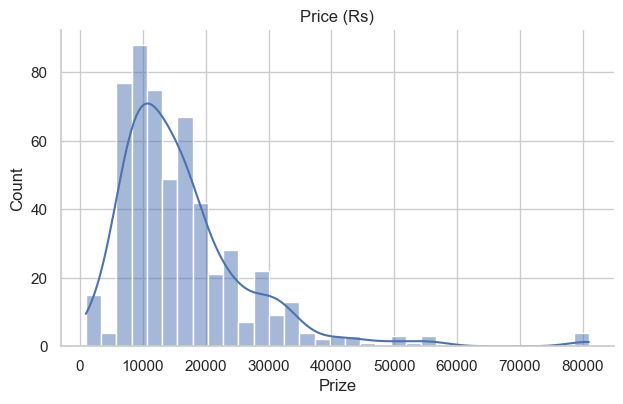

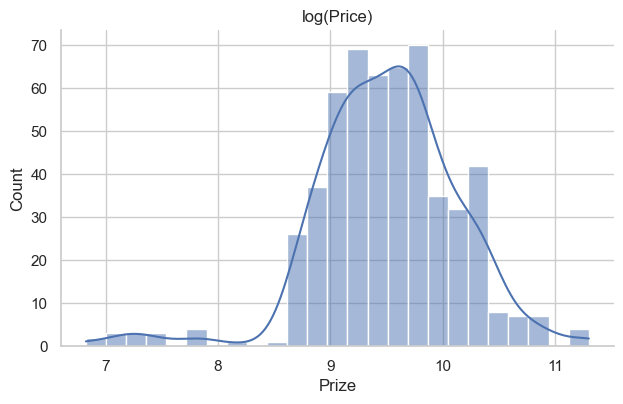

In [7]:
sns.displot(raw["Prize"], kde=True, height=4, aspect=1.6).set(title="Price (Rs)")
sns.displot(np.log(raw["Prize"]), kde=True, height=4, aspect=1.6).set(title="log(Price)")

s_raw, s_log = raw["Prize"].skew(), np.log(raw["Prize"]).skew()
print(f"Skewness: price = {s_raw:.2f}; log(price) = {s_log:.2f}  (0 = symmetric, above 1 = strongly right-skewed)")

**📊 Analysis**

- Skewness of price = 2.43; skewness of log(price) = -0.68 (0 means symmetric, above 1 means strongly right-skewed).
- Price is strongly right-skewed: a few flagship phones cost many times the typical phone.
- DECISION: the models will learn log(price) and convert predictions back to rupees, so that a handful of very expensive phones do not dominate the error.

## 3. Data Preprocessing
**Tasks:** handle missing values, outliers and inconsistencies. All changes are made on a copy called `df`.

### 3.1 Drop the leftover index and rename columns

In [8]:
df = raw.copy()
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
df = df.rename(columns={"Model": "model", "Colour": "colour", "Memory": "storage_gb", "RAM": "ram_gb",
                        "Battery_": "battery_mah", "Rear Camera": "rear_camera_mp", "Front Camera": "front_camera_mp",
                        "AI Lens": "ai_lens", "Mobile Height": "mobile_height_cm",
                        "Processor_": "processor_raw", "Prize": "price"})
log = [("Raw rows", len(raw))]

**📊 Analysis**

- 11 columns remain: ['model', 'colour', 'storage_gb', 'ram_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp', 'ai_lens', 'mobile_height_cm', 'processor_raw', 'price'].
- Names now carry units (gb, mah, mp, cm) and the 'Prize' typo is fixed, so charts and code explain themselves.

### 3.2 Missing values

In [9]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() else "No missing values in any column.")

# safety net in case a future file has gaps
for c in df.select_dtypes("number").columns:
    df[c] = df[c].fillna(df[c].median())          # median: not pulled by extreme prices
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].fillna("Unknown")

log.append(("Missing values found", int(missing.sum())))

No missing values in any column.


**📊 Analysis**

- Missing values found: 0.
- No gaps, so no row had to be dropped or imputed.
- The safety-net code stays in so the notebook still works if a future file has gaps.

### 3.3 Inconsistencies: text clean-up, brand, camera MP to numbers, impossible heights

In [10]:
# 1) text: remove encoding garbage and extra spaces
garbage_before = int(sum(df[c].astype(str).str.contains("Â|â").sum() for c in ["colour", "processor_raw"]))
for c in ["model", "colour", "processor_raw"]:
    df[c] = (df[c].astype(str)
                  .str.replace(r"[ÂâÃ][^\s]*", "", regex=True)
                  .str.replace(r"\s+", " ", regex=True)
                  .str.strip())
df["colour"] = df["colour"].str.title()

# 2) '50MP' -> 50  ('0MP' is a real value for basic phones, not a missing value)
for c in ["rear_camera_mp", "front_camera_mp"]:
    df[c] = df[c].astype(str).str.extract(r"(\d+)")[0].astype(int)

# 3) impossible heights: inches converted to cm twice
too_tall = df["mobile_height_cm"] > 30
df.loc[too_tall, "mobile_height_cm"] = (df.loc[too_tall, "mobile_height_cm"] / 2.54).round(2)

# 4) brand = first word of the model name
first_word = df["model"].str.split().str[0].str.upper().replace({"MICROMAX1": "MICROMAX", "I": "I KALL"})
df["brand"] = first_word.str.title().replace({"Oppo": "OPPO", "Iqoo": "iQOO", "Oneplus": "OnePlus", "Tecno": "TECNO",
                                              "Itel": "itel", "Poco": "POCO", "Vivo": "vivo", "Realme": "realme"})
df["ai_lens"] = df["ai_lens"].astype(int)

log += [("Text cells with garbage cleaned", garbage_before), ("Heights corrected", int(too_tall.sum()))]

**📊 Analysis**

- Cleaned 2 text cells with encoding garbage.
- Camera columns are now whole numbers: rear 0-200 MP, front 0-60 MP.
- 2 impossible screen heights were fixed; the maximum height is now 17.65 cm.
- 19 brands were extracted from the model names: ['Apple', 'Google', 'I Kall', 'Infinix', 'Lava', 'Micromax', 'Motorola', 'Nokia', 'Nothing', 'OPPO', 'OnePlus', 'POCO', 'Redmi', 'Samsung', 'TECNO', 'iQOO', 'itel', 'realme', 'vivo'].
- Reason: models need numbers, not text like '50MP', and one wrong unit conversion would distort the height feature.

### 3.4 Duplicate listings

In [11]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
removed = before - len(df)
log.append(("Duplicate rows removed", removed))

**📊 Analysis**

- Removed 10 exact duplicate rows (541 -> 531 rows).
- Why: duplicates can land in both the training and the test set, which makes the model look better than it really is.

### 3.5 Outliers

In [12]:
out_cols = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm", "price"]
rows = []
for c in out_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (df[c] - df[c].mean()) / df[c].std()
    rows.append({"column": c, "Q1": q1, "Q3": q3, "lower fence": lo, "upper fence": hi,
                 "IQR outliers": int(((df[c] < lo) | (df[c] > hi)).sum()), "Z>3 outliers": int((z.abs() > 3).sum())})
outliers = pd.DataFrame(rows).set_index("column")
display(outliers.round(1))

,Q1,Q3,lower fence,upper fence,IQR outliers,Z>3 outliers
column,,,,,,
storage_gb,64.0,128.0,-32.0,224.0,55,0
ram_gb,4.0,8.0,-2.0,14.0,0,0
battery_mah,5000.0,5000.0,5000.0,5000.0,148,15
rear_camera_mp,13.0,50.0,-42.5,105.5,39,8
front_camera_mp,5.0,16.0,-11.5,32.5,13,13
mobile_height_cm,16.5,16.9,15.9,17.6,30,15
price,9368.0,19338.5,-5587.8,34294.2,25,11


Histogram of each column with the IQR fences (red dashed lines).

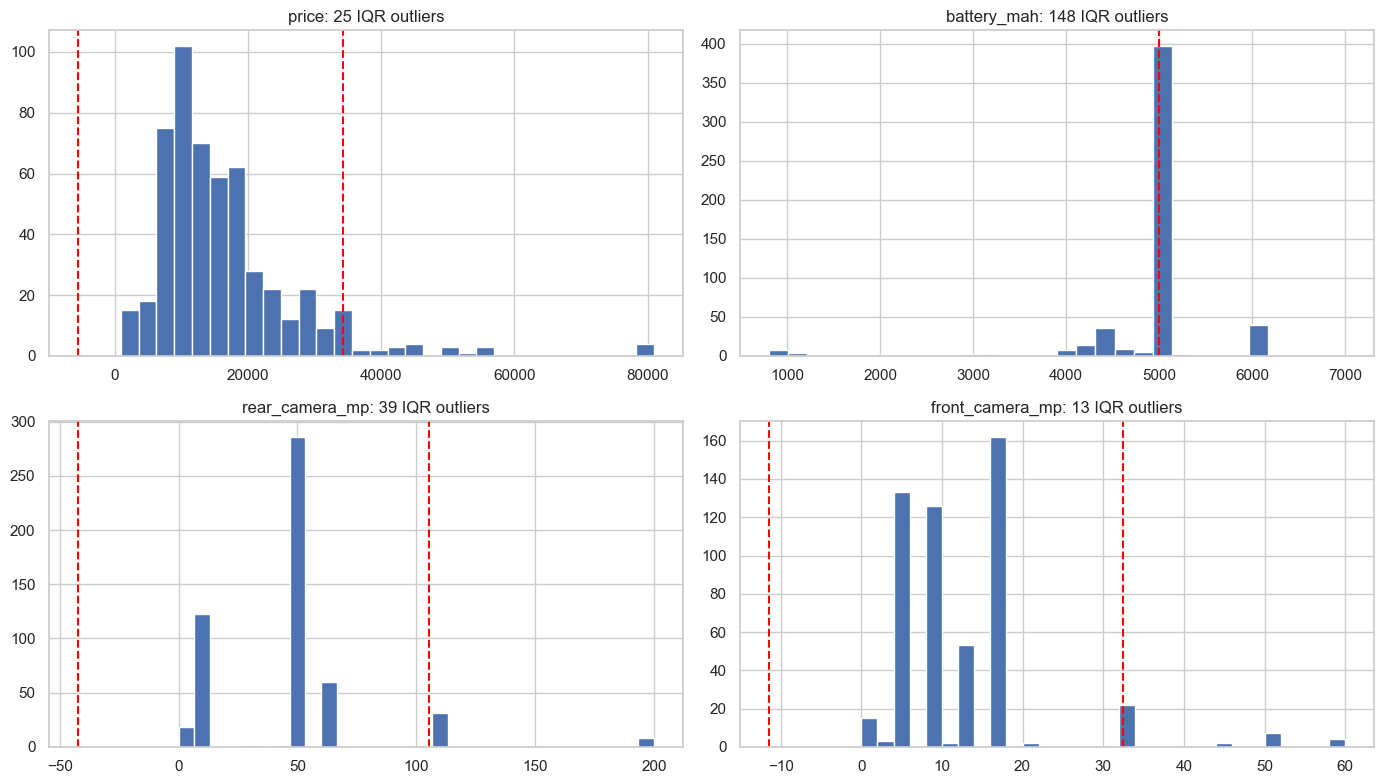

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.flat, ["price", "battery_mah", "rear_camera_mp", "front_camera_mp"]):
    r = outliers.loc[c]
    ax.hist(df[c], bins=30, color="#4C72B0")
    ax.axvline(r["lower fence"], color="red", linestyle="--")
    ax.axvline(r["upper fence"], color="red", linestyle="--")
    ax.set_title(f"{c}: {int(r['IQR outliers'])} IQR outliers")
plt.tight_layout()
plt.show()

**📊 Analysis**

- 25 listings (5%) are price outliers (above Rs 34,294).
- Columns with IQR outliers: ['storage_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp', 'mobile_height_cm', 'price'].
- Battery has IQR = 0 (most phones are exactly the same value), so both fences collapse onto it and every different value is flagged. These are not errors.
- DECISION: no outlier rows are deleted. High prices belong to real flagship phones and 0-2 MP cameras belong to real basic phones. Instead, price is modelled on a log scale (Section 2.1) and basic phones are flagged (next step).

### 3.5a Outlier box plots (numeric columns)
A box plot shows the outliers of a column directly. How to read one, part by part:
- the **box** runs from Q1 (25th percentile) to Q3 (75th percentile), so it holds the middle 50 % of the phones
- the **line inside the box** is the median
- the **whiskers** reach the furthest value that is still inside the fences (Q1 - 1.5 x IQR and Q3 + 1.5 x IQR), the same fences as in the table above
- every **dot** outside the whiskers is an IQR outlier

**Which columns?** `price`, `battery_mah`, `mobile_height_cm`, `rear_camera_mp` and `front_camera_mp` are real measured numbers, so a box plot makes sense. `ram_gb` and `storage_gb` take only a handful of tier values (4, 6, 8, 128, 256 ...), so "outliers" there are meaningless; they are shown **per group** in Section 5.2.4 instead.
Each panel has its own y-axis (`sharey=False`) because rupees, mAh, cm and MP cannot share one scale.

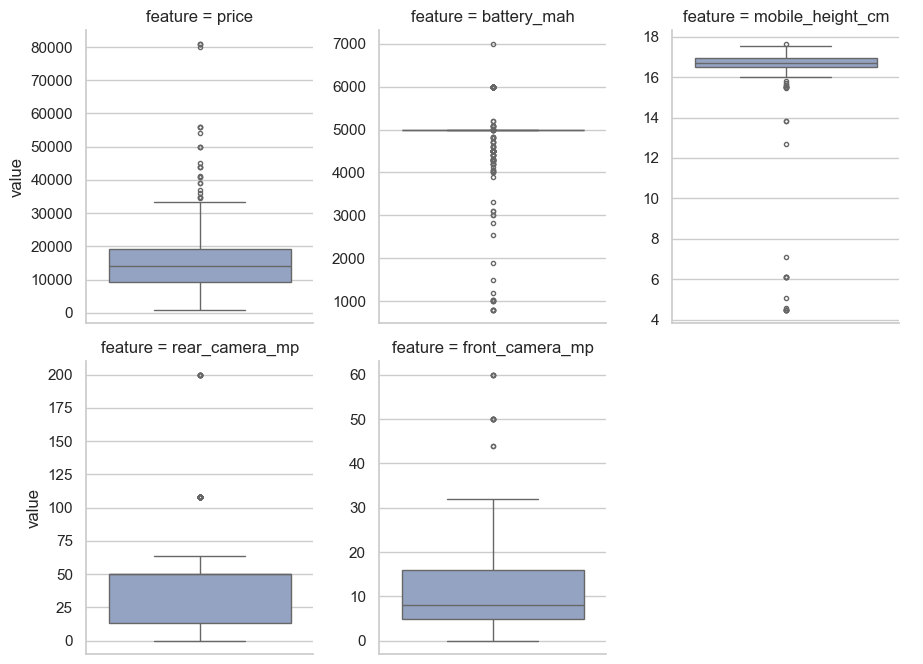

In [14]:
box_cols = ["price", "battery_mah", "mobile_height_cm", "rear_camera_mp", "front_camera_mp"]
box_long = df[box_cols].melt(var_name="feature", value_name="value")      # one tall table: feature | value

sns.catplot(data=box_long, kind="box", y="value", col="feature", col_wrap=3, sharey=False,
            height=3.4, aspect=0.9, color="#8DA0CB", fliersize=3)

share = (outliers.loc[box_cols, "IQR outliers"] / len(df) * 100).round(1)       # % of rows flagged, from the 3.5 table

**📊 Analysis**

- Share of rows flagged as outliers by the IQR rule: price 4.7%, battery_mah 27.9%, mobile_height_cm 5.6%, rear_camera_mp 7.3%, front_camera_mp 2.4%.
- Most outliers: battery_mah (27.9%).
- Price: the box sits low and a long trail of dots stretches upwards = right-skewed prices (flagship phones).
- Battery: Q1 = Q3 (most phones share one value), so the box collapses into a line and every other value shows as a dot. This is a feature of the data, not an error.
- Height: after the Section 3.3 fix the tallest phone is 17.65 cm, so no impossible values remain.
- Reading: dots are only SUSPECTS. Whether to remove them depends on the reason (typo vs real phone), which is decided in 3.5b.

### 3.5b What if we treated the price outliers? Three options compared
Instead of only saying "keep them", this step *tests* the options on the same column:

| Option | What it does | Risk |
|---|---|---|
| 1. Keep as is | nothing changes | skew and outliers stay |
| 2. Cap (winsorise) | every price above the upper fence is replaced **by the fence value** (`clip`) | real flagship prices are flattened |
| 3. Log transform | model `ln(price)` | none for the rows; predictions are converted back with `exp` |

To compare fairly, each version is turned into a **z-score** `(x - mean) / std`, so all three box plots share one scale.

,mean,median,std,skew,kurtosis,IQR outliers left
option,,,,,,
1. keep as is,16305.78,13999.00,10847.04,2.42,9.52,25
2. cap at IQR fence,15564.86,13999.00,8258.67,0.80,-0.15,0
3. log(price),9.51,9.55,0.63,-0.60,2.39,18


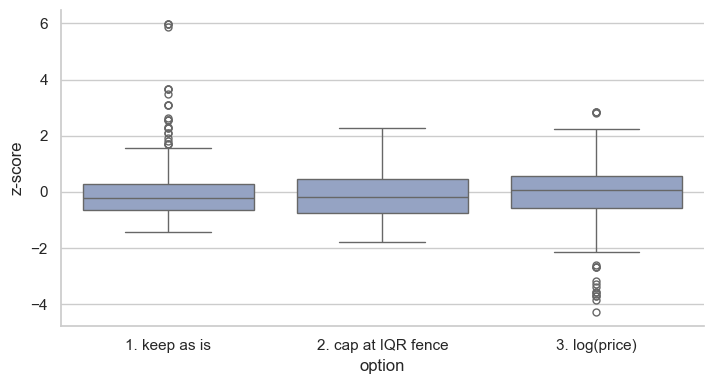

In [15]:
def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

lo, hi = iqr_fences(df["price"])
versions = {"1. keep as is": df["price"],
            "2. cap at IQR fence": df["price"].clip(lower=lo, upper=hi),     # clip: anything above hi becomes hi
            "3. log(price)": np.log(df["price"])}

rows = []
for name, s in versions.items():
    a, b = iqr_fences(s)
    rows.append({"option": name, "mean": s.mean(), "median": s.median(), "std": s.std(),
                 "skew": s.skew(), "kurtosis": s.kurt(), "IQR outliers left": int(((s < a) | (s > b)).sum())})
compare = pd.DataFrame(rows).set_index("option")
display(compare.round(2))

z = pd.DataFrame({name: (s - s.mean()) / s.std() for name, s in versions.items()})      # same scale for all three
sns.catplot(data=z.melt(var_name="option", value_name="z-score"), kind="box", x="option", y="z-score",
            color="#8DA0CB", height=4, aspect=1.8)

**📊 Analysis**

- Option 1 keeps skew = 2.42 and 25 outliers.
- Option 2 (cap) lowers the skew to 0.80, but it rewrites the price of 25 real phones (everything above Rs 34,294 becomes Rs 34,294), so the model could not tell a Rs 34,294 phone from a flagship.
- Option 3 (log) gives skew = -0.60 and 18 outliers, without changing the ordering of any phone.
- Smallest |skew| of the three: 3. log(price).
- DECISION (unchanged): keep all rows and model log(price): it tames the skew without rewriting any real price.

### 3.6 Flag unusual rows and create log(price)

In [16]:
df["basic_phone"] = (df["rear_camera_mp"] <= 2).astype(int)
conflict = df.groupby(["model", "storage_gb", "price"])["ram_gb"].transform("nunique") > 1
df["spec_suspect"] = ((df["basic_phone"] == 1) | ((df["ram_gb"] <= 3) & (df["storage_gb"] >= 256)) | conflict).astype(int)
df["price_log"] = np.log(df["price"])

log.append(("Rows flagged spec_suspect (kept)", int(df["spec_suspect"].sum())))

**📊 Analysis**

- 15 listings look like basic phones (rear camera of 2 MP or less).
- 29 listings (5.5%) are flagged as having possibly unreliable specs (a basic phone, 3 GB RAM with 256 GB storage, or the same model and price with two different RAM sizes).
- They are flagged, not deleted, so the model can use the flag and you can re-run without them if you want to test the effect.
- price_log = ln(price) is the real training target.

### 3.7 Preprocessing summary

In [17]:
assert df[["price", "ram_gb", "storage_gb"]].isnull().sum().sum() == 0
assert df["mobile_height_cm"].max() < 30 and (df["price"] > 0).all()
display(pd.DataFrame(log, columns=["Step", "Count"]))
print("Raw:", raw.shape, "-> cleaned so far:", df.shape)

,Step,Count
0,Raw rows,541
1,Missing values found,0
2,Text cells with garbage cleaned,2
3,Heights corrected,2
4,Duplicate rows removed,10
5,Rows flagged spec_suspect (kept),29


Raw: (541, 12) -> cleaned so far: (531, 15)


**📊 Analysis**

- All cleaning checks passed: no missing values, no impossible heights, all prices positive.
- Encoding of categorical variables comes in Section 6, after the new features exist.

## 4. Feature Engineering
These features come straight from what Sections 2 and 3 showed (123 processor spellings, 271 colour names, brand and model-name text, RAM and storage that behave like tiers). The EDA in Section 5 then runs on the cleaned data that already contains them.

New features are built in small groups. **None of them uses the price**, so there is no target leakage. After every group a short check shows whether the new features carry price information:
- numeric features: Spearman correlation with `price_log`
- categorical features: **eta squared (η²)**, the share of the variation in `price_log` that the groups explain (0 = nothing, 1 = everything)

| Group | New features |
|---|---|
| 4.1 Brand | `brand_tier`, `brand_count`, `is_premium_brand` |
| 4.2 Model name | `name_words`, `name_premium`, `name_lite`, `series_number`, `model_variants`, `model_colours` |
| 4.3 Processor | `processor_brand`, `processor_tier`, `processor_number`, `core_type` |
| 4.4 Colour | `colour_family`, `colour_words` |
| 4.5 Spec maths | `total_camera_mp`, `camera_balance`, `config_score`, `ram_x_storage`, `storage_per_ram`, `battery_per_cm`, `spec_score` |
| 4.6 Bands | rear / front camera, battery, RAM, storage classes |
| 4.7 Flags and interactions | `is_5g`, `flagship_spec`, `budget_spec`, `five_g_x_ram`, `premium_x_config`, `ai_x_rear_cam` |

In [18]:
def eta_squared(feature, target="price_log"):
    # share of the target's variation explained by the groups of a categorical feature
    grand = df[target].mean()
    between = sum(len(g) * (g[target].mean() - grand) ** 2 for _, g in df.groupby(feature))
    return between / ((df[target] - grand) ** 2).sum()

def check_numeric(cols):
    return df[cols].corrwith(df["price_log"], method="spearman").fillna(0).round(3).sort_values(key=abs, ascending=False)

def check_categorical(cols):
    return pd.Series({c: eta_squared(c) for c in cols}).round(3).sort_values(ascending=False)

def flag_gap(flag):
    m = df.groupby(flag)["price"].median()
    if {0, 1}.issubset(m.index):
        return f"{flag}=1 median Rs {m[1]:,.0f} vs {flag}=0 median Rs {m[0]:,.0f} ({m[1] / m[0] - 1:+.0%})"
    return f"{flag} has only one value"

This cell only defines the three small helper functions used by every check below.

### 4.1 Brand features

,brand
brand_tier,
Challenger,"[Nothing, OnePlus, iQOO]"
Mainstream,"[Motorola, Nokia, OPPO, POCO, Redmi, Samsung, ..."
Premium,"[Apple, Google]"
Value,"[I Kall, Infinix, Lava, Micromax, TECNO, itel]"


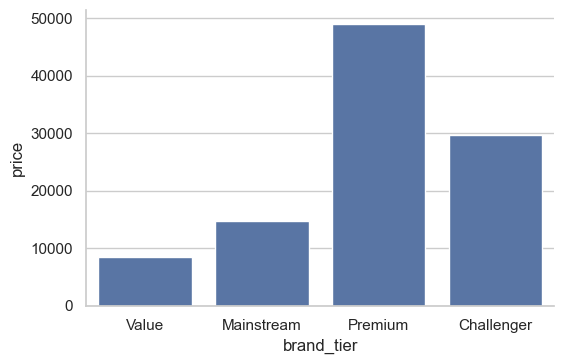

In [19]:
# market position of the brand (domain knowledge, NOT based on price)
BRAND_TIER = {"Apple": "Premium", "Google": "Premium",
              "OnePlus": "Challenger", "iQOO": "Challenger", "Nothing": "Challenger",
              "Infinix": "Value", "TECNO": "Value", "itel": "Value", "Lava": "Value", "Micromax": "Value", "I Kall": "Value"}
df["brand_tier"] = df["brand"].map(BRAND_TIER).fillna("Mainstream")
df["is_premium_brand"] = (df["brand_tier"] == "Premium").astype(int)
df["brand_count"] = df.groupby("brand")["brand"].transform("count")       # how common the brand is in the data

display(df.groupby("brand_tier")["brand"].unique().apply(sorted).to_frame())
sns.catplot(data=df, kind="bar", x="brand_tier", y="price", estimator="median", errorbar=None, height=3.8, aspect=1.5, color="#4C72B0")

**📊 Analysis**

- Brand tiers: {'Mainstream': 406, 'Value': 102, 'Premium': 14, 'Challenger': 9}.
- Brand tier alone explains 31% of the variation in log(price); the full brand explains 50%.
- A tier is more stable than the full brand because it groups tiny brands with similar ones, which helps the model for brands it has seen few times.
- Check the tier list above and move any brand that sits in the wrong tier. is_premium_brand: is_premium_brand=1 median Rs 48,999 vs is_premium_brand=0 median Rs 13,499 (+263%).

### 4.2 Model-name features

In [20]:
name = df["model"].str.lower()
df["name_words"] = name.str.split().str.len()
df["name_premium"] = name.str.contains(r"\b(?:pro|plus|ultra|max|fold|flip)\b|\+").astype(int)
df["name_lite"] = name.str.contains(r"\b(?:lite|neo|go|play|prime)\b").astype(int)
df["series_number"] = pd.to_numeric(name.str.extract(r"(\d+)")[0], errors="coerce").fillna(0)
df["model_variants"] = df.groupby("model")["model"].transform("count")          # rows per model (RAM/storage/colour variants)
df["model_colours"] = df.groupby("model")["colour"].transform("nunique")

new_b = ["name_words", "name_premium", "name_lite", "series_number", "model_variants", "model_colours"]
res_b = check_numeric(new_b)
display(res_b.to_frame("Spearman with price_log"))

,Spearman with price_log
name_words,0.467
name_premium,0.246
name_lite,-0.149
model_variants,0.061
model_colours,-0.052
series_number,-0.009


**📊 Analysis**

- 16% of listings have a premium word (Pro, Plus, Ultra, Max...) and 5% a budget word (Lite, Neo, Go...).
- name_premium=1 median Rs 20,999 vs name_premium=0 median Rs 12,549 (+67%).
- name_lite=1 median Rs 8,999 vs name_lite=0 median Rs 13,999 (-36%).
- Strongest of this group: name_words (rho = +0.47).
- series_number is a rough guess at the model generation; it may be weak because numbering differs between brands. The importance test in Section 10 will tell.

### 4.3 Processor features

,processor_raw,processor_brand,processor_tier,processor_number,core_type
110,Qualcomm Snapdragon 750G,Qualcomm,Upper-mid,750.0,unspecified
289,Mediatek G99,MediaTek,Mid,0.0,unspecified
331,MediaTek Helio G35,MediaTek,Entry,0.0,unspecified
436,snapdragon 888,Qualcomm,Flagship,888.0,unspecified
284,Mediatek Dimensity 700,MediaTek,Mid,700.0,unspecified
249,Unisoc T610,Unisoc,Entry,610.0,unspecified


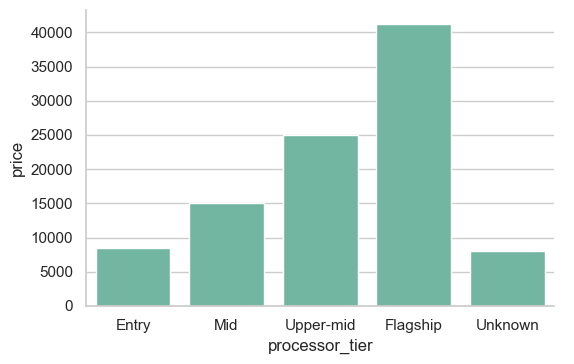

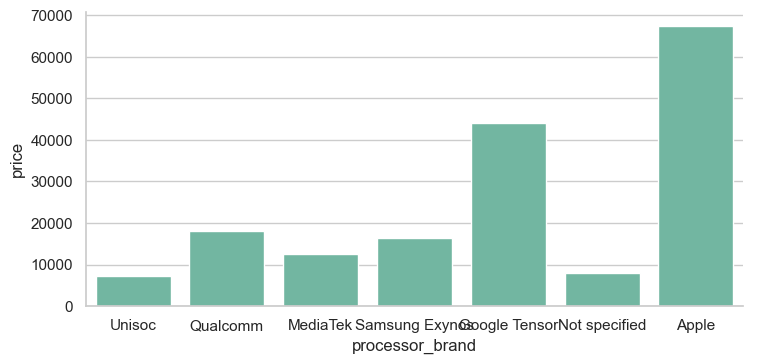

In [21]:
def processor_brand(text):
    s = text.lower()
    if s == "ios":                                                  return "Apple"
    if "tensor" in s:                                               return "Google Tensor"
    if "snapdragon" in s or "qualcomm" in s:                        return "Qualcomm"
    if any(k in s for k in ["dimensity", "helio", "mediatek", "meditek", "mtk", "mt62"]) or re.fullmatch(r"g\d+", s):
                                                                    return "MediaTek"
    if any(k in s for k in ["unisoc", "spreadtrum"]) or re.match(r"(sc\d|t\d{3})", s):
                                                                    return "Unisoc"
    if "exynos" in s or "sec s5e" in s:                             return "Samsung Exynos"
    return "Not specified"

def processor_tier(text, family):
    s = text.lower()
    if family in ("Apple", "Google Tensor"):
        return "Flagship"
    if family == "Qualcomm":
        m = re.search(r"snapdragon\s*(\d)", s)
        return {"8": "Flagship", "7": "Upper-mid", "6": "Mid"}.get(m.group(1), "Entry") if m else "Unknown"
    if family == "MediaTek":
        m = re.search(r"dimensity\s*(\d{3,4})", s)
        if m:
            n = int(m.group(1))
            if n >= 9000:                       return "Flagship"
            if n >= 7000 or 1000 <= n < 2000:   return "Upper-mid"
            return "Mid"
        m = re.search(r"\bg(\d{2,3})\b", s)
        if m:
            return "Mid" if int(m.group(1)) >= 85 else "Entry"
        return "Entry" if re.search(r"helio\s*[ap]\d", s) else "Unknown"
    if family == "Samsung Exynos":
        m = re.search(r"exynos\s*(\d{3,4})", s)
        return ("Flagship" if int(m.group(1)) >= 2000 else "Mid") if m else "Unknown"
    if family == "Unisoc":
        return "Entry"
    return "Unknown"

df["processor_brand"] = df["processor_raw"].apply(processor_brand)
df["processor_tier"] = [processor_tier(t, f) for t, f in zip(df["processor_raw"], df["processor_brand"])]
df["processor_number"] = pd.to_numeric(df["processor_raw"].str.extract(r"(\d{3,4})")[0], errors="coerce").fillna(0)
p = df["processor_raw"].str.lower()
df["core_type"] = np.select([p.str.contains("octa"), p.str.contains("hexa"), p.str.contains("quad")], ["octa", "hexa", "quad"], default="unspecified")

display(df[["processor_raw", "processor_brand", "processor_tier", "processor_number", "core_type"]].sample(6, random_state=1))
sns.catplot(data=df, kind="bar", x="processor_tier", y="price", estimator="median", errorbar=None, height=3.8, aspect=1.5, color="#66C2A5",
            order=[t for t in ["Entry", "Mid", "Upper-mid", "Flagship", "Unknown"] if t in df["processor_tier"].unique()])
sns.catplot(data=df, kind="bar", x="processor_brand", y="price", estimator="median", errorbar=None, height=3.8, aspect=2, color="#66C2A5")

**📊 Analysis**

- 123 raw processor strings were reduced to 7 chip makers and 5 tiers.
- η² (variation in log(price) explained): processor_tier 0.57, processor_brand 0.35, core_type 0.01.
- 4% of phones have an 'Unknown' tier because the listing gives no chip name (e.g. only 'Octa Core'). Treat those with care.
- Processor tier reads the chip series number (Snapdragon 8 = flagship ... Helio G37 = entry), which is knowledge a model cannot learn from a text column with 123 different spellings.

### 4.4 Colour features

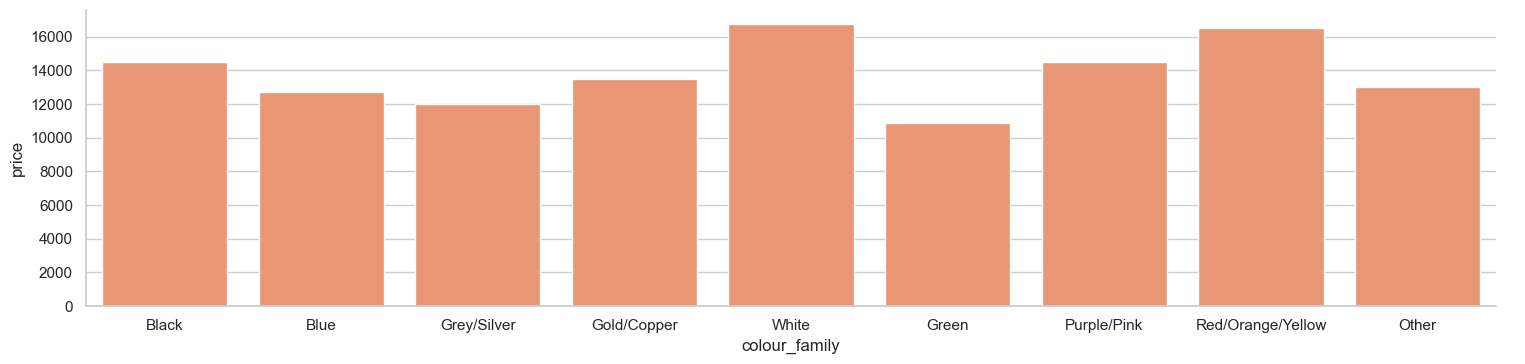

In [22]:
colour_rules = [("Black", r"black|charcoal|graphite|carbon|midnight|onyx|dark matter|eclipse|space"),
                ("Blue", r"blue|navy|azure|cyan|aqua|ocean|sky|denim|turquoise|indigo|glacier"),
                ("Green", r"green|mint|lime|emerald|jade|olive|bamboo|forest"),
                ("White", r"white|pearl|ivory|chalk|cream|snow|milk"),
                ("Grey/Silver", r"gr[ae]y|silver|titanium|steel|slate|ash"),
                ("Gold/Copper", r"gold|copper|champagne|bronze|sand|rose|peach"),
                ("Purple/Pink", r"purple|violet|lavender|lilac|pink|magenta|orchid|fantasy"),
                ("Red/Orange/Yellow", r"red|orange|yellow|coral|flame|amber|marigold|sunrise|sunset|lemon")]

def colour_family(text):
    s = text.lower()
    for part in (s.split()[-1], s):            # the base colour is usually the last word ('Night Black')
        for family, pattern in colour_rules:
            if re.search(pattern, part):
                return family
    return "Other"

df["colour_family"] = df["colour"].apply(colour_family)
df["colour_words"] = df["colour"].str.split().str.len()
sns.catplot(data=df, kind="bar", x="colour_family", y="price", estimator="median", errorbar=None, height=3.8, aspect=4, color="#FC8D62")

**📊 Analysis**

- 271 marketing colour names were grouped into 9 families (the 'Other' group has 30 rows).
- Median price by colour family ranges from Rs 10,849 (Green) to Rs 16,749 (White).
- η² = 0.050: colour explains 5.0% of the variation in log(price) -> check whether this is only because of brand.

### 4.5 Spec maths: totals, ratios and scores

,Spearman with price_log
spec_score,0.865
config_score,0.805
ram_x_storage,0.805
total_camera_mp,0.782
battery_per_cm,-0.441
storage_per_ram,0.346
camera_balance,-0.018


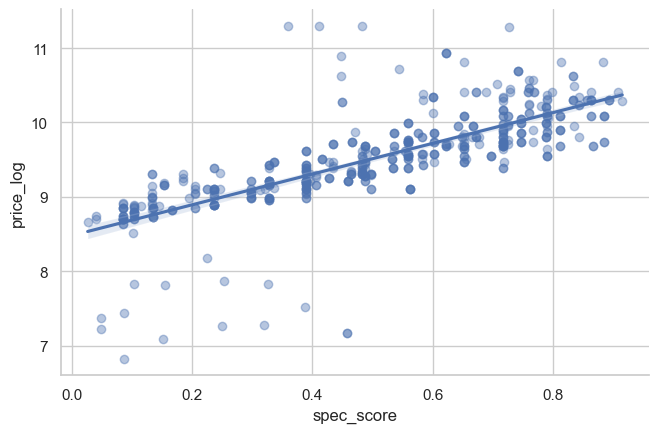

In [23]:
df["total_camera_mp"] = df["rear_camera_mp"] + df["front_camera_mp"]
df["camera_balance"] = df["front_camera_mp"] / (df["rear_camera_mp"] + 1)
df["config_score"] = np.log2(df["ram_gb"]) + np.log2(df["storage_gb"])            # each doubling of RAM or storage adds 1
df["ram_x_storage"] = df["ram_gb"] * df["storage_gb"]
df["storage_per_ram"] = df["storage_gb"] / df["ram_gb"]
df["battery_per_cm"] = df["battery_mah"] / df["mobile_height_cm"]
df["spec_score"] = df[["ram_gb", "storage_gb", "rear_camera_mp", "front_camera_mp"]].rank(pct=True).mean(axis=1)   # 0 to 1

new_e = ["total_camera_mp", "camera_balance", "config_score", "ram_x_storage", "storage_per_ram", "battery_per_cm", "spec_score"]
res_e = check_numeric(new_e)
display(res_e.to_frame("Spearman with price_log"))
sns.lmplot(data=df, x="spec_score", y="price_log", scatter_kws={"alpha": 0.4}, height=4.5, aspect=1.5)

**📊 Analysis**

- Strongest new spec feature: spec_score (rho = +0.86) compared with the strongest original spec (|rho| = 0.81).
- Combining specs gives a stronger single signal than any one original spec.
- config_score uses log2 so that each doubling of RAM or storage counts equally, matching how phones are sold (4->8->16 GB).
- spec_score is the average percentile rank of RAM, storage and both cameras: one number for 'how strong are the specs overall'.
- These features overlap with the originals on purpose; Section 4.8 checks the overlap.

### 4.6 Banded (class) features

rear_cam_class {'mid': 291, 'entry': 126, 'high': 60, 'ultra': 39, 'basic': 15}
front_cam_class {'entry': 259, 'mid': 217, 'high': 37, 'basic': 18}
battery_class {'standard': 462, 'large': 51, 'low': 18}
ram_class {'mid': 299, 'high': 155, 'low': 77}
storage_class {'medium': 419, 'small': 57, 'large': 55}


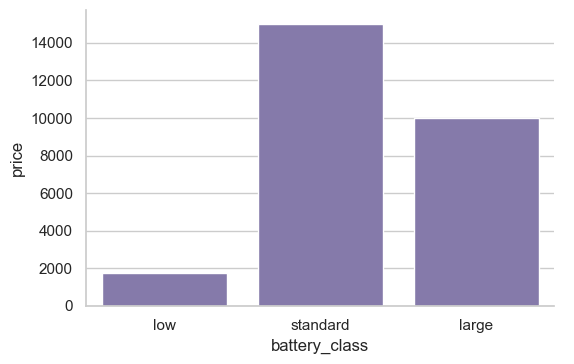

In [24]:
def band(series, edges, labels):
    return pd.cut(series, edges, labels=labels).astype(str)

df["rear_cam_class"] = band(df["rear_camera_mp"], [-1, 2, 13, 50, 64, 10_000], ["basic", "entry", "mid", "high", "ultra"])
df["front_cam_class"] = band(df["front_camera_mp"], [-1, 2, 8, 16, 10_000], ["basic", "entry", "mid", "high"])
df["battery_class"] = band(df["battery_mah"], [0, 3000, 5000, 100_000], ["low", "standard", "large"])
df["ram_class"] = band(df["ram_gb"], [0, 3, 6, 100], ["low", "mid", "high"])
df["storage_class"] = band(df["storage_gb"], [0, 32, 128, 10_000], ["small", "medium", "large"])

band_cols = ["rear_cam_class", "front_cam_class", "battery_class", "ram_class", "storage_class"]
for c in band_cols:
    print(c, df[c].value_counts().to_dict())
sns.catplot(data=df, kind="bar", x="battery_class", y="price", estimator="median", errorbar=None, height=3.8, aspect=1.5, color="#8172B2",
            order=["low", "standard", "large"])

**📊 Analysis**

- η² (variation in log(price) explained): front_cam_class 0.65, rear_cam_class 0.53, ram_class 0.30, battery_class 0.28, storage_class 0.27.
- Most informative band: front_cam_class; least informative: storage_class.
- Why bands: price often jumps between levels (a phone with a 50 MP camera is a different product class than a 13 MP one) instead of rising smoothly.
- Banded versions are most helpful for linear models; tree models can find such cut-offs themselves.

### 4.7 Flags and interactions

,Spearman with price_log
budget_spec,-0.732
five_g_x_ram,0.642
is_5g,0.623
flagship_spec,0.510
premium_x_config,0.266
ai_x_rear_cam,-0.202


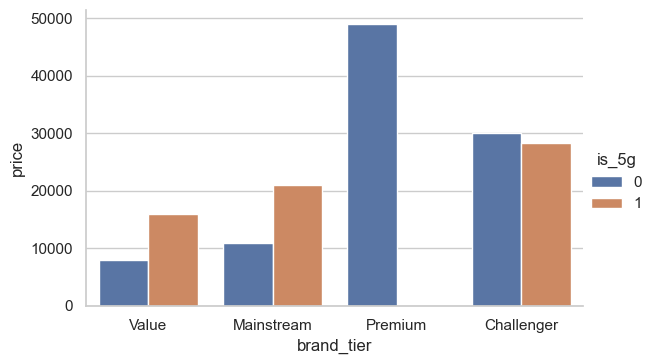

In [25]:
df["is_5g"] = (df["model"].str.contains("5G", case=False) | df["processor_raw"].str.contains("5G", case=False)).astype(int)
df["flagship_spec"] = ((df["ram_gb"] >= 8) & (df["storage_gb"] >= 128) & (df["is_5g"] == 1)).astype(int)
df["budget_spec"] = ((df["ram_gb"] <= 4) & (df["storage_gb"] <= 64)).astype(int)

# interactions: two features that work together
df["five_g_x_ram"] = df["is_5g"] * df["ram_gb"]
df["premium_x_config"] = df["is_premium_brand"] * df["config_score"]
df["ai_x_rear_cam"] = df["ai_lens"] * df["rear_camera_mp"]

new_g = ["is_5g", "flagship_spec", "budget_spec", "five_g_x_ram", "premium_x_config", "ai_x_rear_cam"]
res_g = check_numeric(new_g)
display(res_g.to_frame("Spearman with price_log"))
sns.catplot(data=df, kind="bar", x="brand_tier", y="price", hue="is_5g", estimator="median", errorbar=None, height=3.8, aspect=1.6)

**📊 Analysis**

- 36% of listings say '5G' (a lower bound: some 5G phones do not say so in the listing).
- is_5g=1 median Rs 19,999 vs is_5g=0 median Rs 9,999 (+100%).
- flagship_spec=1 median Rs 23,999 vs flagship_spec=0 median Rs 11,999 (+100%).
- budget_spec=1 median Rs 8,992 vs budget_spec=0 median Rs 17,999 (-50%).
- Strongest of this group: budget_spec (rho = -0.73).
- An interaction lets the model say 'a 5G label matters more when RAM is large' or 'a premium brand adds more at higher specs'. The chart shows the 5G gap across brand tiers.

### 4.8 Feature lists and audit of all engineered features

In [26]:
# original features (what a basic model would use)
base_num = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm", "ai_lens", "is_5g"]
base_cat = ["brand", "processor_brand", "colour_family"]

# engineered features
new_num = ["brand_count", "is_premium_brand", "name_words", "name_premium", "name_lite", "series_number",
           "model_variants", "model_colours", "processor_number", "colour_words",
           "total_camera_mp", "camera_balance", "config_score", "ram_x_storage", "storage_per_ram",
           "battery_per_cm", "spec_score", "basic_phone", "flagship_spec", "budget_spec",
           "five_g_x_ram", "premium_x_config", "ai_x_rear_cam"]
new_cat = ["brand_tier", "processor_tier", "core_type", "rear_cam_class", "front_cam_class", "battery_class", "ram_class", "storage_class"]

num_features = base_num + new_num
cat_features = base_cat + new_cat
all_features = num_features + cat_features
TARGET = "price"

assert df[all_features].isnull().sum().sum() == 0 and np.isfinite(df[num_features]).all().all()
audit_num = check_numeric(new_num)

overlap = df[num_features].corr(method="spearman").abs().where(~np.triu(np.ones((len(num_features),) * 2, dtype=bool))).stack()
overlap = overlap[overlap > 0.9].sort_values(ascending=False)
print(f"{len(base_num + base_cat)} original features -> {len(all_features)} features after engineering "
      f"({len(new_num)} new numeric + {len(new_cat)} new categorical)")
print("Pairs of numeric features with |rho| > 0.9 (nearly the same information):")
display(overlap.head(10).round(3).to_frame("|rho|"))

11 original features -> 42 features after engineering (23 new numeric + 8 new categorical)
Pairs of numeric features with |rho| > 0.9 (nearly the same information):


|rho|
ram_x_storage    config_score      1.000
premium_x_config is_premium_brand  1.000
ai_x_rear_cam    ai_lens           0.999
five_g_x_ram     is_5g             0.974
config_score     storage_gb        0.927
ram_x_storage    storage_gb        0.927
config_score     ram_gb            0.920
ram_x_storage    ram_gb            0.920
spec_score       config_score      0.919
                 ram_x_storage     0.919

Strength of every new numeric feature (absolute Spearman correlation with log price).

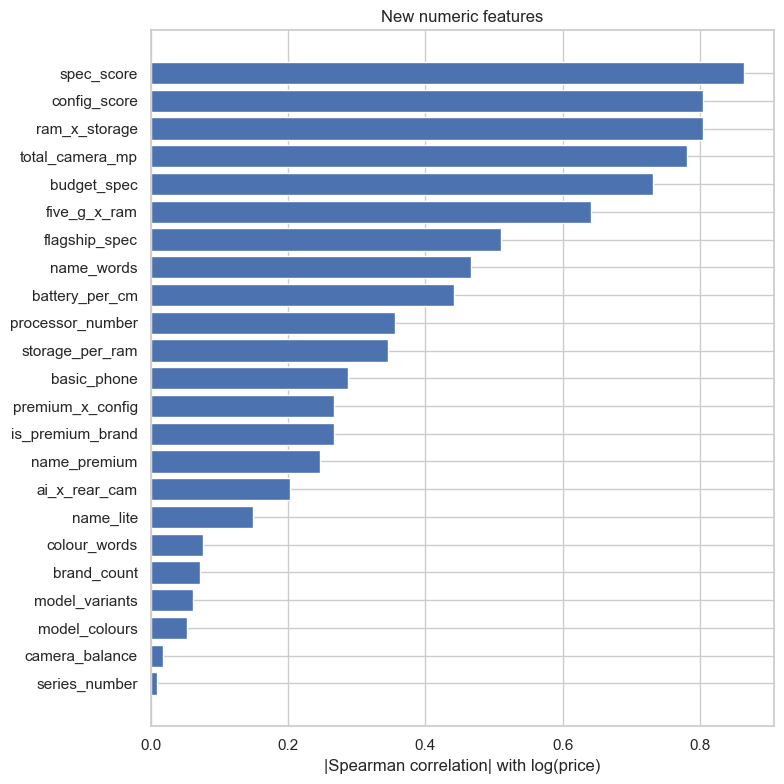

In [27]:
audit_sorted = audit_num.abs().sort_values()
plt.figure(figsize=(8, 8))
plt.barh(audit_sorted.index, audit_sorted.values, color="#4C72B0")
plt.xlabel("|Spearman correlation| with log(price)")
plt.title("New numeric features")
plt.tight_layout()
plt.show()

**📊 Analysis**

- 42 features are ready (11 original + 31 engineered).
- Strongest new numeric features: spec_score (+0.86), ram_x_storage (+0.81), config_score (+0.81).
- New numeric features with almost no straight-line link to price (|rho| < 0.1): ['colour_words', 'brand_count', 'model_variants', 'model_colours', 'camera_balance', 'series_number']. Weak alone does not mean useless: they can help in combination, which Section 10 tests.
- Strongest new categorical features by η²: front_cam_class (0.65), processor_tier (0.57), rear_cam_class (0.53).
- 12 pairs of numeric features have |rho| > 0.9: they repeat each other, which is fine for tree models but can make linear coefficients unstable.
- Whether the extra features really improve predictions is tested fairly in Section 9.5 (phone models held out).

## 5. Exploratory Data Analysis (EDA) on the cleaned data
EDA answers: *what does each feature look like, and how does each relate to price?* The engineered features from Section 4 are already in the table; the findings below show why they were worth building and which modelling choices follow.

The EDA is organised by **how many features are looked at together**:

| Level | Question it answers | Sections |
|---|---|---|
| **Univariate** (one feature) | What does each feature look like on its own: centre, spread, shape, most common values? | 5.1 |
| **Bivariate** (two features) | How does each feature relate to price, and are the links real or chance? | 5.2 |
| **Multivariate** (three or more) | Which features overlap with each other, and how do they work together on price? | 5.3 |

Every code cell is followed by a **📊 Analysis** markdown cell that reads the result in plain words.

### 5.1 Univariate analysis (one feature at a time)
Each feature is studied alone, before looking at price. Numeric features get statistics, histograms and QQ plots; categorical features get counts.

#### 5.1.1 Numeric features: shape, centre and spread
The table gives mean, median, standard deviation, skewness and the most common value. The histograms (with a smooth density line) show the shape of every numeric column.

,mean,median,std,skew,kurtosis,most common value,share of most common (%)
storage_gb,110.92,128.00,60.87,1.03,0.82,128.00,47.83
ram_gb,5.40,6.00,1.99,0.06,-1.31,4.00,33.90
battery_mah,4873.88,5000.00,765.88,-3.33,15.25,5000.00,72.13
rear_camera_mp,46.23,50.00,31.39,1.81,7.21,50.00,48.02
front_camera_mp,12.05,8.00,9.11,2.49,8.65,16.00,30.51
mobile_height_cm,16.35,16.71,1.94,-5.44,28.91,16.76,23.16
price,16305.78,13999.00,10847.04,2.42,9.52,15999.00,4.33


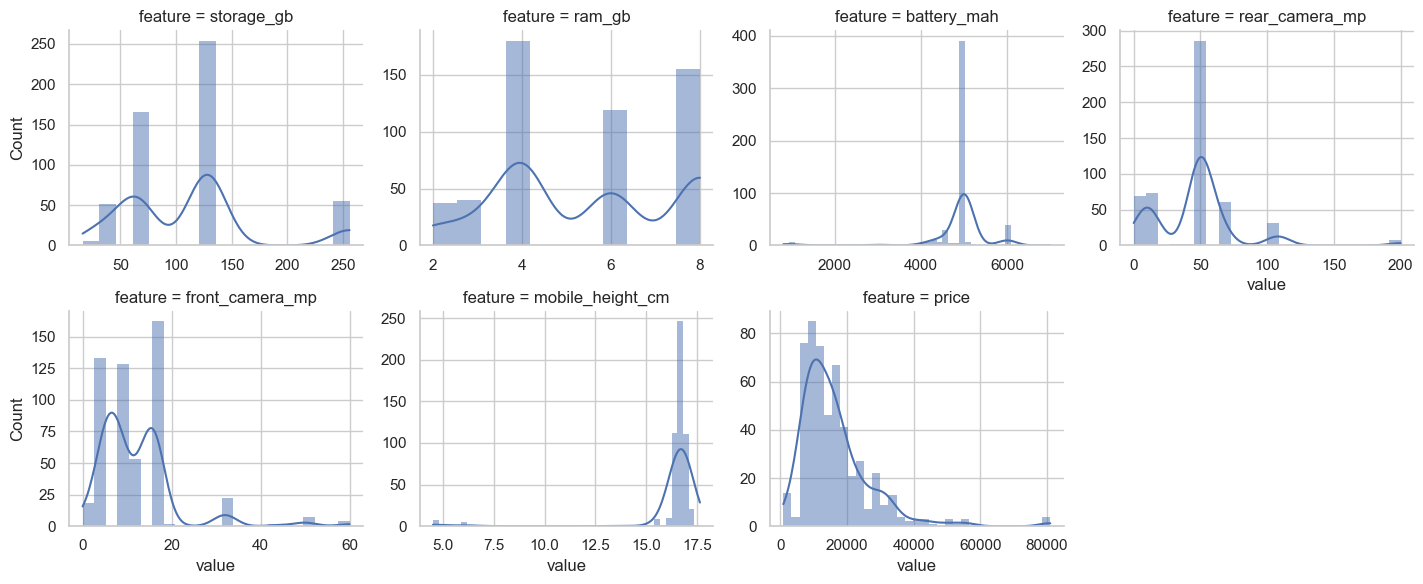

In [28]:
eda_num = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm", "price"]
uni = pd.DataFrame({"mean": df[eda_num].mean(), "median": df[eda_num].median(), "std": df[eda_num].std(),
                    "skew": df[eda_num].skew(), "kurtosis": df[eda_num].kurt(),
                    "most common value": [df[c].mode().iloc[0] for c in eda_num],
                    "share of most common (%)": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in eda_num]}).round(2)
display(uni)

long = df[eda_num].melt(var_name="feature", value_name="value")
sns.displot(data=long, x="value", col="feature", col_wrap=4, kde=True, common_bins=False,
            facet_kws={"sharex": False, "sharey": False}, height=3, aspect=1.2)

**📊 Analysis**

- Strongly skewed features (|skew| > 1): ['storage_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp', 'mobile_height_cm', 'price'].
- Features where one single value covers more than half of the rows: ['battery_mah'] -> they behave like flags, so a 'class' version (e.g. standard vs large battery) may be more useful than the raw number.
- RAM and storage take only 5 and 5 distinct values, so they act like levels (tiers) rather than smooth numbers.

#### 5.1.2 Extended statistics for every numeric column
Simple pandas one-liners, one statistic per line. What each one tells you:

| Statistic | Code idea | What it tells you |
|---|---|---|
| mean / median / mode | `.mean()` `.median()` `.mode()` | the typical value (3 ways). Mean far above median = a few big values pull it up |
| range | `max - min` | total spread, but only looks at 2 phones |
| variance / std | `.var()` `.std()` | average distance from the mean (std is in the column's own unit) |
| std error | `.sem()` | how precisely the sample mean estimates the true mean = `std / sqrt(n)` |
| CV % | `std / mean * 100` | spread **relative** to the size of the numbers, so you can compare rupees with mAh |
| P5, Q1, Q3, P95, IQR | `.quantile(...)` | where the middle 50 % and the extremes lie; `IQR = Q3 - Q1` |
| skew | `.skew()` | 0 = symmetric, above 1 = long right tail |
| kurtosis | `.kurt()` | pandas gives **excess** kurtosis: 0 = normal tails, above 3 = very heavy tails (more extreme values than normal) |
| 95 % CI | `stats.t.interval` | range that contains the true average 95 times out of 100 |
| normality test | `stats.normaltest` | p-value above 0.05 = the column could be normal |

In [29]:
num_stats = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm", "price"]
s = df[num_stats]
q1, q3 = s.quantile(.25), s.quantile(.75)

ext = pd.DataFrame({
    "count": s.count(), "mean": s.mean(), "median": s.median(), "mode": [s[c].mode().iloc[0] for c in num_stats],
    "min": s.min(), "max": s.max(), "range": s.max() - s.min(),
    "variance": s.var(), "std": s.std(), "std error": s.sem(),
    "CV %": s.std() / s.mean() * 100,
    "P5": s.quantile(.05), "Q1": q1, "Q3": q3, "P95": s.quantile(.95), "IQR": q3 - q1,
    "skew": s.skew(), "kurtosis": s.kurt()})
ext["mean vs median %"] = (ext["mean"] - ext["median"]) / ext["median"] * 100
display(ext.T.round(2))

# 95 % confidence interval of the mean + normality test, side by side
ci = pd.DataFrame({c: stats.t.interval(0.95, len(s) - 1, loc=s[c].mean(), scale=s[c].sem()) for c in num_stats},
                  index=["CI low", "CI high"]).T
norm = pd.DataFrame({c: tuple(stats.normaltest(s[c])) for c in num_stats}, index=["statistic", "p-value"]).T
summary = ci.join(norm)
summary["could be normal?"] = np.where(summary["p-value"] > 0.05, "yes", "no")
display(summary.round(4))

,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,mobile_height_cm,price
count,531.00,531.00,531.00,531.00,531.00,531.00,5.310000e+02
mean,110.92,5.40,4873.88,46.23,12.05,16.35,1.630578e+04
median,128.00,6.00,5000.00,50.00,8.00,16.71,1.399900e+04
mode,128.00,4.00,5000.00,50.00,16.00,16.76,1.599900e+04
min,16.00,2.00,800.00,0.00,0.00,4.50,9.200000e+02
max,256.00,8.00,7000.00,200.00,60.00,17.65,8.099900e+04
range,240.00,6.00,6200.00,200.00,60.00,13.15,8.007900e+04
variance,3705.51,3.97,586576.97,985.47,82.90,3.76,1.176582e+08
std,60.87,1.99,765.88,31.39,9.11,1.94,1.084704e+04
std error,2.64,0.09,33.24,1.36,0.40,0.08,4.707200e+02


,CI low,CI high,statistic,p-value,could be normal?
storage_gb,105.7258,116.1047,76.4387,0.0,no
ram_gb,5.2314,5.5709,951.1822,0.0,no
battery_mah,4808.5862,4939.1690,406.4872,0.0,no
rear_camera_mp,43.5517,48.9040,230.3164,0.0,no
front_camera_mp,11.2690,12.8214,302.7817,0.0,no
mobile_height_cm,16.1889,16.5195,586.6298,0.0,no
price,15381.0673,17230.4845,302.6935,0.0,no


**📊 Analysis**

- Most spread out relative to its size (highest CV): front_camera_mp (76 %); most uniform: mobile_height_cm (12 %).
- Price: mean Rs 16,306 vs median Rs 13,999 (+16 %); the true average price lies between Rs 15,381 and Rs 17,230 (95 % confidence).
- Heavy tails (excess kurtosis > 3): ['battery_mah', 'rear_camera_mp', 'front_camera_mp', 'mobile_height_cm', 'price'].
- 0 of 7 columns pass the normality test. Columns that fail the test are not bell-shaped, which is why Spearman correlation, tree-based models and log(price) are used instead of methods that assume a bell curve.
- Why the range alone is not enough: it uses only the 2 extreme phones, while IQR and std use all of them.

#### 5.1.3 Normality check: QQ plots
QQ plots: if the dots follow the straight line, the column is close to a normal (bell-curve) distribution. `r` is how straight the dots are (1 = perfectly straight). The QQ values come from scipy.

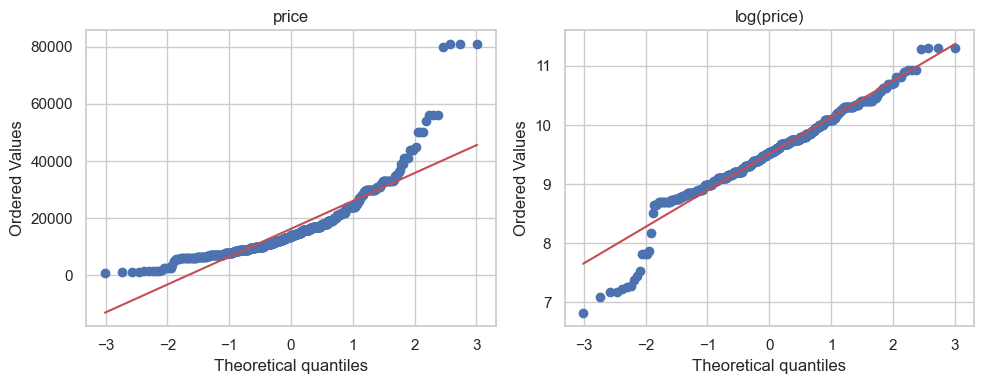

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(df["price"], dist="norm", plot=axes[0]);      axes[0].set_title("price")
stats.probplot(df["price_log"], dist="norm", plot=axes[1]);  axes[1].set_title("log(price)")
plt.tight_layout()
plt.show()

(_, _), (_, _, r_raw) = stats.probplot(df["price"], dist="norm")
(_, _), (_, _, r_log) = stats.probplot(df["price_log"], dist="norm")

**📊 Analysis**

- QQ straightness r: price = 0.895, log(price) = 0.977 (1 = perfectly normal).
- log(price) follows the line more closely, which is one more reason to model the log price.
- Dots curving away at the top end = a heavy right tail (flagship phones).

#### 5.1.4 Categorical and tier features: brand, RAM and storage
Count plots show how many listings each brand, RAM size and storage size has. Brands with very few listings are a warning: the model has little evidence for them.

brand,realme,Redmi,Infinix,vivo,POCO,Samsung,Motorola,TECNO,OPPO,Micromax,Google,OnePlus,Apple,itel,Nokia,Nothing,I Kall,iQOO,Lava
listings,97.0,74.0,65.0,60.0,58.0,53.0,45.0,16.0,16.0,14.0,9.0,5.0,5.0,3.0,3.0,2.0,2.0,2.0,2.0
share_pct,18.3,13.9,12.2,11.3,10.9,10.0,8.5,3.0,3.0,2.6,1.7,0.9,0.9,0.6,0.6,0.4,0.4,0.4,0.4


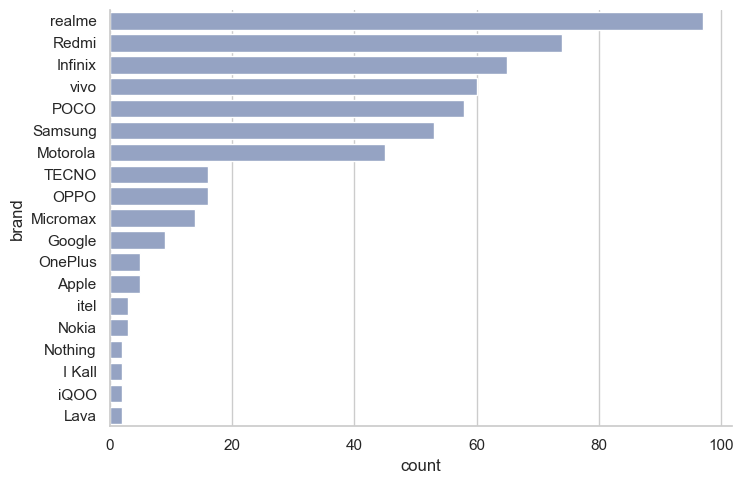

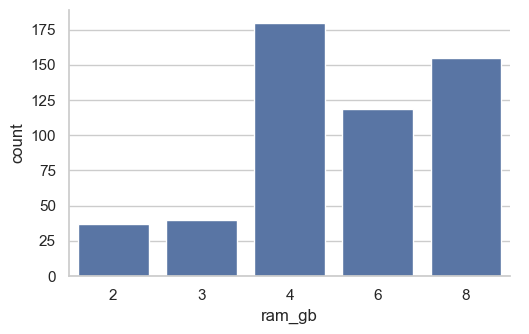

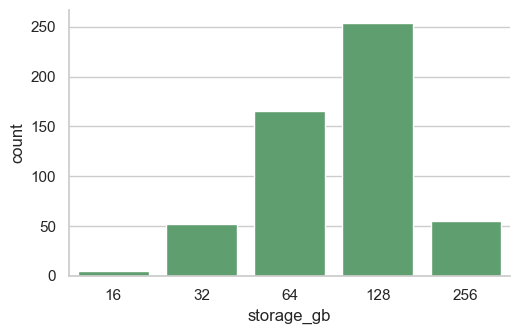

In [31]:
sns.catplot(data=df, kind="count", y="brand", order=df["brand"].value_counts().index, height=5, aspect=1.5, color="#8DA0CB")
sns.catplot(data=df, kind="count", x="ram_gb", height=3.5, aspect=1.5, color="#4C72B0")
sns.catplot(data=df, kind="count", x="storage_gb", height=3.5, aspect=1.5, color="#55A868")

brand_counts = df["brand"].value_counts()
display(brand_counts.to_frame("listings").assign(share_pct=(brand_counts / len(df) * 100).round(1)).T)

**📊 Analysis**

- Top 3 brands by listings: realme 18%, Redmi 14%, Infinix 12% -> together 44% of the data.
- Brands with fewer than 10 listings (9): ['Apple', 'Google', 'I Kall', 'Lava', 'Nokia', 'Nothing', 'OnePlus', 'iQOO', 'itel']. The model has little evidence for them, so predictions for these brands are less reliable.
- Most common RAM: 4 GB; most common storage: 128 GB.

#### 5.1.5 Univariate summary: what the single-feature view tells us
| Feature | What one-at-a-time analysis shows | How it is handled (Section 4) |
|---|---|---|
| price | right-skewed (skew 2.42; mean Rs 16,306 vs median Rs 13,999; heavy tails); log(price) is much closer to a bell curve (QQ r 0.977 vs 0.895) | model log(price) |
| battery_mah | 72 % of phones have exactly 5,000 mAh (skew -3.33, kurtosis 15.25, IQR = 0) | the raw number says little; a battery class was built (4.6) |
| ram_gb, storage_gb | only 5 distinct values each; 4 GB RAM (34 %) and 128 GB storage (48 %) are most common | treated as tiers; banded versions were built (4.6) |
| rear / front camera | half of the phones have a 50 MP rear camera; front camera is the most scattered column (CV 76 %, skew 2.49) | camera classes and totals were built (4.5, 4.6) |
| mobile_height_cm | the most uniform column (CV 12 %), but a few very small values (minimum 4.5 cm) pull the left tail (skew -5.44) | keep, use as a plain numeric feature |
| brand | realme, Redmi and Infinix are 44 % of the listings; 9 brands have fewer than 10 listings | brand tier and brand frequency were built (4.1); predictions for thin brands are less reliable |
| normality | none of the 7 numeric columns passes the normality test | rank-based statistics (Spearman) and tree models instead of bell-curve methods |

### 5.2 Bivariate analysis (two features at a time)
Now each feature is paired with price (and, where useful, with one other feature). Numeric-vs-price uses correlation and scatter plots; categorical-vs-price uses group medians, box plots and hypothesis tests.

#### 5.2.1 Numeric features against price

,Spearman correlation with price
front_camera_mp,0.808
storage_gb,0.767
ram_gb,0.732
rear_camera_mp,0.622
mobile_height_cm,0.207
battery_mah,-0.310


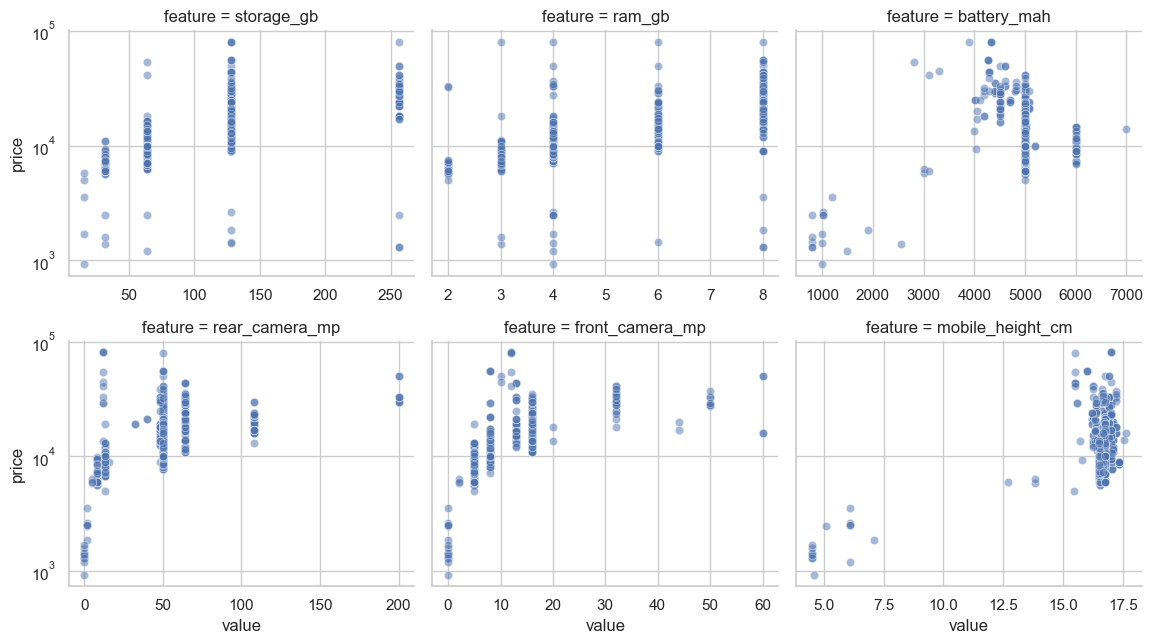

In [32]:
spec_cols = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm"]
spearman_raw = df[spec_cols].corrwith(df["price"], method="spearman").sort_values(ascending=False)
display(spearman_raw.rename("Spearman correlation with price").to_frame().round(3))

long_p = df[spec_cols + ["price"]].melt(id_vars="price", var_name="feature", value_name="value")
sns.relplot(data=long_p, x="value", y="price", col="feature", col_wrap=3, alpha=0.5, height=3.3, aspect=1.2,
            facet_kws={"sharex": False}).set(yscale="log")

**📊 Analysis**

- Strongest link with price: front_camera_mp (Spearman = +0.81).
- Moderate-to-strong relationships (|rho| >= 0.5): ['front_camera_mp', 'storage_gb', 'ram_gb', 'rear_camera_mp'].
- Weak relationships (|rho| < 0.2): none.
- Spearman correlation is used because it works for curved (not only straight-line) increasing or decreasing trends. Correlation shows association, not cause: specs usually rise together.

#### 5.2.2 Correlation three ways, significance and covariance
- **Pearson r** measures straight-line links and is sensitive to outliers.
- **Spearman rho** measures "does it go up when the other goes up" (ranks), so it ignores outliers and curves.
- **Kendall tau** also uses ranks, but counts pairs of phones that agree; values are usually smaller.
- **p-value** (from `pearsonr` / `spearmanr`): below 0.05 means the link is unlikely to be chance. With hundreds of rows even a weak link can be "significant", so always read it together with the size of r.
- **Covariance** says whether two columns move together, but it is in mixed units (e.g. mAh x rupees), so it **cannot be compared between pairs**. Correlation is covariance divided by both standard deviations, which removes the units.

,pearson,spearman,kendall
storage_gb,0.564,0.767,0.652
ram_gb,0.529,0.732,0.616
battery_mah,-0.046,-0.310,-0.257
rear_camera_mp,0.407,0.622,0.504
front_camera_mp,0.529,0.808,0.661
mobile_height_cm,0.216,0.207,0.152


,Pearson r,Pearson p,Spearman rho,Spearman p,significant (5 %)?
feature,,,,,
storage_gb,0.5635,0.0000,0.7666,0.0,yes
ram_gb,0.5295,0.0000,0.7319,0.0,yes
battery_mah,-0.0463,0.2874,-0.3098,0.0,yes
rear_camera_mp,0.4068,0.0000,0.6218,0.0,yes
front_camera_mp,0.5290,0.0000,0.8082,0.0,yes
mobile_height_cm,0.2156,0.0000,0.2069,0.0,yes


Covariance matrix (mixed units, do not compare between cells):


,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,mobile_height_cm,price
storage_gb,3705.5,75.7,-3280.0,1008.8,273.5,6.1,372096.9
ram_gb,75.7,4.0,-171.7,27.3,8.9,0.2,11436.4
battery_mah,-3280.0,-171.7,586577.0,4595.3,153.4,1294.7,-384228.9
rear_camera_mp,1008.8,27.3,4595.3,985.5,143.5,17.9,138514.7
front_camera_mp,273.5,8.9,153.4,143.5,82.9,4.2,52247.3
mobile_height_cm,6.1,0.2,1294.7,17.9,4.2,3.8,4534.9
price,372096.9,11436.4,-384228.9,138514.7,52247.3,4534.9,117658241.1


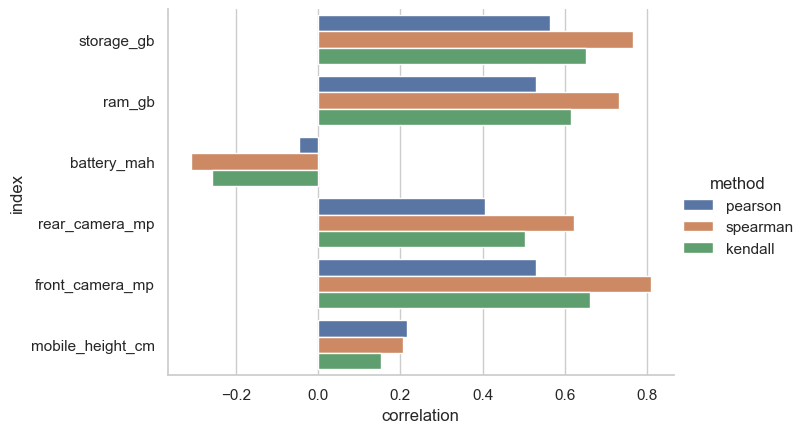

In [33]:
spec_num = ["storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm"]

corr_cmp = pd.DataFrame({m: df[spec_num].corrwith(df["price"], method=m) for m in ["pearson", "spearman", "kendall"]})
display(corr_cmp.round(3))

tests = []
for c in spec_num:
    r, p = stats.pearsonr(df[c], df["price"])
    rho, p_s = stats.spearmanr(df[c], df["price"])
    tests.append({"feature": c, "Pearson r": r, "Pearson p": p, "Spearman rho": rho, "Spearman p": p_s})
tests = pd.DataFrame(tests).set_index("feature")
tests["significant (5 %)?"] = np.where(tests["Spearman p"] < 0.05, "yes", "no")
display(tests.round(4))

print("Covariance matrix (mixed units, do not compare between cells):")
display(df[spec_num + ["price"]].cov().round(1))

sns.catplot(data=corr_cmp.reset_index().melt(id_vars="index", var_name="method", value_name="correlation"),
            kind="bar", y="index", x="correlation", hue="method", height=4.5, aspect=1.6)

**📊 Analysis**

- Strongest link with price: Pearson -> storage_gb (0.56); Spearman -> front_camera_mp (0.81); Kendall -> front_camera_mp (0.66).
- Features where Pearson and Spearman differ by more than 0.1: ['storage_gb', 'ram_gb', 'battery_mah', 'rear_camera_mp', 'front_camera_mp'] -> the link is curved or driven by a few extreme phones, so the straight-line r alone would mislead.
- 6 of 6 features have a statistically significant link with price (Spearman p < 0.05).
- Kendall values are smaller than Spearman by construction; compare the ORDER of the features, not the size.
- Covariance is shown for completeness (it feeds PCA and regression), but correlation is the number to compare.

#### 5.2.3 Categorical features against price
Bars show the **median** price of each RAM size and storage size (the median is not pulled up by a few flagship phones).

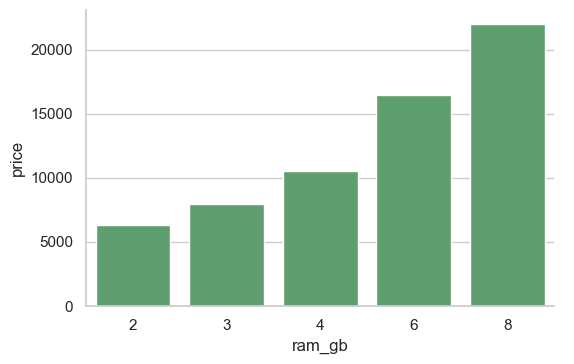

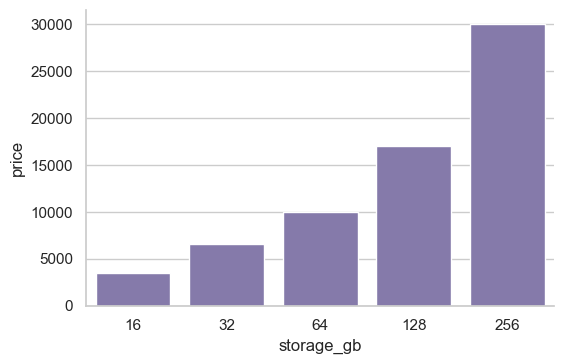

In [34]:
sns.catplot(data=df, kind="bar", x="ram_gb", y="price", estimator="median", errorbar=None, height=3.8, aspect=1.5, color="#55A868")
sns.catplot(data=df, kind="bar", x="storage_gb", y="price", estimator="median", errorbar=None, height=3.8, aspect=1.5, color="#8172B2")

brand_med = df.groupby("brand")["price"].median().sort_values()

**📊 Analysis**

- Median price rises from Rs 6,299 at 2 GB RAM to Rs 21,999 at 8 GB RAM.
- Median price rises from Rs 3,549 at 16 GB storage to Rs 29,999 at 256 GB storage.
- Cheapest brand by median price: Micromax (Rs 1,724); most expensive: Apple (Rs 80,999) -> a 47.0x gap, so brand is clearly linked to price (the next chart shows it).

Median price by brand (tall horizontal bars need a custom figure size).

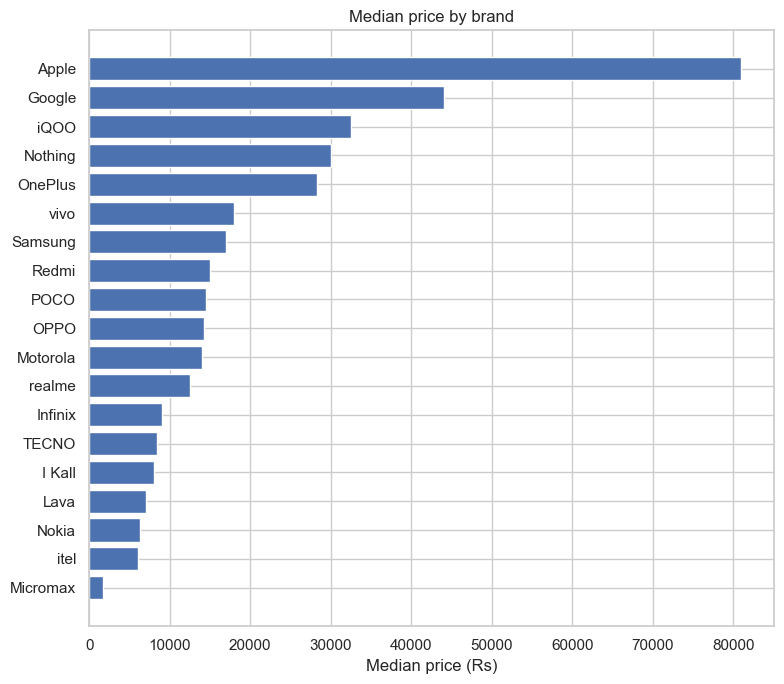

In [35]:
plt.figure(figsize=(8, 7))
plt.barh(brand_med.index, brand_med.values, color="#4C72B0")
plt.xlabel("Median price (Rs)")
plt.title("Median price by brand")
plt.tight_layout()
plt.show()

**📊 Analysis**

- Brands with the most price outliers: Samsung (6), Google (6), Apple (5).
- These outliers are premium brands, not errors, which confirms the decision to keep them.

#### 5.2.4 Price statistics by group, box plots and hypothesis tests
1. **Group statistics**: `groupby(column)["price"].agg([...])` gives count, mean, median, std, min, max for each group; `CV %` shows how scattered prices are *inside* each group.
2. **Box plots by group**: one box per RAM size, storage size, AI-lens yes/no and the 10 biggest brands. The price axis is on a **log scale** (`.set(yscale="log")`) so cheap and premium boxes are both readable.
3. **Tests**:
   - *Welch t-test* compares the mean price of two groups (no equal-spread assumption); *Mann-Whitney U* compares them by ranks, so it is safe with skewed prices.
   - *Chi-square test* checks whether two categorical columns are linked (here RAM and storage); *Cramer's V* = `sqrt(chi2 / (n x (smaller side - 1)))` turns it into a 0 to 1 strength.
4. **Outliers inside groups**: the earlier outlier count used all phones together. Counting again within each RAM size shows how many "outliers" are just normal prices for a bigger tier.

--- price statistics by ram_gb ---


,count,mean,median,std,min,max,CV %
ram_gb,,,,,,,
2,37,7865.0,6299.0,6034.0,4999,32999,77.0
3,40,9893.0,7994.0,11837.0,1375,80999,120.0
4,180,11890.0,10499.0,7835.0,920,80999,66.0
6,119,17459.0,16499.0,8261.0,1449,80999,47.0
8,155,24218.0,21999.0,11075.0,1299,79999,46.0


--- price statistics by storage_gb ---


,count,mean,median,std,min,max,CV %
storage_gb,,,,,,,
16,5,3393.0,3549.0,2084.0,920,5799,61.0
32,52,6749.0,6599.0,1707.0,1375,10989,25.0
64,165,10631.0,9999.0,4917.0,1199,53999,46.0
128,254,19670.0,16999.0,10719.0,1422,80999,54.0
256,55,28003.0,29999.0,12066.0,1299,79999,43.0


--- price statistics by ai_lens ---


,count,mean,median,std,min,max,CV %
ai_lens,,,,,,,
0,497,16749.0,13999.0,11047.0,920,80999,66.0
1,34,9828.0,8999.0,3020.0,6199,16999,31.0


--- price statistics, 10 biggest brands ---


,count,mean,median,std,min,max
brand,,,,,,
Micromax,14,2399.0,1724.0,1610.0,1199,5999
TECNO,16,8599.0,8368.0,1690.0,6794,13999
Infinix,65,10621.0,8999.0,3665.0,5999,17999
realme,97,13544.0,12499.0,5326.0,5999,32299
Motorola,45,16797.0,13999.0,10419.0,6799,49999
OPPO,16,16120.0,14249.0,6684.0,9499,29999
POCO,58,15726.0,14499.0,7276.0,5649,32999
Redmi,74,15985.0,14999.0,8163.0,920,32999
Samsung,53,21031.0,16999.0,13071.0,7299,79999


AI lens: median price Rs 8,999 with vs Rs 13,999 without; Welch t-test p = 1.68e-16, Mann-Whitney p = 2.25e-06
RAM vs storage: chi-square p = 3.29e-121, Cramer's V = 0.54
Price outliers judged on all phones together: 25; judged inside each RAM size: 36


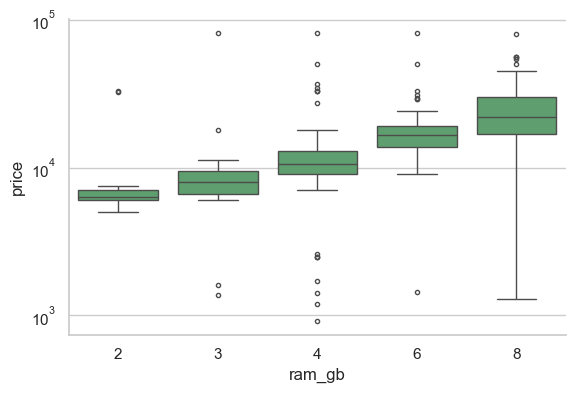

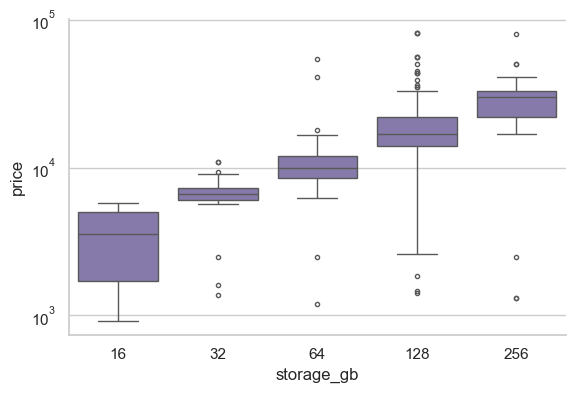

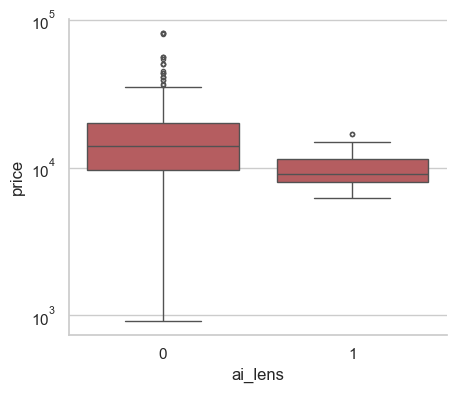

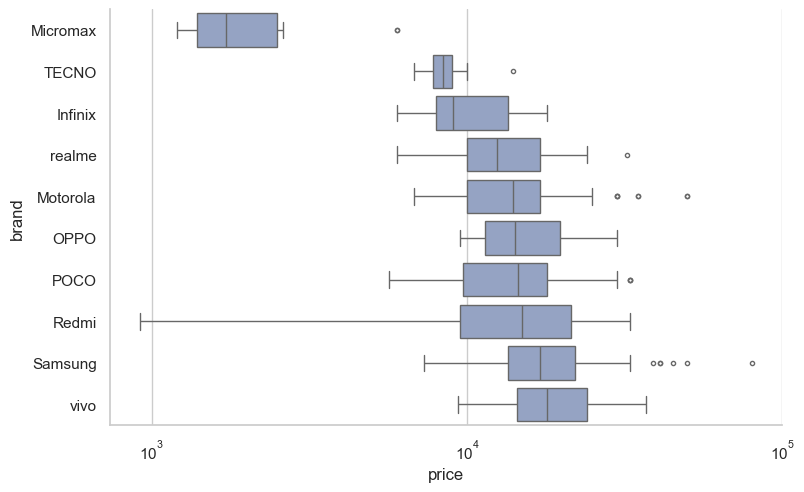

In [36]:
def group_stats(col):
    g = df.groupby(col)["price"].agg(["count", "mean", "median", "std", "min", "max"])
    g["CV %"] = g["std"] / g["mean"] * 100
    return g.round(0)

for col in ["ram_gb", "storage_gb", "ai_lens"]:
    print(f"--- price statistics by {col} ---")
    display(group_stats(col))

top_brands = df["brand"].value_counts().head(10).index
brand_order = df[df["brand"].isin(top_brands)].groupby("brand")["price"].median().sort_values().index
print("--- price statistics, 10 biggest brands ---")
display(df[df["brand"].isin(top_brands)].groupby("brand")["price"].agg(["count", "mean", "median", "std", "min", "max"]).round(0).loc[brand_order])

sns.catplot(data=df, kind="box", x="ram_gb", y="price", height=4, aspect=1.5, color="#55A868", fliersize=3).set(yscale="log")
sns.catplot(data=df, kind="box", x="storage_gb", y="price", height=4, aspect=1.5, color="#8172B2", fliersize=3).set(yscale="log")
sns.catplot(data=df, kind="box", x="ai_lens", y="price", height=4, aspect=1.2, color="#C44E52", fliersize=3).set(yscale="log")
sns.catplot(data=df[df["brand"].isin(top_brands)], kind="box", y="brand", x="price", order=brand_order,
            height=5, aspect=1.6, color="#8DA0CB", fliersize=3).set(xscale="log")

# tests
with_ai = df.loc[df["ai_lens"] == 1, "price"]
no_ai = df.loc[df["ai_lens"] == 0, "price"]
if len(with_ai) > 1 and len(no_ai) > 1:
    t_p = stats.ttest_ind(with_ai, no_ai, equal_var=False).pvalue      # Welch t-test: compares mean price, unequal spread allowed
    u_p = stats.mannwhitneyu(with_ai, no_ai).pvalue                    # Mann-Whitney U: compares ranks, safe for skewed prices
    print(f"AI lens: median price Rs {with_ai.median():,.0f} with vs Rs {no_ai.median():,.0f} without; Welch t-test p = {t_p:.3g}, Mann-Whitney p = {u_p:.3g}")
else:
    print("AI lens has only one group in this data, so no test is possible.")

table = pd.crosstab(df["ram_gb"], df["storage_gb"])
chi2, chi_p, _, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"RAM vs storage: chi-square p = {chi_p:.3g}, Cramer's V = {cramers_v:.2f}")

def count_out(x):
    a, b = iqr_fences(x)
    return int(((x < a) | (x > b)).sum())

within = int(df.groupby("ram_gb")["price"].apply(count_out).sum())
print(f"Price outliers judged on all phones together: {int(outliers.loc['price', 'IQR outliers'])}; judged inside each RAM size: {within}")

**📊 Analysis**

- AI lens: median price Rs 8,999 with vs Rs 13,999 without (Welch t-test p < 0.0001, Mann-Whitney p < 0.0001) -> the difference is statistically significant, but AI lens may just travel with higher-end specs.
- RAM vs storage: chi-square p < 0.0001, Cramer's V = 0.54 -> RAM and storage are strongly tied (bigger RAM usually comes with bigger storage), so they carry overlapping information.
- Price outliers when all phones are judged together: 25; when each RAM size is judged on its own: 36. No drop, so the outliers are not explained by RAM tier.
- Median price rises with every RAM step: yes; with every storage step: yes. Neighbouring boxes still overlap, so RAM or storage alone does not fix the price.
- Brand boxes: vivo has the highest median (Rs 17,999) and Micromax the lowest (Rs 1,724); the whole vivo box sits above the whole Micromax box, so brand separates prices strongly (used in Section 4.1).

#### 5.2.5 More bivariate plots: ECDF, violin, density and trend line
| Plot | Why it is here |
|---|---|
| ECDF of price (AI lens yes/no) | for any price on the x-axis, the curve shows the share of phones at or below it; the curve further to the right is the pricier group |
| Violin of log price by RAM | like a box plot, but the width also shows where most phones sit |
| Density of log price by storage | one curve per storage size; separated peaks = storage separates prices |
| Trend line (RAM vs log price) | the slope gives a rough "% price per extra GB" |

Trend line: each extra GB of RAM goes with about 20.9 % higher price


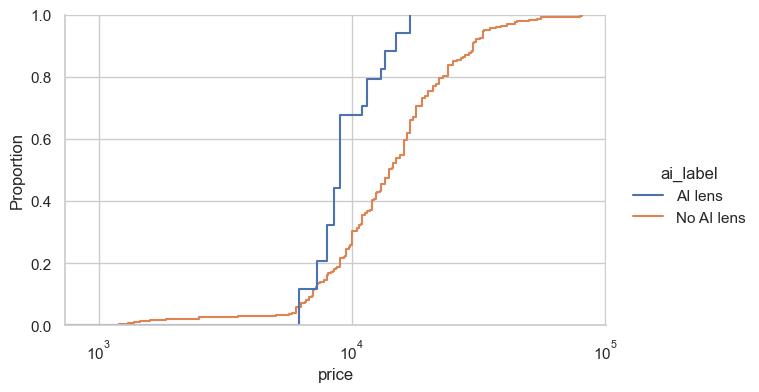

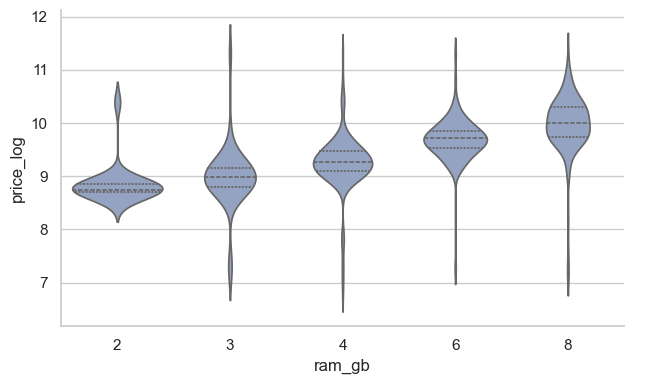

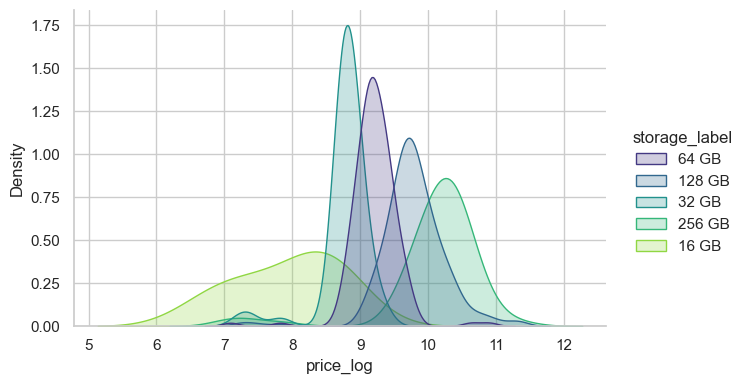

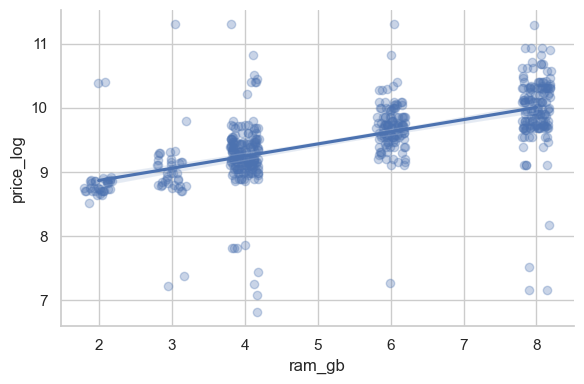

In [37]:
plot_df = df.assign(ai_label=df["ai_lens"].map({0: "No AI lens", 1: "AI lens"}),
                    storage_label=df["storage_gb"].astype(str) + " GB")

sns.displot(data=plot_df, x="price", hue="ai_label", kind="ecdf", height=4, aspect=1.6).set(xscale="log")
sns.catplot(data=df, kind="violin", x="ram_gb", y="price_log", inner="quartile", height=4, aspect=1.6, color="#8DA0CB")
sns.displot(data=plot_df, x="price_log", hue="storage_label", kind="kde", fill=True, common_norm=False,
            palette="viridis", height=4, aspect=1.6)
sns.lmplot(data=df, x="ram_gb", y="price_log", x_jitter=0.2, scatter_kws={"alpha": 0.3}, height=4, aspect=1.5)

slope = np.polyfit(df["ram_gb"], df["price_log"], 1)[0]            # change in log price per extra GB of RAM
print(f"Trend line: each extra GB of RAM goes with about {(np.exp(slope) - 1) * 100:.1f} % higher price")

**📊 Analysis**

- AI lens covers 6% of the phones; median price with AI lens Rs 8,999, without Rs 13,999.
- Straight-line trend: each extra GB of RAM goes with about 20.9 % higher price (rough guide only, because the trend is not perfectly straight).
- Reading guide (density plot): where the curves of different storage sizes hardly overlap, storage alone separates the prices well.

#### 5.2.6 Bivariate summary: how each feature relates to price
- **Numeric features:** all six specs have a statistically significant link with price (Spearman p < 0.05) and none is weak (|rho| < 0.2). Ranking by Spearman rho: front_camera_mp +0.81, storage_gb +0.77, ram_gb +0.73, rear_camera_mp +0.62, mobile_height_cm +0.21, battery_mah -0.31.
- **Battery is the odd one out:** its link with price is negative (rho = -0.31), so a bigger battery is not a premium signal on its own in this data.
- **Pearson vs Spearman:** they differ by more than 0.1 for 5 of the 6 specs, so the links are curved or driven by extreme phones; rank-based measures and log(price) are the safer choice.
- **RAM and storage:** the median price rises at every step (RAM: Rs 6,299 at 2 GB to Rs 21,999 at 8 GB; storage: Rs 3,549 at 16 GB to Rs 29,999 at 256 GB), but neighbouring boxes overlap, so neither fixes the price alone. A straight-line fit says each extra GB of RAM goes with about 20.9 % higher price.
- **Brand:** the median price differs 47-fold between the cheapest brand (Micromax, Rs 1,724) and the dearest (Apple, Rs 80,999). Among the 10 biggest brands vivo has the highest median (Rs 17,999).
- **AI lens:** phones with an AI lens (6 % of the data) are *cheaper* (median Rs 8,999 vs Rs 13,999, significant in both tests), so the label signals budget phones here, not a premium.
- **Outliers:** 25 price outliers overall (36 when judged inside each RAM size); they come mostly from Samsung, Google and Apple, so they are real premium phones and are kept.

### 5.3 Multivariate analysis (three or more features together)
Here the question is no longer "does this feature move with price?" but "which features move **with each other**, and what happens when several are looked at at once?" Overlapping features carry the same information twice, which matters for model building.

#### 5.3.1 Overlap between features: correlation heatmap and pair plot
The heatmap shows the Spearman correlation between every pair of numeric features (and log price). The pair plot draws every feature against every other, coloured by price quartile (`price_tier`, used for colouring only, never as a model feature).

Most overlapping pair of specs: storage_gb and ram_gb (|rho| = 0.74)


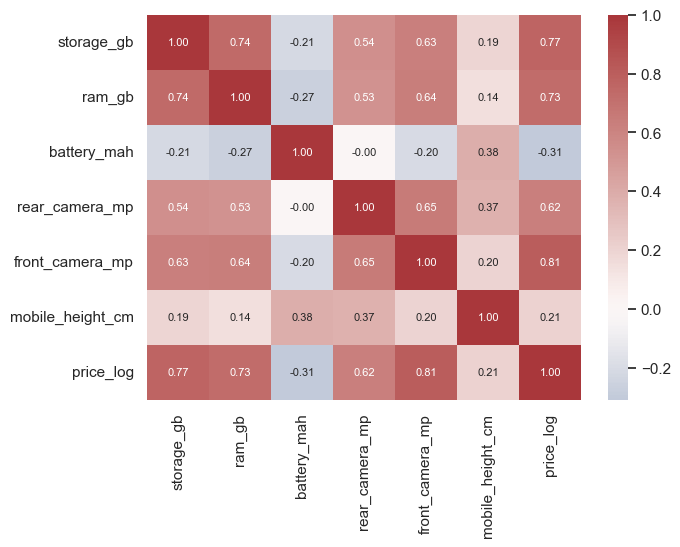

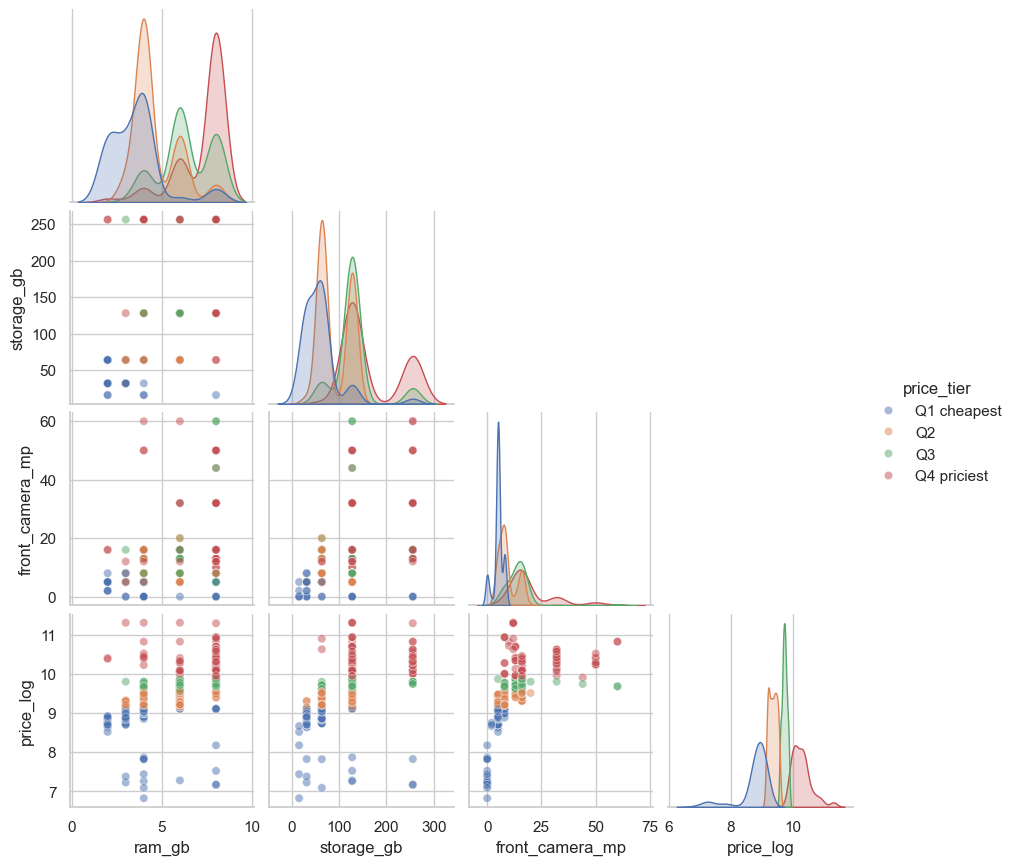

In [38]:
plt.figure(figsize=(7, 5))      # fresh figure, so this chart never draws on top of the previous one
sns.heatmap(df[spec_cols + ["price_log"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 8})

df["price_tier"] = pd.qcut(df["price"], 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 priciest"])      # used for colouring charts only, never as a feature
sns.pairplot(df, vars=["ram_gb", "storage_gb", "front_camera_mp", "price_log"], hue="price_tier", corner=True, height=2.2, plot_kws={"alpha": 0.5})

corr_pairs = df[spec_cols].corr(method="spearman").abs().where(~np.eye(len(spec_cols), dtype=bool)).stack()
best_pair = corr_pairs.idxmax()
print(f"Most overlapping pair of specs: {best_pair[0]} and {best_pair[1]} (|rho| = {corr_pairs.max():.2f})")

**📊 Analysis**

- The most overlapping pair of specs is storage_gb and ram_gb (|rho| = 0.74).
- The pair plot is coloured by price quartile: if the colours separate cleanly along a feature, that feature helps to tell cheap and expensive phones apart.
- Overlapping features carry the same information twice; linear models are most sensitive to that, tree models much less.

#### 5.3.2 Variance Inflation Factor (VIF)
VIF measures how well one feature can be predicted from **all the others together**: `VIF = 1 / (1 - R²)`, where R² comes from a linear regression of that feature on the rest.
- VIF close to 1 = the feature is independent of the others.
- VIF above 5 = notable overlap; above 10 = severe overlap (the feature is almost a copy of a mix of the others).

In [39]:
def vif_table(frame):
    # VIF = 1 / (1 - R^2) when one feature is predicted from all the others (above 5 = notable overlap, above 10 = severe)
    out = {}
    for c in frame.columns:
        others = frame.drop(columns=c)
        r2 = LinearRegression().fit(others, frame[c]).score(others, frame[c])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF").round(2).sort_values(ascending=False)

vif_base = vif_table(df[spec_cols])
display(vif_base.to_frame())

,VIF
mobile_height_cm,5.28
battery_mah,5.09
storage_gb,1.97
ram_gb,1.84
front_camera_mp,1.76
rear_camera_mp,1.69


**📊 Analysis**

- Features with VIF above 5: ['mobile_height_cm', 'battery_mah'].
- Some specs overlap strongly; this matters for linear models, so Ridge regression is included in Section 8.

#### 5.3.3 More multivariate plots: RAM x storage counts, strip plot and camera scatter
| Plot | Why it is here |
|---|---|
| Count heatmap RAM x storage | which RAM/storage combinations really exist |
| Strip plot (RAM x storage) | every single phone as a dot, so thin groups become visible |
| Rear vs front camera, coloured by price quartile | do the two cameras move together, and does colour separate along them? |

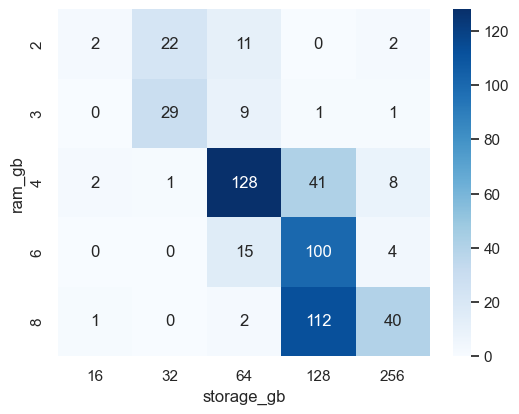

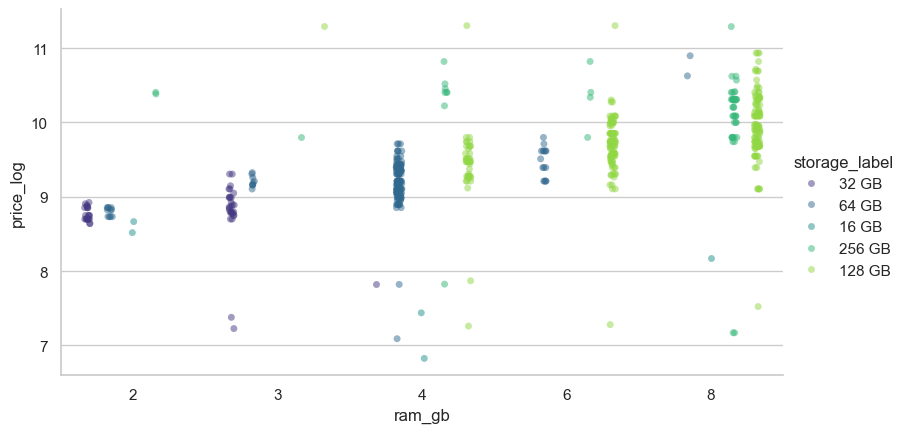

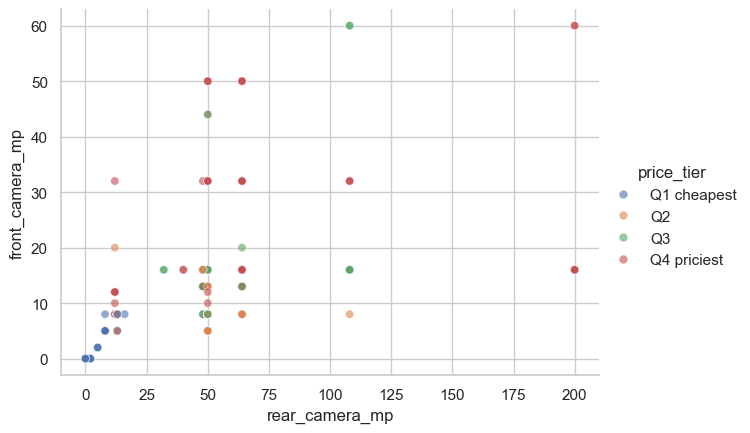

In [40]:
plt.figure(figsize=(6, 4.5))      # fresh figure, so this chart never draws on top of the previous one
sns.heatmap(pd.crosstab(df["ram_gb"], df["storage_gb"]), annot=True, fmt="d", cmap="Blues")
sns.catplot(data=plot_df, kind="strip", x="ram_gb", y="price_log", hue="storage_label", dodge=True, alpha=0.5,
            palette="viridis", height=4.5, aspect=1.8)
sns.relplot(data=df, x="rear_camera_mp", y="front_camera_mp", hue="price_tier", alpha=0.6, height=4.5, aspect=1.4)

**📊 Analysis**

- Most common RAM / storage combination: 4 GB RAM with 64 GB storage (24% of phones).
- Reading guide (strip plot): where the dots are few, any model has little evidence, the same warning as for thin brands in 4.1.4.

#### 5.3.4 Multivariate summary: how the features work together
- **Overlap:** RAM and storage are the most overlapping pair of specs (|rho| = 0.74; Cramer's V = 0.54), so they carry partly the same information. A combined feature such as `config_score` (4.5) captures them together.
- **VIF:** mobile_height_cm (5.28) and battery_mah (5.09) are just above the "notable overlap" line of 5; storage_gb (1.97), ram_gb (1.84), front_camera_mp (1.76) and rear_camera_mp (1.69) are low. No VIF is near 10, so there is no severe overlap. Ridge regression is still included in Section 8 as a safeguard.
- **Combinations:** 4 GB RAM with 64 GB storage is the most common pairing (24 % of the phones); many other RAM and storage pairings are rare or missing, so the model has little evidence there.
- **Reading across levels:** price is explained by several specs together (cameras, storage, RAM, brand), not by one feature. This is why Section 4 built combined features (scores, totals, ratios, interactions) and Sections 8 to 10 use models that can combine many features.

### 5.4 EDA findings and the engineered features that answer them

**📊 Analysis**

- Price is skewed (2.4) -> the models learn log(price).
- Processor text has 123 spellings -> already grouped into chip maker, tier, number and core type (4.3).
- Colour has 271 marketing names -> already grouped into base colour families (4.4).
- Brand strongly separates prices (47.0x gap) and 9 brands are tiny -> a brand tier and a brand frequency were built (4.1).
- RAM, storage and cameras behave like levels and move together -> combined and banded versions were built (4.5, 4.6).
- Battery is dominated by one value (72% of phones) -> battery class and battery per height were built (4.5, 4.6).
- Model names contain hints such as Pro, Plus, Ultra, Lite, 5G -> extracted as flags (4.2, 4.7).

## 6. Preprocessing (continued): encoding categorical variables
Models need numbers. The brief asks for a numeric format such as one-hot encoding. Different kinds of categories need different encodings:

| Kind of feature | Examples | Encoding used |
|---|---|---|
| Unordered categories | brand, processor_brand, colour_family, core_type, brand_tier, processor_tier | **One-hot** (one 0/1 column per category) |
| Ordered classes | rear_cam_class, front_cam_class, battery_class, ram_class, storage_class | One-hot in the models; **ordinal** (0, 1, 2...) shown below as an alternative |
| How common a value is | brand_count, model_variants | **Frequency** encoding (already a number). Used for exploration only: they are removed from the models, see 8.0 |
| Text with many spellings | model, colour, processor_raw | Not used directly; replaced by the grouped features of Section 4 |

In [41]:
one_hot = pd.get_dummies(df[all_features], columns=cat_features, dtype=int)
print(f"{len(all_features)} features -> {one_hot.shape[1]} columns after one-hot encoding")
display(one_hot.head())

order_map = {"rear_cam_class": ["basic", "entry", "mid", "high", "ultra"], "front_cam_class": ["basic", "entry", "mid", "high"],
             "battery_class": ["low", "standard", "large"], "ram_class": ["low", "mid", "high"], "storage_class": ["small", "medium", "large"]}
ordinal_demo = pd.DataFrame({c: df[c].map({v: i for i, v in enumerate(order)}) for c, order in order_map.items()})
display(ordinal_demo.head())

n_levels = {c: df[c].nunique() for c in cat_features}
print("Categories per categorical feature:", n_levels)

42 features -> 96 columns after one-hot encoding


,storage_gb,ram_gb,battery_mah,rear_camera_mp,front_camera_mp,mobile_height_cm,ai_lens,is_5g,brand_count,is_premium_brand,name_words,name_premium,name_lite,series_number,model_variants,model_colours,processor_number,colour_words,total_camera_mp,camera_balance,config_score,ram_x_storage,storage_per_ram,battery_per_cm,spec_score,basic_phone,flagship_spec,budget_spec,five_g_x_ram,premium_x_config,ai_x_rear_cam,brand_Apple,brand_Google,brand_I Kall,brand_Infinix,brand_Lava,brand_Micromax,brand_Motorola,brand_Nokia,brand_Nothing,brand_OPPO,brand_OnePlus,brand_POCO,brand_Redmi,brand_Samsung,brand_TECNO,brand_iQOO,brand_itel,brand_realme,brand_vivo,processor_brand_Apple,processor_brand_Google Tensor,processor_brand_MediaTek,processor_brand_Not specified,processor_brand_Qualcomm,processor_brand_Samsung Exynos,processor_brand_Unisoc,colour_family_Black,colour_family_Blue,colour_family_Gold/Copper,colour_family_Green,colour_family_Grey/Silver,colour_family_Other,colour_family_Purple/Pink,colour_family_Red/Orange/Yellow,colour_family_White,brand_tier_Challenger,brand_tier_Mainstream,brand_tier_Premium,brand_tier_Value,processor_tier_Entry,processor_tier_Flagship,processor_tier_Mid,processor_tier_Unknown,processor_tier_Upper-mid,core_type_octa,core_type_quad,core_type_unspecified,rear_cam_class_basic,rear_cam_class_entry,rear_cam_class_high,rear_cam_class_mid,rear_cam_class_ultra,front_cam_class_basic,front_cam_class_entry,front_cam_class_high,front_cam_class_mid,battery_class_large,battery_class_low,battery_class_standard,ram_class_high,ram_class_low,ram_class_mid,storage_class_large,storage_class_medium,storage_class_small
0,64,4,6000,13,5,16.76,1,0,65,0,3,0,0,7.0,3,3,9863.0,2,18,0.357143,8.0,256,16.0,357.995227,0.236817,0,0,1,0,0.0,13,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0
1,64,4,6000,13,5,16.76,1,0,65,0,3,0,0,7.0,3,3,9863.0,2,18,0.357143,8.0,256,16.0,357.995227,0.236817,0,0,1,0,0.0,13,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,0,1,0
2,128,8,5000,50,16,16.64,0,0,45,0,2,0,0,32.0,4,2,680.0,2,66,0.313725,10.0,1024,16.0,300.480769,0.716573,0,0,0,0,0.0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0
3,32,2,5000,8,5,16.56,0,0,58,0,2,0,0,50.0,5,2,0.0,2,13,0.555556,6.0,64,16.0,301.932367,0.084510,0,0,1,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1
4,128,8,5000,50,5,16.76,1,0,65,0,3,0,0,30.0,8,4,0.0,1,55,0.098039,10.0,1024,16.0,298.329356,0.561911,0,0,0,0,0.0,50,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,1,0


,rear_cam_class,front_cam_class,battery_class,ram_class,storage_class
0,1,1,2,1,1
1,1,1,2,1,1
2,2,2,1,2,1
3,1,1,1,0,0
4,2,1,1,2,1


Categories per categorical feature: {'brand': 19, 'processor_brand': 7, 'colour_family': 9, 'brand_tier': 4, 'processor_tier': 5, 'core_type': 3, 'rear_cam_class': 5, 'front_cam_class': 4, 'battery_class': 3, 'ram_class': 3, 'storage_class': 3}


**📊 Analysis**

- 42 features become 96 columns after one-hot encoding (31 numeric stay as they are; 11 categorical features expand into 65 0/1 columns).
- The categorical feature with the most categories is 'brand' (19 categories), which is why raw model/colour/processor text was grouped first: one-hot on 100+ spellings would create a very wide, sparse table.
- In the models (Section 8) the encoder sits INSIDE the pipeline, so categories are learned from the training data only. This avoids information from the test set leaking into training.
- Target encoding (replacing a category by its average price) was NOT used: it needs extra care to avoid leaking the price into the features.

## 7. Feature Extraction
**Task:** find the features that most strongly affect price using statistics, visualisations and feature-selection techniques *before* any model is trained. Five methods are used and then combined into one ranking:
1. Correlation (numeric features)
2. ANOVA / Kruskal-Wallis tests and η² (categorical features)
3. Filter methods: F-test and mutual information
4. Wrapper method: Recursive Feature Elimination (RFE)
5. Dimensionality reduction: PCA

### 7.1 Correlation analysis, numeric features

In [42]:
corr_all = df[num_features].corrwith(df["price_log"], method="spearman").fillna(0)
corr_sorted = corr_all.sort_values()
corr_table = pd.DataFrame({"Spearman": corr_all, "Pearson": df[num_features].corrwith(df["price_log"]).fillna(0)}).round(3)
display(corr_table.reindex(corr_all.abs().sort_values(ascending=False).index).head(10))

,Spearman,Pearson
spec_score,0.865,0.760
front_camera_mp,0.808,0.614
ram_x_storage,0.805,0.591
config_score,0.805,0.677
total_camera_mp,0.782,0.627
storage_gb,0.767,0.584
ram_gb,0.732,0.599
budget_spec,-0.732,-0.601
five_g_x_ram,0.642,0.531
is_5g,0.623,0.515


Spearman correlation of every numeric feature with log price.

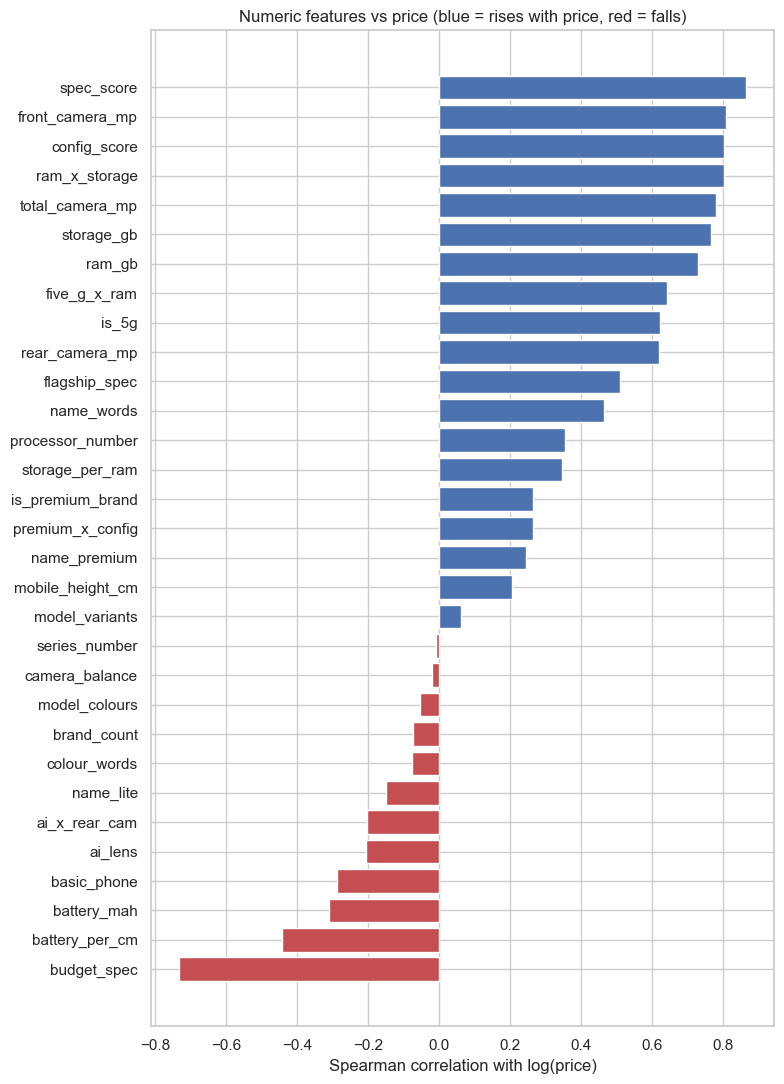

In [43]:
plt.figure(figsize=(8, 11))
plt.barh(corr_sorted.index, corr_sorted.values, color=np.where(corr_sorted.values >= 0, "#4C72B0", "#C44E52"))
plt.xlabel("Spearman correlation with log(price)")
plt.title("Numeric features vs price (blue = rises with price, red = falls)")
plt.tight_layout()
plt.show()

**📊 Analysis**

- Top 5 by |correlation|: spec_score (+0.86), front_camera_mp (+0.81), ram_x_storage (+0.81), config_score (+0.81), total_camera_mp (+0.78).
- 12 numeric features have |rho| >= 0.5 and 6 have |rho| < 0.1: ['brand_count', 'series_number', 'model_variants', 'model_colours', 'colour_words', 'camera_balance'].
- Features that FALL as price rises (rho < -0.1): ['battery_mah', 'ai_lens', 'name_lite', 'battery_per_cm', 'basic_phone', 'budget_spec', 'ai_x_rear_cam'].
- Limit of this method: it only measures straight-line or steadily rising relationships and cannot rank categorical features. The next methods cover both gaps.

### 7.2 Statistical tests, categorical features (does price differ between groups?)

,groups,ANOVA F,ANOVA p,Kruskal p,eta2
feature,,,,,
front_cam_class,4,322.9389,0.0000,0.0000,0.6477
processor_tier,5,172.9116,0.0000,0.0000,0.5680
rear_cam_class,5,148.5589,0.0000,0.0000,0.5305
brand,19,28.2961,0.0000,0.0000,0.4987
processor_brand,7,47.6931,0.0000,0.0000,0.3532
brand_tier,4,78.1375,0.0000,0.0000,0.3079
ram_class,3,111.1565,0.0000,0.0000,0.2963
battery_class,3,102.6722,0.0000,0.0000,0.2800
storage_class,3,97.5129,0.0000,0.0000,0.2697


<Axes: xlabel='eta2', ylabel='feature'>

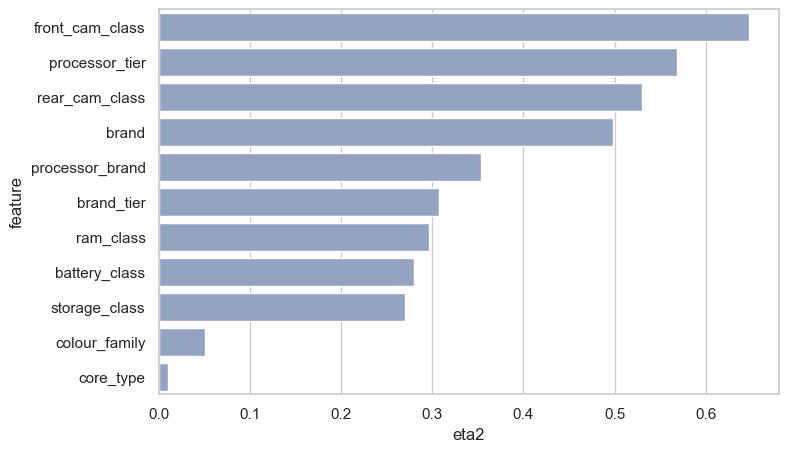

In [44]:
rows = []
for c in cat_features:
    groups = [g["price_log"].values for _, g in df.groupby(c) if len(g) > 1]
    try:
        F, pF = f_oneway(*groups); H, pH = kruskal(*groups)
    except ValueError:
        F = pF = pH = np.nan
    rows.append({"feature": c, "groups": df[c].nunique(), "ANOVA F": F, "ANOVA p": pF, "Kruskal p": pH, "eta2": eta_squared(c)})
cat_tests = pd.DataFrame(rows).set_index("feature").sort_values("eta2", ascending=False)
display(cat_tests.round(4))

plt.figure(figsize=(8, 5))      # fresh figure, so this chart never draws on top of the previous one

sns.barplot(data=cat_tests.reset_index(), x="eta2", y="feature", color="#8DA0CB")

**📊 Analysis**

- Categorical features whose price levels differ significantly between groups (ANOVA p < 0.05): 10 of 11.
- Not significant: ['core_type'].
- Strongest by η²: front_cam_class (0.65), processor_tier (0.57), rear_cam_class (0.53); weakest: core_type (0.010).
- ANOVA assumes roughly normal groups with similar spread; Kruskal-Wallis does not, so both are shown. When the two disagree, trust Kruskal-Wallis.
- A tiny p-value only says 'the groups are not identical'; η² says whether the difference is big enough to matter for pricing.

### 7.3 Filter methods: F-test and mutual information

In [45]:
F_vals, p_vals = f_regression(df[num_features], df["price_log"])
f_table = pd.DataFrame({"F": F_vals, "p-value": p_vals}, index=num_features).fillna(0).sort_values("F", ascending=False)

# mutual information works for numbers and categories and finds curved relationships
X_mi = df[all_features].copy()
for c in cat_features:
    X_mi[c] = X_mi[c].astype("category").cat.codes
mi_vals = mutual_info_regression(X_mi, df["price_log"], discrete_features=[c in cat_features for c in all_features], random_state=RANDOM_STATE)
mi = pd.Series(mi_vals, index=all_features).sort_values(ascending=False)

display(f_table.head(8).round(3))
display(mi.head(8).round(3).to_frame("mutual information"))

,F,p-value
spec_score,725.314,0.0
config_score,446.846,0.0
total_camera_mp,343.122,0.0
front_camera_mp,320.208,0.0
budget_spec,299.233,0.0
ram_gb,296.291,0.0
ram_x_storage,283.597,0.0
storage_gb,273.316,0.0


,mutual information
spec_score,1.165
total_camera_mp,1.011
camera_balance,0.956
ram_x_storage,0.941
config_score,0.940
front_camera_mp,0.790
processor_tier,0.716
battery_per_cm,0.698


**📊 Analysis**

- The F-test (straight-line signal) finds 25 of 31 numeric features significant at the 5% level.
- Mutual information (any kind of signal) ranks first: spec_score, total_camera_mp, camera_balance.
- Features with almost no mutual information (< 0.01): ['colour_family'].
- F-test and mutual information ask different questions: the F-test sees only straight-line patterns, mutual information also sees curves and category effects. Features that rank high in both are the safest.

### 7.4 Wrapper method: Recursive Feature Elimination (RFE)

In [46]:
X_oh = pd.get_dummies(df[all_features], columns=cat_features, dtype=int)
rfe = RFE(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), n_features_to_select=15, step=5)
rfe.fit(X_oh, df["price_log"])

def origin(col):
    # map a one-hot column ('brand_Samsung') back to its original feature ('brand')
    if col in num_features:
        return col
    for f in sorted(cat_features, key=len, reverse=True):
        if col.startswith(f + "_"):
            return f
    return col

rfe_rank = pd.Series(rfe.ranking_, index=X_oh.columns)
rfe_by_feature = rfe_rank.groupby(origin).min().reindex(all_features)       # 1 = kept to the end
selected = rfe_by_feature[rfe_by_feature == 1].index.tolist()
print("Features kept by RFE:", selected)

Features kept by RFE: ['battery_mah', 'rear_camera_mp', 'front_camera_mp', 'mobile_height_cm', 'brand_count', 'processor_number', 'total_camera_mp', 'camera_balance', 'config_score', 'spec_score', 'basic_phone', 'five_g_x_ram', 'processor_tier', 'rear_cam_class']


**📊 Analysis**

- RFE repeatedly trains a Random Forest and removes the weakest columns until 15 of the 96 one-hot columns remain.
- Original features that survived: ['battery_mah', 'rear_camera_mp', 'front_camera_mp', 'mobile_height_cm', 'brand_count', 'processor_number', 'total_camera_mp', 'camera_balance', 'config_score', 'spec_score', 'basic_phone', 'five_g_x_ram', 'premium_x_config', 'processor_tier', 'rear_cam_class'].
- Why a wrapper: unlike a filter, it judges features by how useful they are INSIDE a model, so it can drop a feature that only repeats another one.

### 7.5 Dimensionality reduction: numeric features

Components needed to keep 90% of the variance: 14


,PC1 loading
spec_score,0.33
config_score,0.31
ram_x_storage,0.30
storage_gb,0.29
ram_gb,0.28


PC1 vs log(price): rho = +0.88;  PC2 vs log(price): rho = -0.34


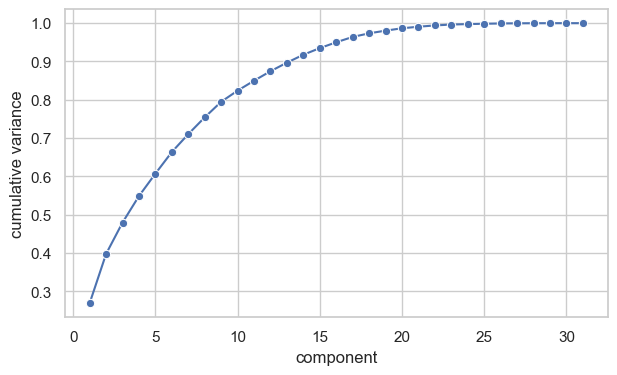

In [47]:
Xs = StandardScaler().fit_transform(df[num_features])
pca = PCA().fit(Xs)
evr = pd.Series(pca.explained_variance_ratio_)
cum_var = evr.cumsum()
pca_plot = pd.DataFrame({"component": np.arange(1, len(evr) + 1), "cumulative variance": cum_var.values})
plt.figure(figsize=(7, 4))      # fresh figure, so this chart never draws on top of the previous one
sns.lineplot(data=pca_plot, x="component", y="cumulative variance", marker="o")

scores = pca.transform(Xs)
loadings = pd.Series(pca.components_[0], index=num_features).sort_values(key=abs, ascending=False)
n90 = int((cum_var < 0.90).sum() + 1)
print(f"Components needed to keep 90% of the variance: {n90}")
display(loadings.head(5).to_frame("PC1 loading").round(2))
print(f"PC1 vs log(price): rho = {spearmanr(scores[:, 0], df['price_log'])[0]:+.2f};  PC2 vs log(price): rho = {spearmanr(scores[:, 1], df['price_log'])[0]:+.2f}")

**📊 Analysis**

- The first component alone captures 27% of the variation in the numeric features; 14 components capture 90%.
- PC1 is built mostly from: spec_score (+0.33), config_score (+0.31), ram_x_storage (+0.30), storage_gb (+0.29).
- PC1 correlates with log(price) at rho = +0.88 and PC2 at -0.34.
- 31 numeric features can be summarised by 14 components, which confirms many features repeat each other.
- DECISION: PCA is used only to understand the structure. The models keep the original features, because components are hard to explain to a business and PCA cannot handle the categorical features.

### 7.6 Consolidated feature ranking

In [48]:
assoc = {f: (abs(corr_all[f]) if f in num_features else float(np.sqrt(eta_squared(f)))) for f in all_features}
rank_table = pd.DataFrame({"association": pd.Series(assoc), "mutual_info": mi, "rfe_rank": rfe_by_feature}).loc[all_features]
rank_table["rank_association"] = rank_table["association"].rank(ascending=False)
rank_table["rank_mi"] = rank_table["mutual_info"].rank(ascending=False)
rank_table["rank_rfe"] = rank_table["rfe_rank"].rank(ascending=True, method="min")
rank_table["avg_rank"] = rank_table[["rank_association", "rank_mi", "rank_rfe"]].mean(axis=1)
extraction_rank = rank_table.sort_values("avg_rank")
display(extraction_rank.head(12).round(3))

,association,mutual_info,rfe_rank,rank_association,rank_mi,rank_rfe,avg_rank
spec_score,0.865,1.165,1,1.0,1.0,1.0,1.000
front_camera_mp,0.808,0.790,1,2.0,6.0,1.0,3.000
total_camera_mp,0.782,1.011,1,6.0,2.0,1.0,3.000
config_score,0.805,0.940,1,3.5,5.0,1.0,3.167
processor_tier,0.754,0.716,1,8.0,7.0,1.0,5.333
ram_x_storage,0.805,0.941,3,3.5,4.0,16.0,7.833
rear_camera_mp,0.622,0.689,1,15.0,10.0,1.0,8.667
rear_cam_class,0.728,0.567,1,11.0,15.0,1.0,9.000
five_g_x_ram,0.642,0.486,1,13.0,17.0,1.0,10.333
processor_number,0.356,0.679,1,24.0,12.0,1.0,12.333


Average rank of the 20 best features (lower = more important).

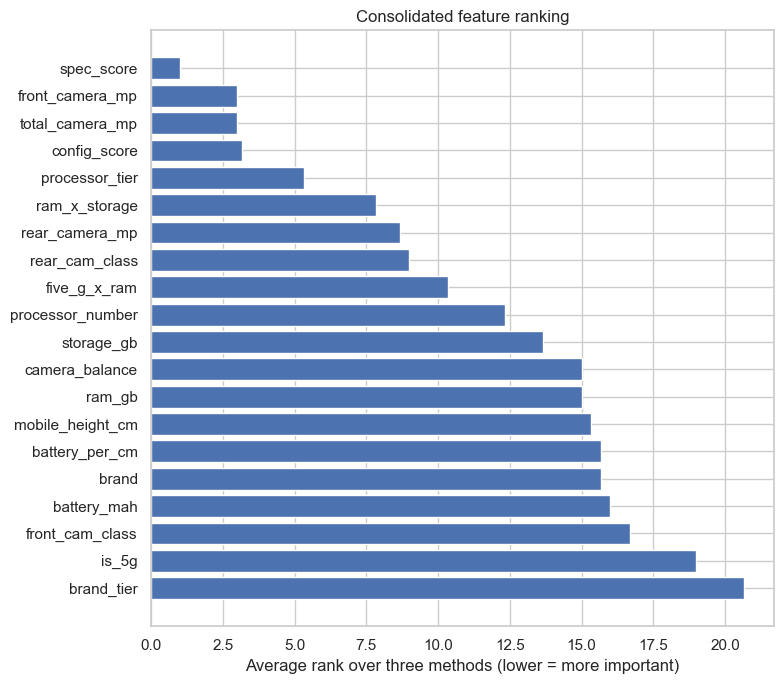

In [49]:
top20 = extraction_rank.head(20)["avg_rank"]
plt.figure(figsize=(8, 7))
plt.barh(top20.index, top20.values, color="#4C72B0")
plt.gca().invert_yaxis()
plt.xlabel("Average rank over three methods (lower = more important)")
plt.title("Consolidated feature ranking")
plt.tight_layout()
plt.show()

**📊 Analysis**

- Three views are combined: association strength (|rho| for numbers, sqrt(η²) for categories), mutual information, and RFE.
- Top 5 features: spec_score, front_camera_mp, total_camera_mp, config_score, processor_tier.
- Weakest 5 (candidates to drop): core_type, ai_lens, colour_words, colour_family, name_lite.
- 7 of the top 10 are engineered features: ['spec_score', 'total_camera_mp', 'config_score', 'processor_tier', 'ram_x_storage', 'rear_cam_class', 'five_g_x_ram'].
- This ranking is the 'hypothesis'. Section 10 checks whether a trained model agrees with it.

### Why feature extraction matters here
- **Fewer, clearer drivers:** the business can act on a handful of features instead of 40+.
- **Less noise and overlap:** dropping repeated or empty features makes models more stable.
- **Evidence before modelling:** if the same features rank high in correlation, mutual information, RFE and later in the trained model, the finding does not depend on one technique.

## 8. Model Building
**Task:** audit the features for leakage, split into training and test sets **by phone model**, and build the models. Five algorithms plus a baseline are compared. Each model learns log(price) internally and returns answers in rupees.

### 8.0 Leakage and data-quality audit
Two questions are asked before any model is trained:

1. **Is every feature something we would know when pricing a phone?** A feature may not use the price, and it may not use information from other rows that are later used as the test set.
2. **Can near-copies of the same listing end up on both sides of the split?** The file holds the same phone in several colours, with identical specs and price. If one colour is in training and another in the test set, the model is not predicting a new phone, it is recognising one it has already seen.

The table below records the decision for every group of features.

In [50]:
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit, learning_curve

# Features used for EDA and feature extraction (Sections 5-7) stay as they were; the models get the audited list.
eda_num_features, eda_cat_features, eda_all_features = list(num_features), list(cat_features), list(all_features)

DATASET_COUNT_FEATURES = ["brand_count", "model_variants", "model_colours"]     # removed from the models (see table)
num_features = [f for f in eda_num_features if f not in DATASET_COUNT_FEATURES]
cat_features = list(eda_cat_features)
all_features = num_features + cat_features
TARGET = "price"

# guard rail: nothing built from the price may reach the models.
# spec_suspect uses the price (same model + same price but two RAM sizes), so it is a data-quality flag only.
forbidden = {"price", "price_log", "spec_suspect"}
assert not forbidden & set(all_features), "a price-derived column is in the model feature list"

# spec_score: v7 ranked every phone against ALL rows (test rows included). Replace it by a row-independent index.
df["spec_score_v7"] = df["spec_score"]                                    # kept only to re-create the v7 result in 9.1a
SPEC_REF = {"ram_gb": 16, "storage_gb": 512, "rear_camera_mp": 108, "front_camera_mp": 32}   # fixed round reference values of a high-end phone, not fitted on this file
df["spec_score"] = np.mean([np.clip(np.log1p(df[c]) / np.log1p(ref), 0, 1) for c, ref in SPEC_REF.items()], axis=0)
rho_spec = spearmanr(df["spec_score"], df["spec_score_v7"])[0]

audit_rows = [
    ("Original specs: storage, RAM, battery, cameras, height, AI lens", "Read straight from the listing", "No", "Kept"),
    ("brand, brand_tier, is_premium_brand", "Brand = first word of the model name; tier = fixed market-position list written down by hand (not based on price)", "No", "Kept"),
    ("name_words, name_premium, name_lite, series_number", "Text rules on the model name", "No", "Kept"),
    ("Processor family, tier, number, core type", "Text rules on the processor string", "No", "Kept"),
    ("colour_family, colour_words", "Text rules on the colour name", "No", "Kept"),
    ("Sums, ratios, log2 scores, interactions, banded classes, 5G flag", "Arithmetic on the same row; band cut-offs are fixed numbers", "No", "Kept"),
    ("spec_score", "Percentile rank of RAM, storage and cameras. In v7 it was ranked over ALL rows, test rows included", "Yes (other rows' values)", "Kept, but redefined as a fixed-scale index (log of each spec divided by a fixed reference value), so a phone's score depends on that phone only"),
    ("brand_count, model_variants, model_colours", "Counts of listings per brand, per model and colours per model in THIS file", "Yes (counts test rows too)", "REMOVED from the models: they measure how many rows the file happens to hold, not a property of a phone, and are unknown for a new phone"),
    ("price, price_log, spec_suspect", "Target, or built with the target", "Yes", "Never in the feature list (checked by an assert)"),
]
display(pd.DataFrame(audit_rows, columns=["Feature(s)", "How it is built", "Uses other rows?", "Decision"]))

# near-duplicates: same phone model and specs and price, only the colour differs
spec_cols = ["model", "storage_gb", "ram_gb", "battery_mah", "rear_camera_mp", "front_camera_mp", "mobile_height_cm",
             "ai_lens", "processor_raw", "price"]
df["phone_group"] = df["model"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)     # one id per phone model
colour_only_dups = int(df.duplicated(subset=spec_cols).sum())
n_groups = df["phone_group"].nunique()
print(f"Exact duplicate rows were already removed in 3.4. Rows that repeat another row in everything except the colour: "
      f"{colour_only_dups} of {len(df)} ({colour_only_dups / len(df):.0%}).")
print(f"spec_score redefined: rank correlation with the v7 version {rho_spec:.3f}; correlation with log(price) {spearmanr(df['spec_score'], df['price_log'])[0]:+.2f} (v7: {spearmanr(df['spec_score_v7'], df['price_log'])[0]:+.2f}).")
print(f"Distinct phone models (normalised names): {n_groups}; median listings per model: {df.groupby('phone_group').size().median():.0f}, "
      f"largest: {df.groupby('phone_group').size().max()}.")

,Feature(s),How it is built,Uses other rows?,Decision
0,"Original specs: storage, RAM, battery, cameras...",Read straight from the listing,No,Kept
1,"brand, brand_tier, is_premium_brand",Brand = first word of the model name; tier = f...,No,Kept
2,"name_words, name_premium, name_lite, series_nu...",Text rules on the model name,No,Kept
3,"Processor family, tier, number, core type",Text rules on the processor string,No,Kept
4,"colour_family, colour_words",Text rules on the colour name,No,Kept
5,"Sums, ratios, log2 scores, interactions, bande...",Arithmetic on the same row; band cut-offs are ...,No,Kept
6,spec_score,"Percentile rank of RAM, storage and cameras. I...",Yes (other rows' values),"Kept, but redefined as a fixed-scale index (lo..."
7,"brand_count, model_variants, model_colours","Counts of listings per brand, per model and co...",Yes (counts test rows too),REMOVED from the models: they measure how many...
8,"price, price_log, spec_suspect","Target, or built with the target",Yes,Never in the feature list (checked by an assert)


Exact duplicate rows were already removed in 3.4. Rows that repeat another row in everything except the colour: 216 of 531 (41%).
spec_score redefined: rank correlation with the v7 version 0.982; correlation with log(price) +0.87 (v7: +0.86).
Distinct phone models (normalised names): 177; median listings per model: 2, largest: 15.


**Reading the audit**

- Three counting features were removed from the models, and `spec_score` no longer depends on other rows (fixed-scale index instead of a percentile rank over all rows). Everything else is rule-based on the single row, so it cannot leak.
- The colour-only repeats are the main danger for evaluation. They are kept in the data (they are real listings), but the split below keeps every listing of a phone model on **one** side, so a test phone is always a phone the model has never seen.
- Feature **selection** in Section 7 (correlation, F-test, mutual information, RFE) used the whole file, but it only ranks features for discussion: the models below use the full audited list, not a subset chosen with the test rows.

### 8.1 Train / test split by phone model (80 / 20)
`GroupShuffleSplit` puts all listings of one phone model (all colours and variants) into either the training or the test set. This is the split to trust when the question is "how well do we price a **new** phone?". The notebook also builds an ordinary random split, only to show how optimistic it is.

In [51]:
X = df[all_features]
y = df[TARGET]
groups_all = df["phone_group"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_pos, test_pos = next(splitter.split(X, y, groups_all))
X_train, X_test = X.iloc[train_pos], X.iloc[test_pos]
y_train, y_test = y.iloc[train_pos], y.iloc[test_pos]
GROUPS_TRAIN, GROUPS_TEST = groups_all.iloc[train_pos], groups_all.iloc[test_pos]

# --- checks that the split really is clean ---
assert set(GROUPS_TRAIN).isdisjoint(GROUPS_TEST), "a phone model is on both sides of the split"
train_keys = {tuple(r) for r in X_train.astype(str).to_numpy()}
same_feature_row = sum(tuple(r) in train_keys for r in X_test.astype(str).to_numpy())

# --- the same checks for an ordinary random split, for comparison ---
Xr_train, Xr_test = train_test_split(X, test_size=0.20, random_state=RANDOM_STATE)
rand_sibling = groups_all.loc[Xr_test.index].isin(groups_all.loc[Xr_train.index]).mean()
rand_keys = {tuple(r) for r in Xr_train.astype(str).to_numpy()}
rand_same_row = sum(tuple(r) in rand_keys for r in Xr_test.astype(str).to_numpy())

premium_tier = df["brand_tier"] == "Premium"
split_table = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "phone models": [GROUPS_TRAIN.nunique(), GROUPS_TEST.nunique()],
    "median price (Rs)": [y_train.median(), y_test.median()],
    "price above Rs 40,000": [int((y_train > 40000).sum()), int((y_test > 40000).sum())],
    "Premium-brand rows": [int(premium_tier.loc[X_train.index].sum()), int(premium_tier.loc[X_test.index].sum())],
}, index=["train", "test"])
display(split_table)
display(Markdown(f"""**📊 Analysis**

- Grouped split: {len(X_train)} training rows and {len(X_test)} test rows. **No phone model appears on both sides** (checked by an assert), and {same_feature_row} test rows have a feature-identical twin in training.
- For comparison, an ordinary random split of the same size puts **{rand_sibling:.0%} of the test rows next to a listing of the same phone model** in training, and {rand_same_row} test rows are feature-identical to a training row. That is why random-split scores look better than reality.
- The test set holds {int((y_test > 40000).sum())} phone(s) above Rs 40,000 and {int(premium_tier.loc[X_test.index].sum())} Premium-brand rows. With so few expensive phones, **any single split is noisy**: Section 9.1a repeats the split many times to show how much."""))

,rows,phone models,median price (Rs),"price above Rs 40,000",Premium-brand rows
train,427,141,13999.0,17,14
test,104,36,12989.5,1,0


**📊 Analysis**

- Grouped split: 427 training rows and 104 test rows. **No phone model appears on both sides** (checked by an assert), and 0 test rows have a feature-identical twin in training.
- For comparison, an ordinary random split of the same size puts **88% of the test rows next to a listing of the same phone model** in training, and 4 test rows are feature-identical to a training row. That is why random-split scores look better than reality.
- The test set holds 1 phone(s) above Rs 40,000 and 0 Premium-brand rows. With so few expensive phones, **any single split is noisy**: Section 9.1a repeats the split many times to show how much.

### 8.2 Model pipelines and training
All preprocessing (scaling, one-hot encoding) sits **inside** the pipeline, so it is learned from the training rows only.

In [52]:
def make_model(regressor, scale=False, num=None, cat=None):
    num = num_features if num is None else num
    cat = cat_features if cat is None else cat
    pre = ColumnTransformer([("num", StandardScaler() if scale else "passthrough", list(num)),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))])
    pipe = Pipeline([("pre", pre), ("reg", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

models = {
    "Baseline (median)": make_model(DummyRegressor(strategy="median")),
    "Linear Regression": make_model(LinearRegression(), scale=True),
    "Ridge":             make_model(Ridge(alpha=3.0), scale=True),
    "Decision Tree":     make_model(DecisionTreeRegressor(max_depth=8, min_samples_leaf=3, random_state=RANDOM_STATE)),
    "Random Forest":     make_model(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE)),
}
for m in models.values():
    m.fit(X_train, y_train)

**📊 Analysis**

- Six models are trained on the training rows only: Baseline (median), Linear Regression, Ridge, Decision Tree, Random Forest, Gradient Boosting.
- The baseline always predicts the median price; every real model has to beat it.
- Linear Regression and Ridge get scaled numbers; the tree models do not need scaling.
- Because every feature is now either a single-row rule or a fixed-scale index, no test row can influence a feature value; the only things learned from data (scaling, encoding, model weights) are learned inside the pipeline from training rows.

## 9. Model Evaluation
**Task:** judge how accurately the models predict the price of **phone models they have never seen**. Every model is judged with the same four metrics: **MAE** (average error in rupees), **RMSE** (punishes big misses), **R²** (share of price variation explained) and **MAPE** (average error as % of price).

**Rules followed in this section**
1. One split: the grouped training / test split of 8.1. Nothing else is used to compare models.
2. Models are **chosen and tuned only on the training rows**, with cross-validation in which whole phone models are held out (grouped CV). The test set is looked at once, after the choice is made.
3. Tuned models are scored with **nested** grouped CV, so a tuned model does not get an optimistic score for settings that were picked on the same folds.

**What this section contains:** 9.1 held-out test results, 9.1a how much the evaluation design matters, 9.2 grouped cross-validation, 9.3 tuning, 9.4 model selection, 9.5 value of the engineered features, 9.6 final model on the test set, 9.7 residual analysis, 9.8 comparison table, 9.9 where the data is thin.

### 9.1 Held-out test results (grouped split, default settings)

,MAE,RMSE,R2,MAPE %,Train R2
Gradient Boosting,2256.395,4963.075,0.530,13.826,0.992
Ridge,2570.880,4528.939,0.609,16.045,0.888
Random Forest,2612.378,4112.031,0.678,15.496,0.934
Linear Regression,2700.542,5392.441,0.446,15.949,0.923
Decision Tree,3163.386,5546.658,0.413,17.836,0.976
Baseline (median),5583.817,7354.025,-0.031,38.954,-0.049


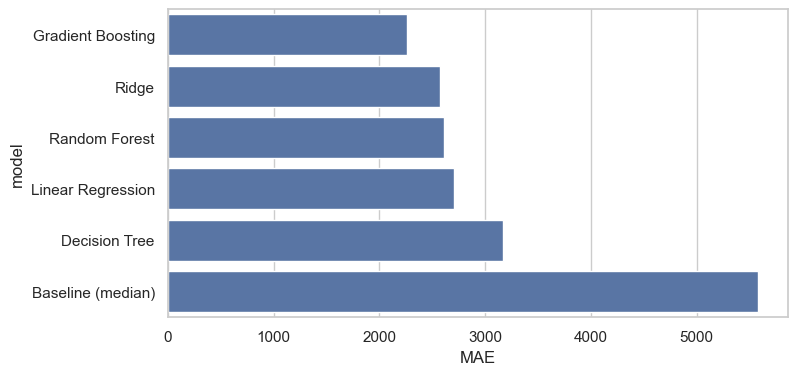

In [53]:
def fold_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, float)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE %": np.mean(np.abs(y_true - y_pred) / y_true) * 100}

def evaluate(model, X_part, y_part):
    return fold_metrics(y_part, model.predict(X_part))

test_res = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in models.items()}).T
train_res = pd.DataFrame({n: evaluate(m, X_train, y_train) for n, m in models.items()}).T
results = test_res.join(train_res[["R2"]].rename(columns={"R2": "Train R2"})).sort_values("MAE")
display(results.round(3))
plt.figure(figsize=(8, 4))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=results.reset_index(), x="MAE", y="index", color="#4C72B0")
plt.ylabel("model")

base_mae = results.loc["Baseline (median)", "MAE"]
best_on_split = results.drop("Baseline (median)").index[0]          # information only: the final model is NOT chosen with this

In [54]:
r = results.drop("Baseline (median)")
gap_txt = ", ".join(f"{n} {r.loc[n, 'Train R2'] - r.loc[n, 'R2']:+.2f}" for n in r.index)
display(Markdown(f"""**📊 Analysis**

- On the held-out phone models the lowest MAE of the default models is **{best_on_split}** (MAE Rs {r.loc[best_on_split, 'MAE']:,.0f}, RMSE Rs {r.loc[best_on_split, 'RMSE']:,.0f}, R² {r.loc[best_on_split, 'R2']:.2f}, MAPE {r.loc[best_on_split, 'MAPE %']:.1f}%). This is a single split with {len(X_test)} rows, so it is **not** used to pick the final model (see 9.4).
- The baseline MAE is Rs {base_mae:,.0f}; {best_on_split} removes {1 - r.loc[best_on_split, 'MAE'] / base_mae:.0%} of that error.
- RMSE is {r.loc[best_on_split, 'RMSE'] / r.loc[best_on_split, 'MAE']:.1f}x the MAE: a few phones are predicted far worse than average, usually expensive ones.
- Overfitting check (train R² minus test R²): {gap_txt}. A gap above 0.1 means the model memorised part of the training data."""))

**📊 Analysis**

- On the held-out phone models the lowest MAE of the default models is **Gradient Boosting** (MAE Rs 2,209, RMSE Rs 5,143, R² 0.50, MAPE 13.5%). This is a single split with 104 rows, so it is **not** used to pick the final model (see 9.4).
- The baseline MAE is Rs 5,584; Gradient Boosting removes 60% of that error.
- RMSE is 2.3x the MAE: a few phones are predicted far worse than average, usually expensive ones.
- Overfitting check (train R² minus test R²): Gradient Boosting +0.50, Ridge +0.28, Random Forest +0.25, Linear Regression +0.48, Decision Tree +0.58. A gap above 0.1 means the model memorised part of the training data.

### 9.1a How much does the evaluation design matter?
The same Gradient Boosting model is scored three ways. The first row re-runs the **v7 pipeline** (random split, old features, `spec_score` ranked on all rows). The other rows change one thing at a time. The last two blocks repeat the split 20 times to show how much a single split can move.

In [54]:
GB_PARAMS = dict(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE)

legacy_num = ["spec_score_v7" if f == "spec_score" else f for f in eda_num_features]       # v7 spec_score = rank over all rows
legacy_all = legacy_num + eda_cat_features

def legacy_gb():          # the v7 pipeline: old feature list incl. the all-rows spec_score and the count features
    pre = ColumnTransformer([("num", "passthrough", legacy_num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), eda_cat_features)])
    return TransformedTargetRegressor(regressor=Pipeline([("pre", pre), ("reg", GradientBoostingRegressor(**GB_PARAMS))]),
                                      func=np.log, inverse_func=np.exp)

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df[legacy_all], y, test_size=0.20, random_state=RANDOM_STATE)
v7_model = legacy_gb().fit(Xr_tr, yr_tr)
fixed_rand = make_model(GradientBoostingRegressor(**GB_PARAMS)).fit(Xr_train, y.loc[Xr_train.index])

design = pd.DataFrame({
    "v7 pipeline re-run here: random split, old features": fold_metrics(yr_te, v7_model.predict(Xr_te)),
    "random split, audited features":                  fold_metrics(y.loc[Xr_test.index], fixed_rand.predict(Xr_test)),
    "grouped split (this notebook), audited features": evaluate(models["Gradient Boosting"], X_test, y_test),
}).T
display(design.round(3))

# 20 repeated splits of each kind (information about variability only; nothing is selected with these)
rep_rows = []
for kind, spl, grp in [("random", ShuffleSplit(n_splits=20, test_size=0.20, random_state=0), None),
                       ("grouped by phone model", GroupShuffleSplit(n_splits=20, test_size=0.20, random_state=0), groups_all)]:
    for tr, te in spl.split(X, y, grp):
        m = make_model(GradientBoostingRegressor(**GB_PARAMS)).fit(X.iloc[tr], y.iloc[tr])
        rep_rows.append({"split": kind, **fold_metrics(y.iloc[te], m.predict(X.iloc[te]))})
rep = pd.DataFrame(rep_rows).groupby("split").agg(["mean", "std"]).round(3)
display(rep)

,MAE,RMSE,R2,MAPE %
"v7 pipeline re-run here: random split, old features",1388.561,4132.420,0.838,6.844
"random split, audited features",1571.756,4592.795,0.800,7.545
"grouped split (this notebook), audited features",2256.395,4963.075,0.530,13.826


MAE               RMSE               R2         MAPE %       
                            mean      std      mean       std   mean    std    mean    std
split                                                                                     
grouped by phone model  3010.697  836.194  6029.575  2488.050  0.679  0.134  14.839  3.016
random                  1554.856  432.070  3623.744  1887.032  0.880  0.089   8.243  1.189

In [55]:
v7 = design.iloc[0]; grp1 = design.iloc[2]
rr = pd.DataFrame(rep_rows).groupby("split")
display(Markdown(f"""**📊 Analysis**

- **The v7 pipeline re-run here** gives R² {v7['R2']:.2f}, MAPE {v7['MAPE %']:.1f}%, MAE Rs {v7['MAE']:,.0f}; the output saved in the v7 file (produced with another library version) reads **R² 0.84, MAPE 6.8%, MAE about Rs 1,389**. Both come from a **random split**, where {rand_sibling:.0%} of the test phones have a sibling listing (another colour or variant) in training. It is a fair description of "pricing another colour of a phone we already know", not of pricing a new phone.
- Fixing the features (audit in 8.0) on the same random split gives MAE Rs {design.iloc[1]['MAE']:,.0f}, R² {design.iloc[1]['R2']:.2f}, against Rs {v7['MAE']:,.0f} and {v7['R2']:.2f} with the v7 features. That is a modest change next to the jump when whole phone models are held out (Rs {grp1['MAE']:,.0f} on this split), so the **random split itself is the main source of optimism**.
- Holding out whole phone models gives MAE Rs {grp1['MAE']:,.0f}, R² {grp1['R2']:.2f}, MAPE {grp1['MAPE %']:.1f}% on this split. **This is the right kind of number for a new phone model; the 20-split average below is the safer figure.**
- Over 20 repeated splits, grouped MAE averages Rs {rr.get_group('grouped by phone model')['MAE'].mean():,.0f} (std Rs {rr.get_group('grouped by phone model')['MAE'].std():,.0f}), R² {rr.get_group('grouped by phone model')['R2'].mean():.2f} (std {rr.get_group('grouped by phone model')['R2'].std():.2f}); random splits average Rs {rr.get_group('random')['MAE'].mean():,.0f}. With {len(df)} listings, **one split can easily be off by hundreds of rupees**, so quote the average and the spread, not one lucky split."""))

**📊 Analysis**

- **The v7 pipeline re-run here** gives R² 0.84, MAPE 6.8%, MAE Rs 1,389; the output saved in the v7 file (produced with another library version) reads **R² 0.84, MAPE 6.8%, MAE about Rs 1,389**. Both come from a **random split**, where 88% of the test phones have a sibling listing (another colour or variant) in training. It is a fair description of "pricing another colour of a phone we already know", not of pricing a new phone.
- Fixing the features (audit in 8.0) on the same random split gives MAE Rs 1,572, R² 0.80, against Rs 1,389 and 0.84 with the v7 features. That is a modest change next to the jump when whole phone models are held out (Rs 2,256 on this split), so the **random split itself is the main source of optimism**.
- Holding out whole phone models gives MAE Rs 2,256, R² 0.53, MAPE 13.8% on this split. **This is the right kind of number for a new phone model; the 20-split average below is the safer figure.**
- Over 20 repeated splits, grouped MAE averages Rs 3,011 (std Rs 836), R² 0.68 (std 0.13); random splits average Rs 1,555. With 531 listings, **one split can easily be off by hundreds of rupees**, so quote the average and the spread, not one lucky split.

### 9.2 Grouped cross-validation on the training rows (the yardstick for choosing a model)
Five folds; in every fold whole phone models are held out. This is repeated with three different random assignments of phone models to folds (15 scores per model). Only the **training** rows are used, so the test set stays untouched. The same function scores the default models here and, with a tuning step inside each fold, the tuned models in 9.3.

,CV MAE,CV MAE std,CV RMSE,CV R2,CV MAPE %
Gradient Boosting,3040.798,840.484,6008.533,0.694,15.424
Ridge,3200.596,1038.386,6005.220,0.693,16.657
Random Forest,3332.552,821.745,6539.341,0.637,17.166
Linear Regression,4228.130,2280.150,10158.832,-0.908,21.054
Decision Tree,4264.713,974.051,7923.908,0.468,22.051
Baseline (median),7542.093,1574.747,11348.556,-0.084,69.345


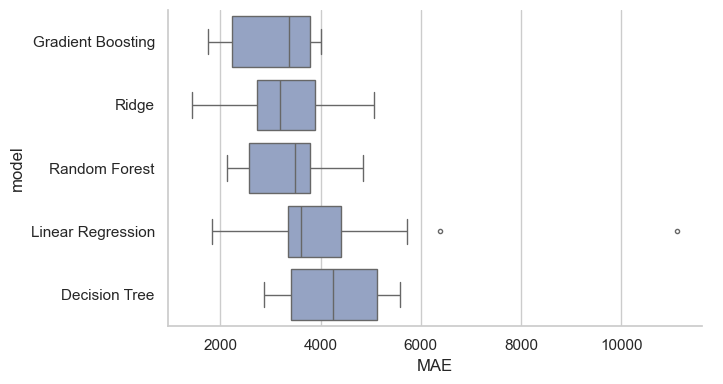

In [56]:
scoring = {"mae": "neg_mean_absolute_error", "r2": "r2"}          # kept for the later sections that use cross_validate

def repeated_group_folds(groups, n_splits=5, repeats=3, seed=RANDOM_STATE):
    # random assignment of whole phone models to folds, repeated with new draws
    rng = np.random.default_rng(seed)
    names = groups.unique()
    out = []
    for _ in range(repeats):
        fold_of = dict(zip(rng.permutation(names), np.arange(len(names)) % n_splits))
        f = groups.map(fold_of).to_numpy()
        out += [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(n_splits)]
    return out

OUTER = repeated_group_folds(GROUPS_TRAIN)                       # 15 train/validation splits, all inside the training part
gkf = GroupKFold(n_splits=5)                                     # plain grouped 5-fold, used by later sections

def grouped_cv(estimator, grid=None):
    # per-fold metrics; with a grid, the tuning runs INSIDE every fold (nested CV)
    rows = []
    for tr, va in OUTER:
        m = clone(estimator)
        if grid is not None:
            m = GridSearchCV(m, grid, cv=GroupKFold(n_splits=3), scoring="neg_mean_absolute_error", n_jobs=-1)
            m.fit(X_train.iloc[tr], y_train.iloc[tr], groups=GROUPS_TRAIN.iloc[tr])
        else:
            m.fit(X_train.iloc[tr], y_train.iloc[tr])
        rows.append(fold_metrics(y_train.iloc[va], m.predict(X_train.iloc[va])))
    return pd.DataFrame(rows)

cv_folds = {n: grouped_cv(m) for n, m in models.items()}
cv_results = pd.DataFrame({n: {"CV MAE": f["MAE"].mean(), "CV MAE std": f["MAE"].std(), "CV RMSE": f["RMSE"].mean(),
                               "CV R2": f["R2"].mean(), "CV MAPE %": f["MAPE %"].mean()} for n, f in cv_folds.items()}).T.sort_values("CV MAE")
display(cv_results.round(3))

fold_long = pd.concat([f.assign(model=n) for n, f in cv_folds.items() if n != "Baseline (median)"])
sns.catplot(data=fold_long, kind="box", x="MAE", y="model", order=[n for n in cv_results.index if n != "Baseline (median)"],
            height=4, aspect=1.8, color="#8DA0CB", fliersize=3)

In [57]:
c = cv_results.drop("Baseline (median)")
top = c.index[0]
display(Markdown(f"""**📊 Analysis**

- With whole phone models held out, the best default model in grouped CV is **{top}**: MAE Rs {c.loc[top, 'CV MAE']:,.0f} (std over folds Rs {c.loc[top, 'CV MAE std']:,.0f}), R² {c.loc[top, 'CV R2']:.2f}, MAPE {c.loc[top, 'CV MAPE %']:.1f}%.
- Ranking of the default models by CV MAE: {', '.join(f"{n} (Rs {c.loc[n, 'CV MAE']:,.0f})" for n in c.index)}.
- The fold-to-fold spread is large (std about Rs {c['CV MAE std'].median():,.0f}), so differences smaller than that between two models are **not** reliable.
- The baseline MAE is Rs {cv_results.loc['Baseline (median)', 'CV MAE']:,.0f}; {top} removes {1 - c.loc[top, 'CV MAE'] / cv_results.loc['Baseline (median)', 'CV MAE']:.0%} of it."""))

**📊 Analysis**

- With whole phone models held out, the best default model in grouped CV is **Gradient Boosting**: MAE Rs 3,041 (std over folds Rs 840), R² 0.69, MAPE 15.4%.
- Ranking of the default models by CV MAE: Gradient Boosting (Rs 3,041), Ridge (Rs 3,201), Random Forest (Rs 3,333), Linear Regression (Rs 4,228), Decision Tree (Rs 4,265).
- The fold-to-fold spread is large (std about Rs 974), so differences smaller than that between two models are **not** reliable.
- The baseline MAE is Rs 7,542; Gradient Boosting removes 60% of it.

### 9.3 Hyper-parameter tuning of every model (same split, same metrics, training rows only)
Each model with settings to tune gets a small grid. `GridSearchCV` with 3-fold **GroupKFold** picks the settings on the training rows; the tuned model is then scored with the **same 15 outer folds** as the default models, with the search repeated inside each fold (nested CV). The test set is not used anywhere in this step. The test MAE of the tuned models is printed afterwards for information only.

,CV MAE default,CV MAE tuned (nested),test MAE default (info only),test MAE tuned (info only),change in CV MAE (%)
model,,,,,
Gradient Boosting,3040.8,3033.4,2256.4,1915.4,-0.2
Random Forest,3332.6,3159.7,2612.4,2445.4,-5.2
Decision Tree,4264.7,4351.0,3163.4,2900.2,2.0
Ridge,3200.6,3066.5,2570.9,2265.7,-4.2


best settings, Gradient Boosting: {'learning_rate': 0.07, 'max_depth': 2, 'n_estimators': 400}
best settings, Random Forest: {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 2}
best settings, Decision Tree: {'max_depth': 4, 'min_samples_leaf': 10}
best settings, Ridge: {'alpha': 30}


<Axes: xlabel='model', ylabel='grouped CV MAE'>

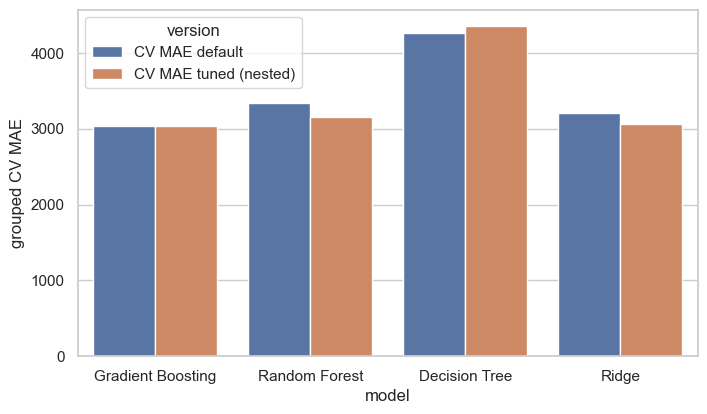

In [58]:
RS = RANDOM_STATE
tune_specs = {
    "Gradient Boosting": (make_model(GradientBoostingRegressor(subsample=0.8, random_state=RS)),
                          {"regressor__reg__n_estimators": [200, 400], "regressor__reg__learning_rate": [0.03, 0.07],
                           "regressor__reg__max_depth": [2, 3, 4]}),
    "Random Forest": (make_model(RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=RS)),
                      {"regressor__reg__max_depth": [None, 8], "regressor__reg__min_samples_leaf": [1, 2, 4],
                       "regressor__reg__max_features": [0.33, 0.6, 1.0]}),
    "Decision Tree": (make_model(DecisionTreeRegressor(random_state=RS)),
                      {"regressor__reg__max_depth": [3, 4, 5, 6, 8], "regressor__reg__min_samples_leaf": [1, 3, 5, 10]}),
    "Ridge": (make_model(Ridge(), scale=True), {"regressor__reg__alpha": [0.1, 0.3, 1, 3, 10, 30]}),
}

tuned_models, nested_folds, tune_rows = {}, {}, []
for name, (est, grid) in tune_specs.items():
    nested_folds[f"{name} (tuned)"] = grouped_cv(est, grid)                       # honest score: search repeated inside each fold
    gs = GridSearchCV(est, grid, cv=GroupKFold(n_splits=3), scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(X_train, y_train, groups=GROUPS_TRAIN)                                # final settings, from the training rows only
    tuned_models[f"{name} (tuned)"] = gs.best_estimator_
    tune_rows.append({"model": name,
                      "best settings": str({k.split("__")[-1]: v for k, v in gs.best_params_.items()}),
                      "CV MAE default": cv_folds[name]["MAE"].mean(),
                      "CV MAE tuned (nested)": nested_folds[f"{name} (tuned)"]["MAE"].mean(),
                      "test MAE default (info only)": evaluate(models[name], X_test, y_test)["MAE"],
                      "test MAE tuned (info only)": evaluate(gs.best_estimator_, X_test, y_test)["MAE"]})

tune_table = pd.DataFrame(tune_rows).set_index("model")
tune_table["change in CV MAE (%)"] = (tune_table["CV MAE tuned (nested)"] / tune_table["CV MAE default"] - 1) * 100
display(tune_table.drop(columns="best settings").round(1))
for n, s in tune_table["best settings"].items():
    print(f"best settings, {n}: {s}")

tune_long = tune_table[["CV MAE default", "CV MAE tuned (nested)"]].reset_index().melt(id_vars="model", var_name="version", value_name="grouped CV MAE")
plt.figure(figsize=(8, 4.5))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=tune_long, x="model", y="grouped CV MAE", hue="version")

In [62]:
t = tune_table
better = t[t["change in CV MAE (%)"] < 0].index.tolist()
worse = t[t["change in CV MAE (%)"] >= 0].index.tolist()
display(Markdown(f"""**📊 Analysis**

- Tuning was done on the training rows with phone models held out; the score used for comparison is the **nested** one, so it is not flattered by the search.
- Tuning **helped** (lower nested CV MAE than the default settings): {', '.join(f"{n} ({t.loc[n, 'change in CV MAE (%)']:+.1f}%)" for n in better) or 'none'}. It **did not help**: {', '.join(f"{n} ({t.loc[n, 'change in CV MAE (%)']:+.1f}%)" for n in worse) or 'none'}.
- The grids are small on purpose: with {len(X_train)} training rows, a large search would mostly fit noise.
- The test MAE columns are shown only to prove that tuning did not peek at the test set; they play no part in the choice below."""))

**📊 Analysis**

- Tuning was done on the training rows with phone models held out; the score used for comparison is the **nested** one, so it is not flattered by the search.
- Tuning **helped** (lower nested CV MAE than the default settings): Gradient Boosting (-0.2%), Random Forest (-5.2%), Ridge (-4.2%). It **did not help**: Decision Tree (+2.0%).
- The grids are small on purpose: with 427 training rows, a large search would mostly fit noise.
- The test MAE columns are shown only to prove that tuning did not peek at the test set; they play no part in the choice below.

### 9.4 Model selection (rule fixed before looking at the test set)
**Rule:** among all models, default and tuned, the one with the **lowest grouped-CV MAE on the training rows** is the final model (nested CV for tuned models). Gradient Boosting is kept only if it wins this comparison.

In [63]:
all_models = {**models, **tuned_models}
all_cv = {**cv_folds, **nested_folds}
selection = pd.Series({n: f["MAE"].mean() for n, f in all_cv.items()}).drop("Baseline (median)").sort_values()
selection_sd = pd.Series({n: all_cv[n]["MAE"].std() for n in selection.index})
display(pd.DataFrame({"grouped CV MAE (Rs)": selection, "std over folds": selection_sd}).round(0))

final_name = selection.index[0]
best = final_name                                   # name used by later sections
final_model = all_models[final_name]
gb_rank = list(selection.index).index("Gradient Boosting") + 1
margin = selection.iloc[1] - selection.iloc[0]
print(f"Final model by the rule: {final_name}")
print("Gradient Boosting (default) is", "the winner" if final_name == "Gradient Boosting" else f"NOT the winner (rank {gb_rank} of {len(selection)}); it is replaced by {final_name}")

,grouped CV MAE (Rs),std over folds
Gradient Boosting (tuned),3033.0,864.0
Gradient Boosting,3041.0,840.0
Ridge (tuned),3066.0,963.0
Random Forest (tuned),3160.0,825.0
Ridge,3201.0,1038.0
Random Forest,3333.0,822.0
Linear Regression,4228.0,2280.0
Decision Tree,4265.0,974.0
Decision Tree (tuned),4351.0,1017.0


Final model by the rule: Gradient Boosting (tuned)
Gradient Boosting (default) is NOT the winner (rank 2 of 9); it is replaced by Gradient Boosting (tuned)


In [64]:
sel_txt = ", ".join(f"{n} Rs {v:,.0f}" for n, v in selection.head(4).items())
display(Markdown(f"""**📊 Analysis**

- **Final model: {final_name}** (grouped-CV MAE Rs {selection.iloc[0]:,.0f}). Next best: {selection.index[1]} (Rs {selection.iloc[1]:,.0f}). Top four: {sel_txt}.
- The winner beats the runner-up by Rs {margin:,.0f}, while the fold-to-fold std is about Rs {selection_sd.iloc[0]:,.0f}. {'The margin is smaller than the spread, so the top models are statistically close: the choice is sensible, but do not claim one is clearly better.' if margin < selection_sd.iloc[0] else 'The margin is larger than the fold-to-fold spread.'}
- Gradient Boosting (default settings) {'is the best model on this yardstick, so it is kept.' if final_name == 'Gradient Boosting' else f'is ranked {gb_rank} of {len(selection)} on this yardstick, so it is **not** kept; {final_name} is used instead.'}
- The choice used only the training rows. The test set is used once, in 9.6."""))

**📊 Analysis**

- **Final model: Gradient Boosting (tuned)** (grouped-CV MAE Rs 3,033). Next best: Gradient Boosting (Rs 3,041). Top four: Gradient Boosting (tuned) Rs 3,033, Gradient Boosting Rs 3,041, Ridge (tuned) Rs 3,066, Random Forest (tuned) Rs 3,160.
- The winner beats the runner-up by Rs 7, while the fold-to-fold std is about Rs 864. The margin is smaller than the spread, so the top models are statistically close: the choice is sensible, but do not claim one is clearly better.
- Gradient Boosting (default settings) is ranked 2 of 9 on this yardstick, so it is **not** kept; Gradient Boosting (tuned) is used instead.
- The choice used only the training rows. The test set is used once, in 9.6.

### 9.5 Did the engineered features help? (same models, only the feature set changes)
Scored with grouped CV on the **training rows** only, so it follows the same rules as the rest of the section.

,model,feature set,features,MAE,R2
0,Ridge,Original features,11,3312.869,0.669
1,Ridge,Original + engineered (audited),39,3200.596,0.693
2,Gradient Boosting,Original features,11,3097.342,0.710
3,Gradient Boosting,Original + engineered (audited),39,3040.798,0.694


**📊 Analysis**

- Error on unseen phone models, original vs original + engineered features: Ridge: Rs 3,313 -> Rs 3,201 (-3.4%); Gradient Boosting: Rs 3,097 -> Rs 3,041 (-1.8%).
- A negative change means the engineered features helped. Gains are small compared with the fold-to-fold spread in 9.2, so the engineered features are mainly useful for explanation (tiers, classes) and for simpler models, not a guaranteed accuracy gain.

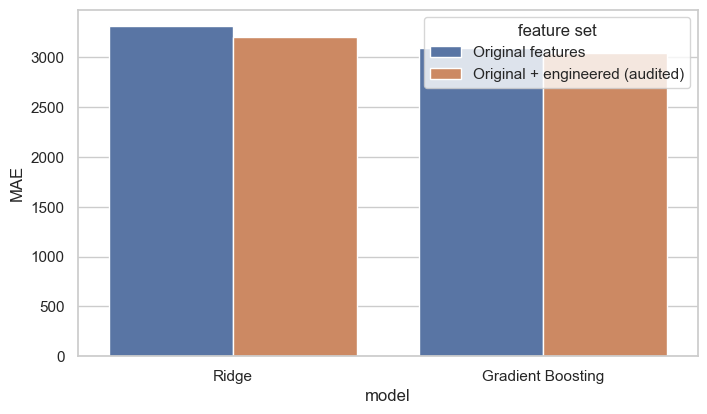

In [65]:
rows = []
for model_name, reg, scale in [("Ridge", Ridge(alpha=3.0), True), ("Gradient Boosting", GradientBoostingRegressor(**GB_PARAMS), False)]:
    for label, (num, cat) in {"Original features": (base_num, base_cat), "Original + engineered (audited)": (num_features, cat_features)}.items():
        mdl = make_model(reg, scale=scale, num=num, cat=cat)
        fm = pd.DataFrame([fold_metrics(y_train.iloc[va], clone(mdl).fit(X_train[num + cat].iloc[tr], y_train.iloc[tr]).predict(X_train[num + cat].iloc[va]))
                           for tr, va in OUTER])
        rows.append({"model": model_name, "feature set": label, "features": len(num + cat), "MAE": fm["MAE"].mean(), "R2": fm["R2"].mean()})
fe_check = pd.DataFrame(rows)
display(fe_check.round(3))
plt.figure(figsize=(8, 4.5))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=fe_check, x="model", y="MAE", hue="feature set")

parts = []
for m_name in ["Ridge", "Gradient Boosting"]:
    a = fe_check[(fe_check["model"] == m_name) & (fe_check["feature set"] == "Original features")]["MAE"].iloc[0]
    b = fe_check[(fe_check["model"] == m_name) & (fe_check["feature set"] != "Original features")]["MAE"].iloc[0]
    parts.append(f"{m_name}: Rs {a:,.0f} -> Rs {b:,.0f} ({b / a - 1:+.1%})")
display(Markdown("**📊 Analysis**\n\n- Error on unseen phone models, original vs original + engineered features: " + "; ".join(parts) +
                 ".\n- A negative change means the engineered features helped. Gains are small compared with the fold-to-fold spread in 9.2, so the engineered features are mainly useful for explanation (tiers, classes) and for simpler models, not a guaranteed accuracy gain."))

### 9.6 Final model on the test set (used once)

In [66]:
pred = final_model.predict(X_test)
final_table = pd.DataFrame({n: evaluate(m, X_test, y_test) for n, m in all_models.items() if n != "Baseline (median)"}).T.sort_values("MAE")
final_table["chosen by CV rule"] = ["yes" if n == final_name else "" for n in final_table.index]
display(final_table.round(3))

abs_err = np.abs(y_test.values - pred)
# bootstrap by phone model (listings of one phone model are not independent, so whole models are resampled)
rng = np.random.default_rng(RANDOM_STATE)
g_test = GROUPS_TEST.to_numpy()
members = {g: np.where(g_test == g)[0] for g in np.unique(g_test)}
keys = list(members)
boot_mae, boot_r2, boot_mape = [], [], []
for _ in range(2000):
    idx = np.concatenate([members[k] for k in rng.choice(keys, len(keys))])
    boot_mae.append(abs_err[idx].mean())
    boot_r2.append(r2_score(y_test.values[idx], pred[idx]))
    boot_mape.append(np.mean(abs_err[idx] / y_test.values[idx]) * 100)
ci_lo, ci_hi = np.percentile(boot_mae, [2.5, 97.5])
r2_lo, r2_hi = np.percentile(boot_r2, [2.5, 97.5])
mape_lo, mape_hi = np.percentile(boot_mape, [2.5, 97.5])
fin = fold_metrics(y_test, pred)

,MAE,RMSE,R2,MAPE %,chosen by CV rule
Gradient Boosting (tuned),1915.359,3912.756,0.708,12.060,yes
Gradient Boosting,2256.395,4963.075,0.530,13.826,
Ridge (tuned),2265.749,3645.916,0.747,14.368,
Random Forest (tuned),2445.392,3940.066,0.704,14.530,
Ridge,2570.880,4528.939,0.609,16.045,
Random Forest,2612.378,4112.031,0.678,15.496,
Linear Regression,2700.542,5392.441,0.446,15.949,
Decision Tree (tuned),2900.204,4620.499,0.593,17.690,
Decision Tree,3163.386,5546.658,0.413,17.836,


In [67]:
sel_cv = selection.iloc[0]
display(Markdown(f"""**📊 Analysis**

- **Final model: {final_name}**, chosen on the training rows (9.4). Held-out test result on phone models it has never seen: **MAE Rs {fin['MAE']:,.0f}, RMSE Rs {fin['RMSE']:,.0f}, R² {fin['R2']:.2f}, MAPE {fin['MAPE %']:.1f}%**.
- Bootstrap 95% intervals (whole phone models resampled): MAE Rs {ci_lo:,.0f} to Rs {ci_hi:,.0f}, R² {r2_lo:.2f} to {r2_hi:.2f}, MAPE {mape_lo:.1f}% to {mape_hi:.1f}%. The intervals are wide because the test set has only {len(X_test)} rows from {len(members)} phone models.
- Training-only grouped CV gave MAE Rs {sel_cv:,.0f} for this model, so the test result is {'in line with' if abs(fin['MAE'] - sel_cv) < 0.25 * sel_cv else 'noticeably different from'} the cross-validation estimate. {'The test set holds ' + str(int(premium_tier.loc[X_test.index].sum())) + ' Premium-brand rows and ' + str(int((y_test > 40000).sum())) + ' phone(s) above Rs 40,000, which are the hardest to price, so it is easier than the cross-validation folds.' if fin['MAE'] < sel_cv else ''}
- The table above ranks models by test MAE for information. If its order differs from the CV rule, that is ordinary noise from {len(X_test)} rows, and the CV rule still decides."""))

display(Markdown(f"""### How to quote this result
- **For a new phone model (use this one):** on the held-out phone models of this notebook R² {fin['R2']:.2f}, MAPE {fin['MAPE %']:.1f}%, MAE about Rs {fin['MAE']:,.0f}; training-only grouped CV: MAE about Rs {sel_cv:,.0f}, MAPE {all_cv[final_name]['MAPE %'].mean():.1f}%. Because this test split has no Premium phones, the cross-validation and repeated-split figures are the more cautious estimate.
- **Saved v7 result (random split, not for new phones):** R² 0.84, MAPE 6.8%, MAE about Rs 1,389. Quote it only as "pricing another colour or variant of a phone already in the data". It is higher because the random split lets the model see other colours and variants of the same phone.
- **Spread to expect:** over 20 repeated grouped splits (default Gradient Boosting) MAE averages Rs {rr.get_group('grouped by phone model')['MAE'].mean():,.0f} (std Rs {rr.get_group('grouped by phone model')['MAE'].std():,.0f}), R² {rr.get_group('grouped by phone model')['R2'].mean():.2f}, MAPE {rr.get_group('grouped by phone model')['MAPE %'].mean():.1f}%. The single test split is on the easier side because it contains {int(premium_tier.loc[X_test.index].sum())} Premium-brand rows.
- **No "96% accuracy" claim is made.** No metric in this notebook reaches 96%, and "accuracy" is not defined for a price regression. If a single percentage is wanted, use MAPE (average % error), which is {fin['MAPE %']:.1f}% here, and say so."""))

**📊 Analysis**

- **Final model: Gradient Boosting (tuned)**, chosen on the training rows (9.4). Held-out test result on phone models it has never seen: **MAE Rs 1,915, RMSE Rs 3,913, R² 0.71, MAPE 12.1%**.
- Bootstrap 95% intervals (whole phone models resampled): MAE Rs 1,140 to Rs 3,074, R² -0.02 to 0.95, MAPE 7.5% to 18.7%. The intervals are wide because the test set has only 104 rows from 36 phone models.
- Training-only grouped CV gave MAE Rs 3,033 for this model, so the test result is noticeably different from the cross-validation estimate. The test set holds 0 Premium-brand rows and 1 phone(s) above Rs 40,000, which are the hardest to price, so it is easier than the cross-validation folds.
- The table above ranks models by test MAE for information. If its order differs from the CV rule, that is ordinary noise from 104 rows, and the CV rule still decides.

### How to quote this result
- **For a new phone model (use this one):** on the held-out phone models of this notebook R² 0.71, MAPE 12.1%, MAE about Rs 1,915; training-only grouped CV: MAE about Rs 3,033, MAPE 15.4%. Because this test split has no Premium phones, the cross-validation and repeated-split figures are the more cautious estimate.
- **Saved v7 result (random split, not for new phones):** R² 0.84, MAPE 6.8%, MAE about Rs 1,389. Quote it only as "pricing another colour or variant of a phone already in the data". It is higher because the random split lets the model see other colours and variants of the same phone.
- **Spread to expect:** over 20 repeated grouped splits (default Gradient Boosting) MAE averages Rs 3,011 (std Rs 836), R² 0.68, MAPE 14.8%. The single test split is on the easier side because it contains 0 Premium-brand rows.
- **No "96% accuracy" claim is made.** No metric in this notebook reaches 96%, and "accuracy" is not defined for a price regression. If a single percentage is wanted, use MAPE (average % error), which is 12.1% here, and say so.

Predicted against actual price. Points on the red line are perfect predictions.

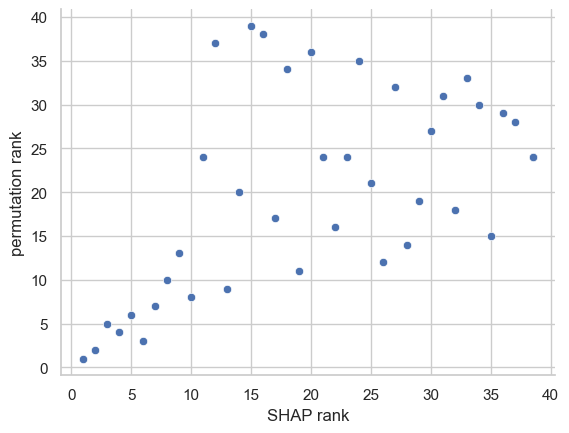

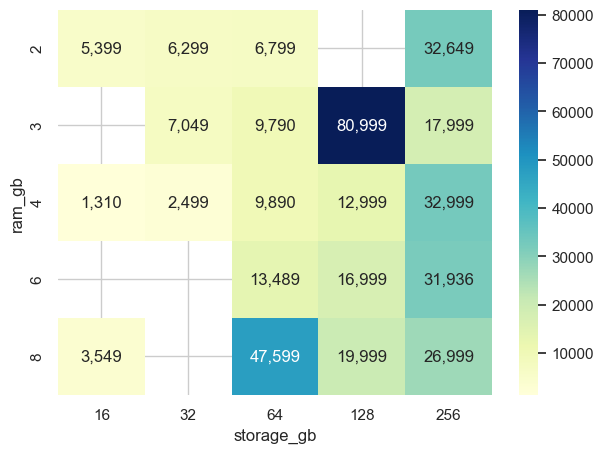

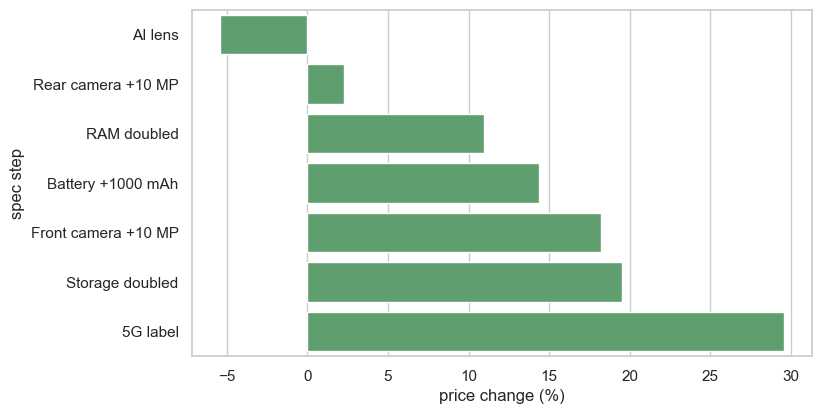

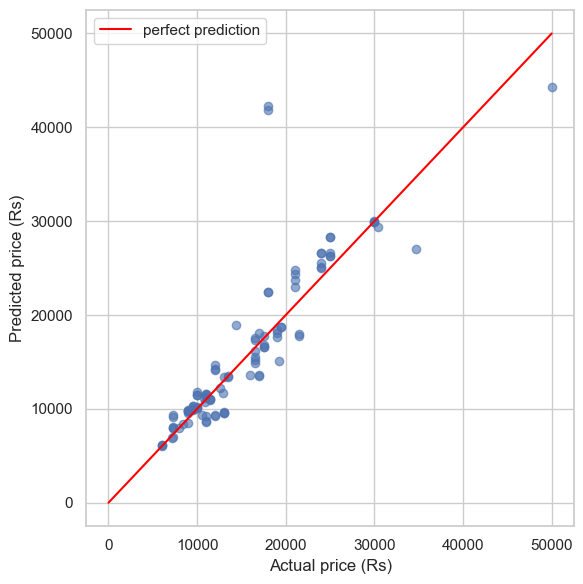

Over-predicted: 57%; under-predicted: 43%


In [123]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], color="red", label="perfect prediction")
plt.xlabel("Actual price (Rs)")
plt.ylabel("Predicted price (Rs)")
plt.legend()
plt.tight_layout()
plt.show()

over = (pred > y_test.values).mean()
print(f"Over-predicted: {over:.0%}; under-predicted: {1 - over:.0%}")

In [69]:

display(Markdown(f"""**📊 Analysis**

- {over:.0%} of the test phones are over-predicted and {1 - over:.0%} under-predicted.
- Points far from the red line are the phones the model misjudged; the most expensive phones are the likeliest to sit far from it, because there are few of them to learn from.
- Use the prediction as a benchmark price range, not an exact price."""))


**📊 Analysis**

- 57% of the test phones are over-predicted and 43% under-predicted.
- Points far from the red line are the phones the model misjudged; the most expensive phones are the likeliest to sit far from it, because there are few of them to learn from.
- Use the prediction as a benchmark price range, not an exact price.

Error in log price (0 = perfect) and error by price quartile.

price band,Q1 cheapest,Q2,Q3,Q4 priciest
mean absolute error %,7.7,11.7,19.7,9.5


Mean error in log units: +0.018


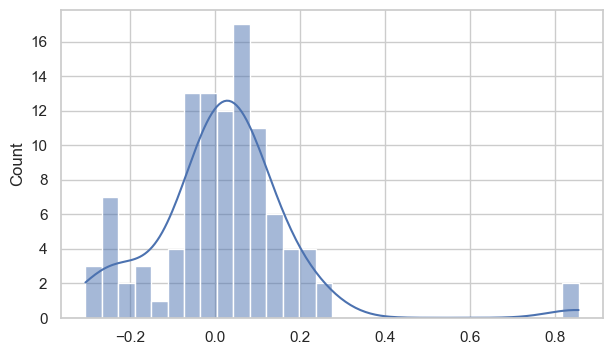

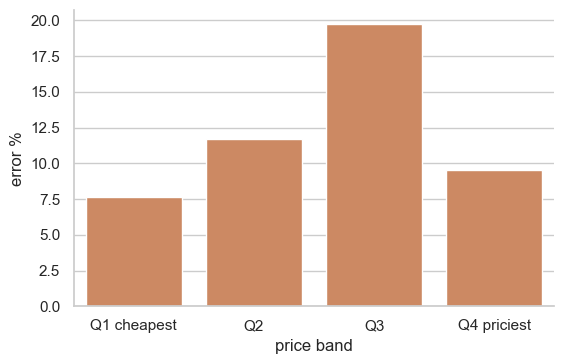

In [70]:
plt.figure(figsize=(7, 4))      # fresh figure, so this chart never draws on top of the previous one
sns.histplot(np.log(pred) - np.log(y_test.values), kde=True, bins=30)

test_eval = pd.DataFrame({"actual": y_test.values, "pred": pred})
test_eval["price band"] = pd.qcut(test_eval["actual"], 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 priciest"])
test_eval["error %"] = np.abs(test_eval["actual"] - test_eval["pred"]) / test_eval["actual"] * 100
sns.catplot(data=test_eval, kind="bar", x="price band", y="error %", errorbar=None, height=3.8, aspect=1.5, color="#DD8452")

by_band = test_eval.groupby("price band", observed=True)["error %"].mean()
bias = float(np.mean(np.log(pred) - np.log(y_test.values)))
display(by_band.round(1).to_frame("mean absolute error %").T)
print(f"Mean error in log units: {bias:+.3f}")

In [71]:

display(Markdown(f"""**📊 Analysis**

- Mean error in log units is {bias:+.3f}: {'little systematic bias' if abs(bias) < 0.03 else 'a visible tendency to over- or under-predict'}.
- Average percentage error by price quarter: {', '.join(f'{k} {v:.1f}%' for k, v in by_band.items())}.
- {'The most expensive quarter of phones has the largest percentage error' if by_band.iloc[-1] == by_band.max() else 'The largest percentage error is in the ' + str(by_band.idxmax()) + ' price quarter'}. With {len(y_test)} test phones each quarter holds only about {len(y_test) // 4} phones, so one bad listing moves the average a lot (see 9.7.5)."""))


**📊 Analysis**

- Mean error in log units is +0.018: little systematic bias.
- Average percentage error by price quarter: Q1 cheapest 7.7%, Q2 11.7%, Q3 19.7%, Q4 priciest 9.5%.
- The largest percentage error is in the Q3 price quarter. With 104 test phones each quarter holds only about 26 phones, so one bad listing moves the average a lot (see 9.7.5).

### 9.7 Residual analysis (are the model's mistakes random, or is something still missing?)
A **residual** is `actual price - predicted price`. A good model leaves residuals that look like **random noise**. Patterns in the residuals show where the model is still wrong in a systematic way.

| Check | What a healthy result looks like | What a problem looks like |
|---|---|---|
| Mean of the log residuals | close to 0 (the t-test p-value above 0.05) | clearly above or below 0 = the model over- or under-prices on average (bias) |
| Residuals vs predicted price | an even cloud around 0 | a funnel (errors grow with price) or a curve (the model misses a trend) |
| Histogram and QQ plot | bell-shaped, dots on the line | long tails = a few phones are badly mispriced |
| Residuals by group (RAM, price band, brand) | every box sits around 0 | one group sits above or below 0 = the model is biased for that group |
| Residuals vs features | no link | a link means that feature carries price information the model did not use |

*Log residuals* (`log(actual) - log(predicted)`) are used next to rupee residuals: a log residual of 0.10 means "about 10 % higher than predicted", which is fair for cheap and expensive phones alike.

#### 9.7.1 Residual statistics and tests

In [72]:
resid = pd.DataFrame({"actual": y_test.values, "pred": pred}, index=y_test.index)
resid["residual"] = resid["actual"] - resid["pred"]                         # rupees; positive = the phone costs more than predicted
resid["log_residual"] = np.log(resid["actual"]) - np.log(resid["pred"])     # about +0.10 means 10 % above the prediction
resid["abs_pct_error"] = resid["residual"].abs() / resid["actual"] * 100
resid["price band"] = pd.qcut(resid["actual"], 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 priciest"])
resid = resid.join(df.loc[y_test.index, ["model", "brand", "brand_tier", "ram_gb", "storage_gb"]])

r, lr = resid["residual"], resid["log_residual"]
stat_tbl = pd.DataFrame({"residual (Rs)": [r.mean(), r.median(), r.std(), r.skew(), r.kurt(), r.min(), r.max()],
                         "log residual": [lr.mean(), lr.median(), lr.std(), lr.skew(), lr.kurt(), lr.min(), lr.max()]},
                        index=["mean", "median", "std", "skew", "excess kurtosis", "min", "max"])
display(stat_tbl.round(3))

t_stat, t_p = stats.ttest_1samp(lr, 0)                                      # H0: the average log error is 0 (no bias)
sh_stat, sh_p = stats.shapiro(lr)                                           # H0: the log errors are bell-shaped
rho_r, p_r = spearmanr(resid["pred"], resid["residual"].abs())              # does the rupee error grow with price?
rho_l, p_l = spearmanr(resid["pred"], resid["log_residual"].abs())          # does the relative error grow with price?
print(f"Bias test (mean log residual = 0): t = {t_stat:.2f}, p = {t_p:.3f}")
print(f"Shapiro-Wilk normality of log residuals: W = {sh_stat:.3f}, p = {sh_p:.3g}")
print(f"|error| vs predicted price: rupee error rho = {rho_r:+.2f} (p = {p_r:.3g}); relative error rho = {rho_l:+.2f} (p = {p_l:.3g})")
print(f"Share of test phones predicted within 10 %: {(resid['abs_pct_error'] <= 10).mean():.0%}; within 20 %: {(resid['abs_pct_error'] <= 20).mean():.0%}")

,residual (Rs),log residual
mean,-496.632,-0.018
median,-216.727,-0.020
std,3899.905,0.172
skew,-4.192,-1.840
excess kurtosis,24.953,9.102
min,-24308.172,-0.855
max,7624.404,0.305


Bias test (mean log residual = 0): t = -1.08, p = 0.284
Shapiro-Wilk normality of log residuals: W = 0.829, p = 1.29e-09
|error| vs predicted price: rupee error rho = +0.39 (p = 4.69e-05); relative error rho = +0.06 (p = 0.518)
Share of test phones predicted within 10 %: 63%; within 20 %: 82%


In [73]:
w10 = (resid["abs_pct_error"] <= 10).mean(); w20 = (resid["abs_pct_error"] <= 20).mean()
big = resid.loc[r.abs().idxmax()]
display(Markdown(f"""**📊 Analysis**

- **Average bias:** the mean log residual is {lr.mean():+.3f} (t-test p = {t_p:.2f}), so {'the model does not systematically over- or under-price' if t_p > 0.05 else 'the model is systematically off in one direction'}. The rupee mean ({r.mean():+,.0f}) and median ({r.median():+,.0f}) differ because of a few large misses; the largest is Rs {abs(big['residual']):,.0f} ({big['model']}, real Rs {big['actual']:,.0f}, predicted Rs {big['pred']:,.0f}).
- **Typical error:** the standard deviation of the log residual is {lr.std():.3f}; {w10:.0%} of the test phones are predicted within 10% of their real price and {w20:.0%} within 20%.
- **Shape:** Shapiro-Wilk W = {sh_stat:.3f} (p = {sh_p:.2g}); skew of the log residual {lr.skew():.1f}, excess kurtosis {lr.kurt():.1f}. {'The errors are not bell-shaped: a few big misses create heavy tails, so error ranges should come from percentiles or the bootstrap (9.6), not from a normal-curve formula.' if sh_p < 0.05 else 'The errors look close to bell-shaped.'}
- **Error vs price:** |rupee error| against predicted price: rho {rho_r:+.2f} (p = {p_r:.2g}); |log error| against predicted price: rho {rho_l:+.2f} (p = {p_l:.2g}). {'The percentage error does not clearly grow with price, which supports modelling log(price).' if p_l > 0.05 else 'The percentage error changes with price (see 9.7.2).'}"""))

**📊 Analysis**

- **Average bias:** the mean log residual is -0.018 (t-test p = 0.28), so the model does not systematically over- or under-price. The rupee mean (-497) and median (-217) differ because of a few large misses; the largest is Rs 24,308 (realme X3 SuperZoom, real Rs 17,999, predicted Rs 42,307).
- **Typical error:** the standard deviation of the log residual is 0.172; 63% of the test phones are predicted within 10% of their real price and 82% within 20%.
- **Shape:** Shapiro-Wilk W = 0.829 (p = 1.3e-09); skew of the log residual -1.8, excess kurtosis 9.1. The errors are not bell-shaped: a few big misses create heavy tails, so error ranges should come from percentiles or the bootstrap (9.6), not from a normal-curve formula.
- **Error vs price:** |rupee error| against predicted price: rho +0.39 (p = 4.7e-05); |log error| against predicted price: rho +0.06 (p = 0.52). The percentage error does not clearly grow with price, which supports modelling log(price).

#### 9.7.2 Residuals against predicted price and their distribution
Left to right: rupee residuals vs predicted price, log residuals vs predicted price, and the histogram of rupee residuals. The horizontal line at 0 is a perfect prediction.

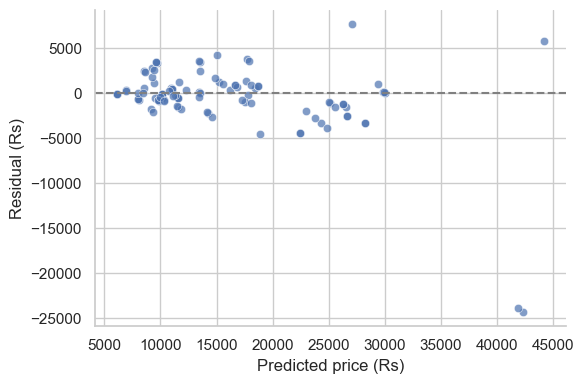

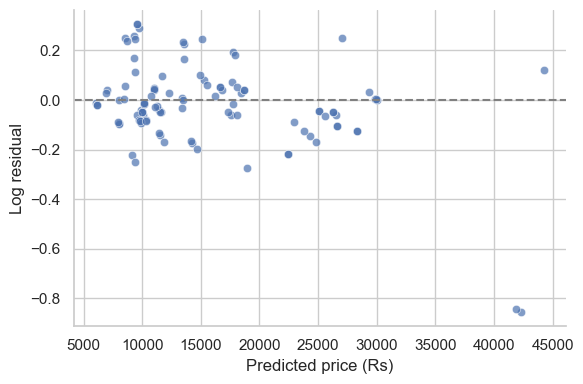

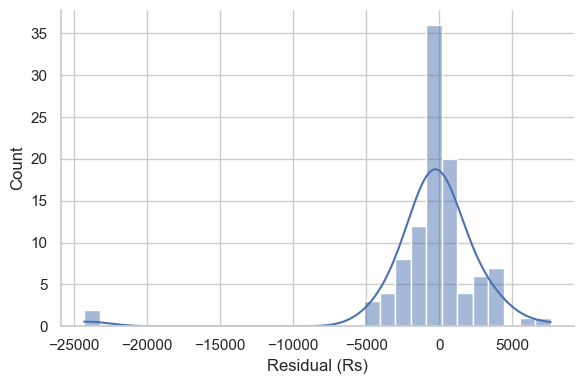

In [74]:
g1 = sns.relplot(data=resid, x="pred", y="residual", height=4, aspect=1.5, alpha=0.7)
g1.refline(y=0)
g1.set(xlabel="Predicted price (Rs)", ylabel="Residual (Rs)")

g2 = sns.relplot(data=resid, x="pred", y="log_residual", height=4, aspect=1.5, alpha=0.7)
g2.refline(y=0)
g2.set(xlabel="Predicted price (Rs)", ylabel="Log residual")

sns.displot(resid["residual"], kde=True, bins=30, height=4, aspect=1.5).set(xlabel="Residual (Rs)")

In [75]:
in20 = (lr.abs() <= 0.20).mean()
top3 = resid.loc[r.abs().nlargest(3).index]
up, down = int((lr > 0.2).sum()), int((lr < -0.2).sum())
display(Markdown(f"""**📊 Analysis**

- **Spread:** {in20:.0%} of the test phones have a log residual between -0.20 and +0.20 (an error of roughly 20% or less).
- **Largest misses (rupees):** {'; '.join(f"{row['model']} (real Rs {row['actual']:,.0f}, predicted Rs {row['pred']:,.0f})" for _, row in top3.iterrows())}.
- **Which direction the big misses go:** {up} phone(s) cost clearly **more** than predicted (log residual above +0.20) and {down} cost clearly **less** (below -0.20).
- **Funnel shape:** the relative error does {'not ' if p_l > 0.05 else ''}change clearly with predicted price (rho {rho_l:+.2f}, p = {p_l:.2g}); {'cheap and expensive phones get a similar percentage error.' if p_l > 0.05 else 'check the log-residual panel before trusting the model at one end of the price range.'}"""))

**📊 Analysis**

- **Spread:** 83% of the test phones have a log residual between -0.20 and +0.20 (an error of roughly 20% or less).
- **Largest misses (rupees):** realme X3 SuperZoom (real Rs 17,999, predicted Rs 42,307); realme X3 SuperZoom (real Rs 17,999, predicted Rs 41,880); IQOO Neo 7 5G (real Rs 34,688, predicted Rs 27,064).
- **Which direction the big misses go:** 11 phone(s) cost clearly **more** than predicted (log residual above +0.20) and 7 cost clearly **less** (below -0.20).
- **Funnel shape:** the relative error does not change clearly with predicted price (rho +0.06, p = 0.52); cheap and expensive phones get a similar percentage error.

#### 9.7.3 QQ plots of the residuals
If the dots follow the straight line, the residuals are close to a bell curve. Dots that curl away at the ends are the few phones the model got badly wrong.

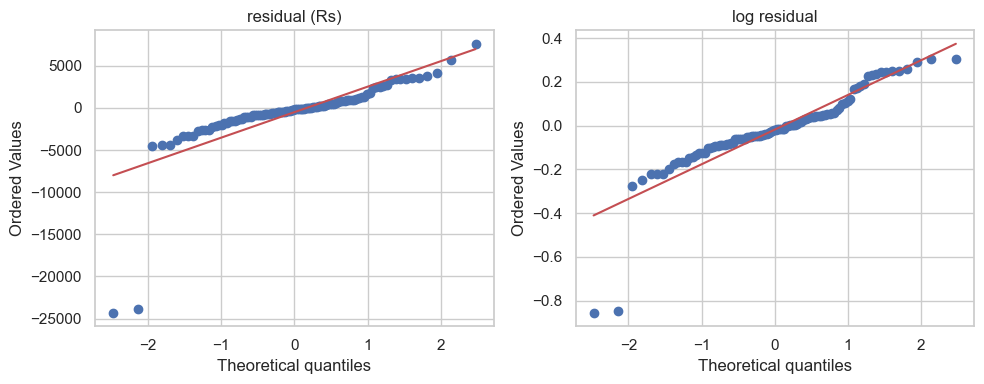

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(resid["residual"], dist="norm", plot=axes[0]);      axes[0].set_title("residual (Rs)")
stats.probplot(resid["log_residual"], dist="norm", plot=axes[1]);  axes[1].set_title("log residual")
plt.tight_layout()
plt.show()

In [77]:
far = lr.abs().nlargest(3)
n_far = int((lr.abs() > 0.30).sum())
display(Markdown(f"""**📊 Analysis**

- **Log residuals:** {(lr.abs() <= 0.10).mean():.0%} of the phones lie within +/-0.10 of the line; the three largest absolute values are {', '.join(f'{v:.2f}' for v in far.values)}; {n_far} phone(s) are beyond +/-0.30.
- **Rupee residuals:** the largest single point is Rs {r.abs().max():,.0f}.
- {n_far} of {len(lr)} phones ({n_far / len(lr):.0%}) are far from the line. {'The non-normality found in 9.7.1 therefore comes from a small group of phones, not from a general problem.' if n_far <= 0.1 * len(lr) else 'More than one phone in ten is far from the line, so the non-normality is not just a few outliers.'}"""))

**📊 Analysis**

- **Log residuals:** 63% of the phones lie within +/-0.10 of the line; the three largest absolute values are 0.85, 0.84, 0.31; 4 phone(s) are beyond +/-0.30.
- **Rupee residuals:** the largest single point is Rs 24,308.
- 4 of 104 phones (4%) are far from the line. The non-normality found in 9.7.1 therefore comes from a small group of phones, not from a general problem.

#### 9.7.4 Residuals by group: is the model fair to every kind of phone?
Box plots of the log residual by RAM size and by price band (a group comparison). A box that sits clearly above 0 means the model **under-prices** that group; below 0 means it **over-prices** it. The tables give the same view in numbers.

--- residuals by brand_tier ---


,n,mean residual (Rs),MAE (Rs),MAPE %
brand_tier,,,,
Challenger,3,2459.7,3292.4,10.1
Mainstream,77,-820.1,2227.1,13.9
Value,24,171.5,743.0,6.3


--- residuals by ram_gb ---


,n,mean residual (Rs),MAE (Rs),MAPE %
ram_gb,,,,
2,3,-108.9,108.9,1.8
3,8,-2027.3,4049.7,26.4
4,39,329.8,1239.7,10.4
6,24,-1637.8,2106.0,13.1
8,30,-288.7,2252.6,10.6


--- residuals by price band ---


,n,mean residual (Rs),MAE (Rs),MAPE %
price band,,,,
Q1 cheapest,31,-594.2,659.8,7.7
Q2,21,491.9,1369.3,11.7
Q3,27,-1469.5,3360.6,19.7
Q4 priciest,25,-155.4,2370.0,9.5


--- residuals by brand (brands with at least 5 test phones) ---


,n,mean residual (Rs),MAE (Rs),MAPE %
brand,,,,
Motorola,8,509.5,1366.1,6.5
Infinix,20,221.5,874.6,7.3
Samsung,15,65.7,1909.7,10.9
Redmi,18,-1239.6,1239.6,11.0
vivo,17,379.0,2330.6,15.4
realme,11,-4936.5,5433.7,31.2


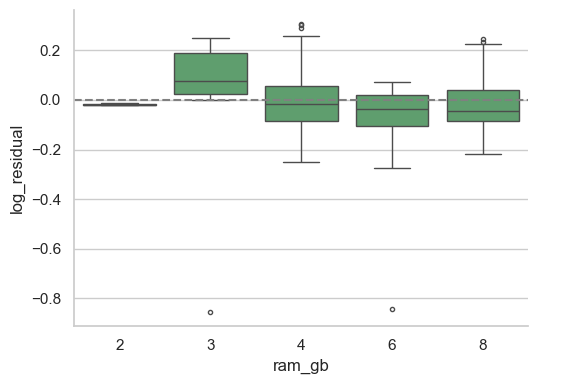

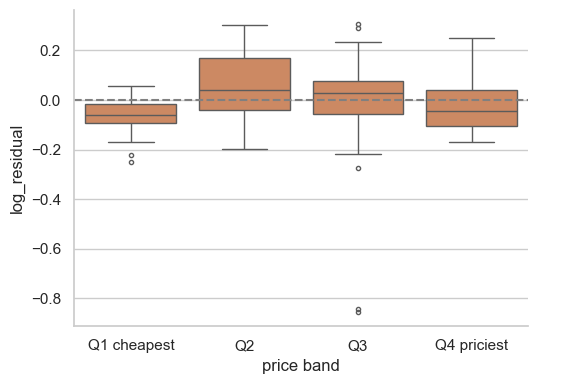

In [78]:
g3 = sns.catplot(data=resid, kind="box", x="ram_gb", y="log_residual", height=4, aspect=1.4, color="#55A868", fliersize=3)
g3.refline(y=0)
g4 = sns.catplot(data=resid, kind="box", x="price band", y="log_residual", height=4, aspect=1.4, color="#DD8452", fliersize=3)
g4.refline(y=0)

def seg(col):
    return resid.groupby(col, observed=True).agg(n=("residual", "size"), **{"mean residual (Rs)": ("residual", "mean"),
                                                 "MAE (Rs)": ("residual", lambda s: s.abs().mean()),
                                                 "MAPE %": ("abs_pct_error", "mean")}).round(1)

for col in ["brand_tier", "ram_gb", "price band"]:
    print(f"--- residuals by {col} ---")
    display(seg(col))
by_brand = seg("brand")
print("--- residuals by brand (brands with at least 5 test phones) ---")
display(by_brand[by_brand["n"] >= 5].sort_values("MAPE %"))

In [79]:
sb, sr, st = seg("price band"), seg("ram_gb"), seg("brand_tier")
bb = by_brand[by_brand["n"] >= 5].sort_values("MAPE %")
sr5 = sr[sr["n"] >= 5]
display(Markdown(f"""**📊 Analysis**

- **By price band (mean absolute % error):** {', '.join(f"{k} {v:.1f}%" for k, v in sb['MAPE %'].items())}. The mean residual is largest (in rupees) for {sb['mean residual (Rs)'].abs().idxmax()} (Rs {sb.loc[sb['mean residual (Rs)'].abs().idxmax(), 'mean residual (Rs)']:+,.0f}); positive means the model **under-prices** that band.
- **By RAM size (sizes with 5+ test phones):** percentage error {sr5['MAPE %'].min():.1f}% to {sr5['MAPE %'].max():.1f}%; largest for {sr5['MAPE %'].idxmax()} GB.
- **By brand tier:** {', '.join(f"{k} {row['MAPE %']:.1f}% ({int(row['n'])} test phones)" for k, row in st.iterrows())}. Tiers with fewer than 5 test phones are too small to judge.
- **By brand (5 or more test phones):** {', '.join(f"{k} {row['MAPE %']:.1f}% (n={int(row['n'])}, mean residual Rs {row['mean residual (Rs)']:+,.0f})" for k, row in bb.iterrows()) or 'no brand has 5 test phones'}.
- **Reading:** with {len(resid)} test phones these groups are small, so differences between groups are suggestions, not proof. See 9.9 for the same view on the training rows, where Premium phones stand out."""))

**📊 Analysis**

- **By price band (mean absolute % error):** Q1 cheapest 7.7%, Q2 11.7%, Q3 19.7%, Q4 priciest 9.5%. The mean residual is largest (in rupees) for Q3 (Rs -1,470); positive means the model **under-prices** that band.
- **By RAM size (sizes with 5+ test phones):** percentage error 10.4% to 26.4%; largest for 3 GB.
- **By brand tier:** Challenger 10.1% (3 test phones), Mainstream 13.9% (77 test phones), Value 6.3% (24 test phones). Tiers with fewer than 5 test phones are too small to judge.
- **By brand (5 or more test phones):** Motorola 6.5% (n=8, mean residual Rs +510), Infinix 7.3% (n=20, mean residual Rs +222), Samsung 10.9% (n=15, mean residual Rs +66), Redmi 11.0% (n=18, mean residual Rs -1,240), vivo 15.4% (n=17, mean residual Rs +379), realme 31.2% (n=11, mean residual Rs -4,936).
- **Reading:** with 104 test phones these groups are small, so differences between groups are suggestions, not proof. See 9.9 for the same view on the training rows, where Premium phones stand out.

#### 9.7.5 The ten worst predictions and the link between residuals and features
The worst misses show **which phones** the model cannot price. If a feature correlates with the residual, the model has not fully used it.

In [80]:
worst = resid.reindex(resid["residual"].abs().sort_values(ascending=False).index).head(10)
display(worst[["model", "brand", "ram_gb", "storage_gb", "actual", "pred", "residual", "abs_pct_error"]].round(0))

res_corr = X_test[num_features].corrwith(resid["log_residual"], method="spearman").dropna().sort_values(key=abs, ascending=False)
display(res_corr.head(8).round(3).to_frame("Spearman with log residual"))

,model,brand,ram_gb,storage_gb,actual,pred,residual,abs_pct_error
441,realme X3 SuperZoom,realme,3,256,17999,42307.0,-24308.0,135.0
463,realme X3 SuperZoom,realme,6,256,17999,41880.0,-23881.0,133.0
512,IQOO Neo 7 5G,iQOO,4,256,34688,27064.0,7624.0,22.0
218,SAMSUNG Galaxy S22 Plus 5G,Samsung,8,128,49999,44245.0,5754.0,12.0
482,REDMI Note 10 Lite,Redmi,6,128,14385,18922.0,-4537.0,32.0
181,realme 9 5G SE,realme,8,128,17999,22423.0,-4424.0,25.0
180,realme 9 5G SE,realme,8,128,17999,22423.0,-4424.0,25.0
340,OPPO A78 5G,OPPO,8,128,19280,15086.0,4194.0,22.0
417,SAMSUNG Galaxy A14 5G,Samsung,8,128,20999,24842.0,-3843.0,18.0
203,MOTOROLA g82 5G,Motorola,8,128,21499,17749.0,3750.0,17.0


,Spearman with log residual
series_number,0.443
processor_number,-0.159
ram_gb,-0.151
spec_score,-0.147
rear_camera_mp,-0.132
total_camera_mp,-0.130
front_camera_mp,-0.129
camera_balance,0.116


In [81]:
under = resid.nlargest(3, "residual"); over = resid.nsmallest(3, "residual")
n_sus = int(df.loc[worst.index, "spec_suspect"].sum())
display(Markdown(f"""**📊 Analysis**

- **Under-predicted (real price above prediction):** {'; '.join(f"{row['model']} (real Rs {row['actual']:,.0f}, predicted Rs {row['pred']:,.0f})" for _, row in under.iterrows())}.
- **Over-predicted (real price below prediction):** {'; '.join(f"{row['model']} (real Rs {row['actual']:,.0f}, predicted Rs {row['pred']:,.0f})" for _, row in over.iterrows())}.
- **Data quality matters here:** {n_sus} of the ten worst misses are listings flagged `spec_suspect` in 3.6 (the listed RAM or storage may be wrong), for example {', '.join(sorted(set(df.loc[worst.index][df.loc[worst.index, 'spec_suspect'] == 1]['model']))[:3]) or 'none'}. A wrong spec in the listing produces a large error that the model cannot be blamed for.
- **Residuals vs features:** the largest rank correlation with the log residual is {res_corr.abs().max():.2f} ({res_corr.abs().idxmax()}); {'every correlation is weak, so no single feature is obviously being ignored.' if res_corr.abs().max() < 0.35 else 'at least one feature is moderately related to the error, which suggests the model is not using it fully.'}"""))

**📊 Analysis**

- **Under-predicted (real price above prediction):** IQOO Neo 7 5G (real Rs 34,688, predicted Rs 27,064); SAMSUNG Galaxy S22 Plus 5G (real Rs 49,999, predicted Rs 44,245); OPPO A78 5G (real Rs 19,280, predicted Rs 15,086).
- **Over-predicted (real price below prediction):** realme X3 SuperZoom (real Rs 17,999, predicted Rs 42,307); realme X3 SuperZoom (real Rs 17,999, predicted Rs 41,880); REDMI Note 10 Lite (real Rs 14,385, predicted Rs 18,922).
- **Data quality matters here:** 2 of the ten worst misses are listings flagged `spec_suspect` in 3.6 (the listed RAM or storage may be wrong), for example realme X3 SuperZoom. A wrong spec in the listing produces a large error that the model cannot be blamed for.
- **Residuals vs features:** the largest rank correlation with the log residual is 0.44 (series_number); at least one feature is moderately related to the error, which suggests the model is not using it fully.

### 9.8 Model comparison table (all the evidence in one place)
One table, every model, same split, same metrics.

| Column | Meaning |
|---|---|
| CV MAE / RMSE / R² / MAPE % | grouped cross-validation on the **training rows** (whole phone models held out); nested CV for the tuned models. **This decides the choice.** |
| CV MAE std | spread over the 15 folds |
| Test MAE / RMSE / R² / MAPE % | the grouped 20 % test set, used once |
| Train R² and R² gap | a big gap between train and test R² means the model memorised training rows |
| rank (CV) | rank by CV MAE (lower is better) |

In [82]:
rows = {}
for n, m in all_models.items():
    t, tr = evaluate(m, X_test, y_test), evaluate(m, X_train, y_train)
    f = all_cv[n]
    rows[n] = {"CV MAE": f["MAE"].mean(), "CV MAE std": f["MAE"].std(), "CV RMSE": f["RMSE"].mean(), "CV R2": f["R2"].mean(), "CV MAPE %": f["MAPE %"].mean(),
               "Test MAE": t["MAE"], "Test RMSE": t["RMSE"], "Test R2": t["R2"], "Test MAPE %": t["MAPE %"], "Train R2": tr["R2"]}
comparison = pd.DataFrame(rows).T
comparison["R2 gap (train - test)"] = comparison["Train R2"] - comparison["Test R2"]
comparison["rank (CV)"] = comparison["CV MAE"].rank()
comparison = comparison.sort_values("CV MAE")
display(comparison.round(3))

# name used by Sections 10-12: error on unseen phone models = grouped-CV result on the training rows
grp_results = comparison[["CV MAE", "CV R2"]].rename(columns={"CV MAE": "MAE (unseen models)", "CV R2": "R2 (unseen models)"})
rank_cols = ["CV MAE", "Test MAE"]

,CV MAE,CV MAE std,CV RMSE,CV R2,CV MAPE %,Test MAE,Test RMSE,Test R2,Test MAPE %,Train R2,R2 gap (train - test),rank (CV)
Gradient Boosting (tuned),3033.441,864.215,6045.909,0.692,15.400,1915.359,3912.756,0.708,12.060,0.987,0.279,1.0
Gradient Boosting,3040.798,840.484,6008.533,0.694,15.424,2256.395,4963.075,0.530,13.826,0.992,0.462,2.0
Ridge (tuned),3066.455,962.612,5787.114,0.714,16.193,2265.749,3645.916,0.747,14.368,0.829,0.083,3.0
Random Forest (tuned),3159.658,824.775,6247.250,0.671,16.270,2445.392,3940.066,0.704,14.530,0.933,0.229,4.0
Ridge,3200.596,1038.386,6005.220,0.693,16.657,2570.880,4528.939,0.609,16.045,0.888,0.279,5.0
Random Forest,3332.552,821.745,6539.341,0.637,17.166,2612.378,4112.031,0.678,15.496,0.934,0.257,6.0
Linear Regression,4228.130,2280.150,10158.832,-0.908,21.054,2700.542,5392.441,0.446,15.949,0.923,0.478,7.0
Decision Tree,4264.713,974.051,7923.908,0.468,22.051,3163.386,5546.658,0.413,17.836,0.976,0.562,8.0
Decision Tree (tuned),4350.950,1016.800,7950.036,0.460,22.638,2900.204,4620.499,0.593,17.690,0.812,0.219,9.0
Baseline (median),7542.093,1574.747,11348.556,-0.084,69.345,5583.817,7354.025,-0.031,38.954,-0.049,-0.018,10.0


The two MAE views side by side (baseline left out). Shorter bars are better; a model whose bars are both short is good however it is tested.

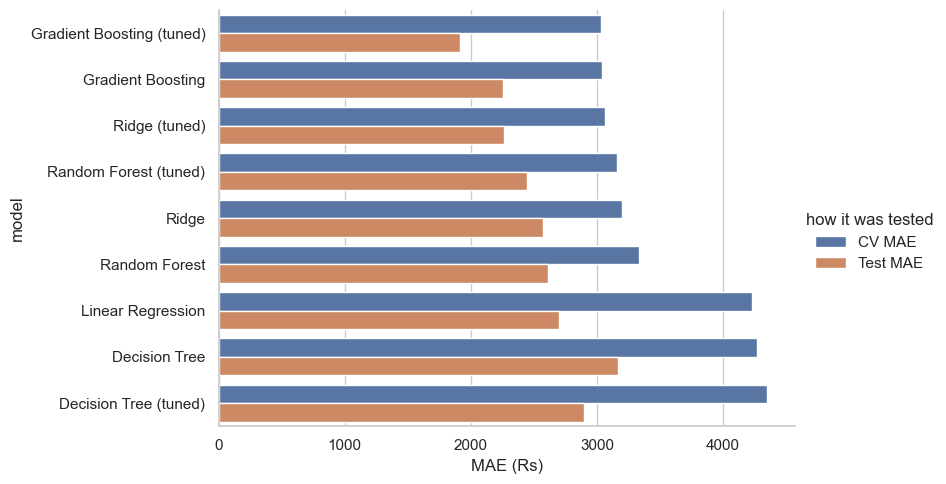

In [75]:
cmp_long = comparison.drop("Baseline (median)")[rank_cols].reset_index().melt(id_vars="index", var_name="how it was tested", value_name="MAE (Rs)")
sns.catplot(data=cmp_long, kind="bar", x="MAE (Rs)", y="index", hue="how it was tested", height=5, aspect=1.7).set(ylabel="model")

In [83]:
cc = comparison.drop("Baseline (median)")
gbd = cc.loc["Gradient Boosting"]
display(Markdown(f"""**📊 Analysis**

- **Winner on the deciding yardstick (grouped CV, training rows): {cc.index[0]}** with CV MAE Rs {cc.iloc[0]['CV MAE']:,.0f}, CV R² {cc.iloc[0]['CV R2']:.2f}, CV MAPE {cc.iloc[0]['CV MAPE %']:.1f}%. On the test set it scores MAE Rs {cc.iloc[0]['Test MAE']:,.0f}, R² {cc.iloc[0]['Test R2']:.2f}, MAPE {cc.iloc[0]['Test MAPE %']:.1f}%.
- Default Gradient Boosting: CV MAE Rs {gbd['CV MAE']:,.0f} (rank {int(gbd['rank (CV)'])} of {len(cc)}), test MAE Rs {gbd['Test MAE']:,.0f}. {'It is kept as the final model.' if final_name == 'Gradient Boosting' else 'It is not the final model.'}
- Best test MAE in the table: {cc['Test MAE'].idxmin()} (Rs {cc['Test MAE'].min():,.0f}); best CV MAE: {cc['CV MAE'].idxmin()} (Rs {cc['CV MAE'].min():,.0f}). {'Both views agree.' if cc['Test MAE'].idxmin() == cc['CV MAE'].idxmin() else 'The two views disagree, which shows how much a ' + str(len(X_test)) + '-row test set can move; the CV rule is the one that was fixed in advance.'}
- A simple linear model (Ridge) is at CV MAE Rs {cc.loc['Ridge', 'CV MAE']:,.0f}, i.e. {cc.loc['Ridge', 'CV MAE'] / cc.iloc[0]['CV MAE'] - 1:+.0%} versus the winner: {'a transparent fallback when pricing a new phone.' if cc.loc['Ridge', 'CV MAE'] / cc.iloc[0]['CV MAE'] - 1 < 0.15 else 'clearly weaker.'}
- Overfitting (train R² minus test R²): {', '.join(f"{n} {v:.2f}" for n, v in cc['R2 gap (train - test)'].items())}.
- Every real model beats the baseline (CV MAE Rs {comparison.loc['Baseline (median)', 'CV MAE']:,.0f})."""))

**📊 Analysis**

- **Winner on the deciding yardstick (grouped CV, training rows): Gradient Boosting (tuned)** with CV MAE Rs 3,033, CV R² 0.69, CV MAPE 15.4%. On the test set it scores MAE Rs 1,915, R² 0.71, MAPE 12.1%.
- Default Gradient Boosting: CV MAE Rs 3,041 (rank 2 of 9), test MAE Rs 2,256. It is not the final model.
- Best test MAE in the table: Gradient Boosting (tuned) (Rs 1,915); best CV MAE: Gradient Boosting (tuned) (Rs 3,033). Both views agree.
- A simple linear model (Ridge) is at CV MAE Rs 3,201, i.e. +6% versus the winner: a transparent fallback when pricing a new phone.
- Overfitting (train R² minus test R²): Gradient Boosting (tuned) 0.28, Gradient Boosting 0.46, Ridge (tuned) 0.08, Random Forest (tuned) 0.23, Ridge 0.28, Random Forest 0.26, Linear Regression 0.48, Decision Tree 0.56, Decision Tree (tuned) 0.22.
- Every real model beats the baseline (CV MAE Rs 7,542).

### 9.9 Where the data is thin (and what to add)
The error is not the same for every kind of phone. This section measures it with grouped out-of-fold predictions on the **training rows** and checks whether more rows would help.

,rows,MAPE
brand_tier,,
Challenger,6,13.0
Mainstream,329,14.6
Premium,14,36.1
Value,78,14.2


,rows,MAPE
price band,,
< 10k,143,13.2
10k-20k,183,13.5
20k-40k,84,17.3
> 40k,17,41.2


Brands with fewer than 10 listings (9 of 19): Google (9), OnePlus (5), Apple (5), itel (3), Nokia (3), Nothing (2), I Kall (2), iQOO (2), Lava (2)


,training rows,validation MAE,train MAE
0,102,4665.0,100.0
1,170,3659.0,208.0
2,238,3284.0,392.0
3,289,3203.0,539.0
4,341,3091.0,683.0


<Axes: xlabel='training rows', ylabel='MAE (Rs)'>

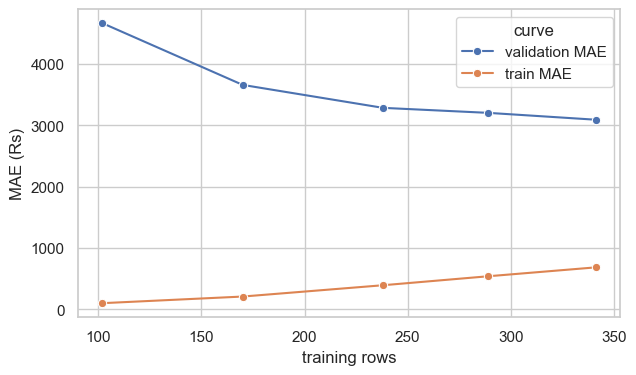

In [84]:
oof_train = cross_val_predict(final_model, X_train, y_train, cv=gkf, groups=GROUPS_TRAIN, n_jobs=-1)
cov = df.loc[X_train.index, ["brand", "brand_tier", "price"]].copy()
cov["ape %"] = np.abs(y_train.values - oof_train) / y_train.values * 100
cov["price band"] = pd.cut(cov["price"], [0, 10000, 20000, 40000, 1e9], labels=["< 10k", "10k-20k", "20k-40k", "> 40k"])

by_tier = cov.groupby("brand_tier").agg(rows=("price", "size"), MAPE=("ape %", "mean")).round(1)
by_band = cov.groupby("price band", observed=True).agg(rows=("price", "size"), MAPE=("ape %", "mean")).round(1)
brand_n = df["brand"].value_counts()
thin_brands = brand_n[brand_n < 10]
display(by_tier); display(by_band)
print(f"Brands with fewer than 10 listings ({len(thin_brands)} of {len(brand_n)}): {', '.join(f'{b} ({n})' for b, n in thin_brands.items())}")

# does more data help?  grouped learning curve of the final model on the training rows
sizes, lc_tr, lc_va = learning_curve(clone(final_model), X_train, y_train, groups=GROUPS_TRAIN, cv=GroupKFold(n_splits=5),
                                     train_sizes=[0.3, 0.5, 0.7, 0.85, 1.0], scoring="neg_mean_absolute_error", n_jobs=-1)
lc = pd.DataFrame({"training rows": sizes, "validation MAE": -lc_va.mean(axis=1), "train MAE": -lc_tr.mean(axis=1)})
display(lc.round(0))
plt.figure(figsize=(7, 4))      # fresh figure, so this chart never draws on top of the previous one
sns.lineplot(data=lc.melt("training rows", var_name="curve", value_name="MAE (Rs)"), x="training rows", y="MAE (Rs)", hue="curve", marker="o")

In [85]:
lo, hi = lc.iloc[0]["validation MAE"], lc.iloc[-1]["validation MAE"]
last_gain = lc.iloc[-2]["validation MAE"] - lc.iloc[-1]["validation MAE"]
display(Markdown(f"""**📊 Analysis**

- **Premium phones are the weak spot:** {by_tier.loc['Premium', 'rows'] if 'Premium' in by_tier.index else 0} training rows, MAPE {by_tier.loc['Premium', 'MAPE'] if 'Premium' in by_tier.index else float('nan'):.1f}%, against {by_tier.drop('Premium', errors='ignore')['MAPE'].min():.1f}% to {by_tier.drop('Premium', errors='ignore')['MAPE'].max():.1f}% for the other tiers. By price band the percentage error is largest for {by_band['MAPE'].idxmax()} phones ({by_band['MAPE'].max():.1f}%, {int(by_band.loc[by_band['MAPE'].idxmax(), 'rows'])} rows).
- {len(thin_brands)} of {len(brand_n)} brands have fewer than 10 listings, so a prediction for them rests on very little evidence.
- **More data should help:** with 30% of the training rows the validation MAE is Rs {lo:,.0f}; with all {len(X_train)} it is Rs {hi:,.0f}. {'The curve is still falling at the right-hand end (last step: Rs ' + format(last_gain, ',.0f') + ' better), so more listings would still improve the model.' if last_gain > 0 else 'The curve has flattened at the right-hand end, so extra rows of the same kind would help little; new kinds of phone and new features would help more.'}"""))

**📊 Analysis**

- **Premium phones are the weak spot:** 14 training rows, MAPE 36.1%, against 13.0% to 14.6% for the other tiers. By price band the percentage error is largest for > 40k phones (41.2%, 17 rows).
- 9 of 19 brands have fewer than 10 listings, so a prediction for them rests on very little evidence.
- **More data should help:** with 30% of the training rows the validation MAE is Rs 4,665; with all 427 it is Rs 3,091. The curve is still falling at the right-hand end (last step: Rs 112 better), so more listings would still improve the model.

**Data to add (priority order)**

| Priority | What to collect | Why |
|---|---|---|
| 1 | More **Premium and upper-mid phones** (Apple, Samsung S-series, Google Pixel, OnePlus, flagship Xiaomi/vivo/OPPO) and the brands with fewer than 10 listings | The expensive end has the fewest rows and the highest error; one flagship is worth many budget rows |
| 2 | **Launch / release date**, so phone age can be computed | A phone loses price with age; today the model cannot tell a 2022 phone from a 2023 one |
| 3 | **Launch price (MRP)**, **discount %** and the **actual sale price** next to the listing price | Listing prices are not sales prices; MRP is a strong anchor |
| 4 | Several price snapshots per phone over time | Shows how prices move, and gives a fairer target than one scraped day |
| 5 | A phone's **chipset benchmark score** and **display type / refresh rate** | Specs that buyers pay for but the current columns only hint at |

**Rules for the new rows:** keep every listing of one phone model in the same split (the notebook already does this through `phone_group`), do not let any new column be derived from the price, and re-run the whole notebook so that selection and tuning are repeated on the larger file.

## 10. Feature Importance Analysis
**Task:** check whether the trained model agrees with the feature-extraction ranking of Section 7, using three tools: permutation importance (10.1), the Random Forest's own importance (10.2) and **SHAP** (10.6).

### 10.1 Permutation importance of the final model (on the test set)

In [86]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=all_features).sort_values(ascending=False)
perm_share = perm_imp.clip(lower=0) / perm_imp.clip(lower=0).sum()
top15 = perm_imp.head(15).sort_values()

How much the error grows when one feature is shuffled.

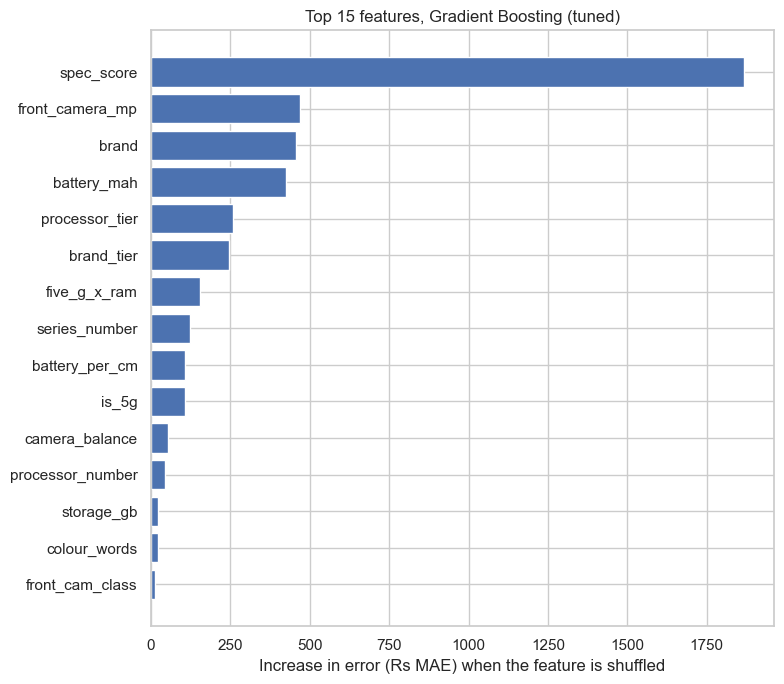

In [87]:
plt.figure(figsize=(8, 7))
plt.barh(top15.index, top15.values, color="#4C72B0")
plt.xlabel("Increase in error (Rs MAE) when the feature is shuffled")
plt.title(f"Top 15 features, {final_name}")
plt.tight_layout()
plt.show()

In [88]:
eng = [f for f in perm_imp.head(15).index if f in set(new_num + new_cat)]
zero = perm_imp[perm_imp <= 0].index.tolist()
display(Markdown(f"""**📊 Analysis**

- Method: shuffle one feature at a time on the test set and measure how much the prediction error rises. A big rise means the model relies on that feature. The test set has only {len(X_test)} rows, so the ranking is noisy.
- Top 5 by share of total importance: {', '.join(f"{f} ({perm_share[f]:.0%})" for f in perm_imp.head(5).index)}.
- {len(eng)} of the top 15 are engineered features: {eng}.
- Features whose shuffling does not hurt the model (importance <= 0): {zero}.
- When two features carry the same information, shuffling one barely hurts because the model uses the other, so their importance is SPLIT. Section 10.5 therefore also adds importance up by business theme."""))

**📊 Analysis**

- Method: shuffle one feature at a time on the test set and measure how much the prediction error rises. A big rise means the model relies on that feature. The test set has only 104 rows, so the ranking is noisy.
- Top 5 by share of total importance: spec_score (42%), front_camera_mp (11%), brand (10%), battery_mah (10%), processor_tier (6%).
- 10 of the top 15 are engineered features: ['spec_score', 'processor_tier', 'brand_tier', 'five_g_x_ram', 'series_number', 'battery_per_cm', 'camera_balance', 'processor_number', 'colour_words', 'front_cam_class'].
- Features whose shuffling does not hurt the model (importance <= 0): ['premium_x_config', 'basic_phone', 'ai_lens', 'name_lite', 'is_premium_brand', 'ram_gb', 'budget_spec', 'name_premium', 'core_type', 'ai_x_rear_cam', 'flagship_spec', 'battery_class', 'rear_cam_class', 'rear_camera_mp', 'ram_x_storage', 'config_score', 'storage_per_ram', 'processor_brand'].
- When two features carry the same information, shuffling one barely hurts because the model uses the other, so their importance is SPLIT. Section 10.5 therefore also adds importance up by business theme.

### 10.2 Built-in importance of the Random Forest (impurity), added up per original feature

In [89]:
rf_pipe = models["Random Forest"].regressor_
rf_names = rf_pipe.named_steps["pre"].get_feature_names_out()
rf_imp = pd.Series(rf_pipe.named_steps["reg"].feature_importances_, index=rf_names)

def origin_name(col):
    col = col.split("__", 1)[1]
    if col in num_features:
        return col
    for f in sorted(cat_features, key=len, reverse=True):
        if col.startswith(f + "_"):
            return f
    return col

rf_by_feature = rf_imp.groupby(origin_name).sum().reindex(all_features).sort_values(ascending=False)
display(pd.DataFrame({"RF impurity": rf_by_feature.head(10), "Permutation share": perm_share.reindex(rf_by_feature.head(10).index)}).round(3))

,RF impurity,Permutation share
spec_score,0.475,0.424
battery_mah,0.126,0.096
front_camera_mp,0.126,0.107
processor_tier,0.046,0.058
rear_cam_class,0.026,0.000
camera_balance,0.024,0.012
rear_camera_mp,0.024,0.000
basic_phone,0.022,0.000
mobile_height_cm,0.022,0.003
total_camera_mp,0.019,0.001


In [90]:
both = sorted(set(rf_by_feature.head(10).index) & set(perm_imp.head(10).index))
display(Markdown(f"""**📊 Analysis**

- Random Forest's built-in top 5: {', '.join(rf_by_feature.head(5).index)}.
- {len(both)} of the top 10 features appear in both the Random Forest ranking and the permutation ranking of the final model: {both}.
- Impurity importance can favour features with many distinct values, which is why permutation importance on the test set is the main measure and impurity is only a cross-check."""))

**📊 Analysis**

- Random Forest's built-in top 5: spec_score, battery_mah, front_camera_mp, processor_tier, rear_cam_class.
- 4 of the top 10 features appear in both the Random Forest ranking and the permutation ranking of the final model: ['battery_mah', 'front_camera_mp', 'processor_tier', 'spec_score'].
- Impurity importance can favour features with many distinct values, which is why permutation importance on the test set is the main measure and impurity is only a cross-check.

### 10.3 Does the trained model confirm the feature-extraction ranking?

Spearman rho between the two rankings: 0.29 (p = 0.0745); top-10 features in both: ['five_g_x_ram', 'front_camera_mp', 'processor_tier', 'spec_score']


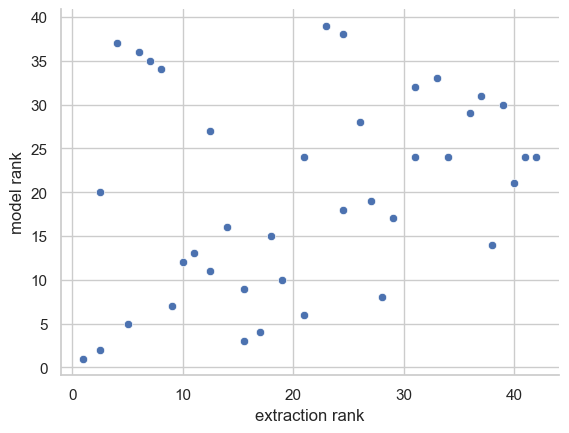

In [91]:
rank_perm = perm_imp.rank(ascending=False)
compare = pd.DataFrame({"extraction rank": extraction_rank["avg_rank"].rank(), "model rank": rank_perm}).dropna()
rho, p_rho = spearmanr(compare["extraction rank"], compare["model rank"])
top10_ext = set(extraction_rank.head(10).index)
top10_mod = set(perm_imp.head(10).index)
agree = sorted(top10_ext & top10_mod)

sns.relplot(data=compare, x="extraction rank", y="model rank", height=4.5, aspect=1.3)
print(f"Spearman rho between the two rankings: {rho:.2f} (p = {p_rho:.3g}); top-10 features in both: {agree}")

In [92]:
only_ext = sorted(top10_ext - top10_mod); only_mod = sorted(top10_mod - top10_ext)
level_ = "strong" if rho > 0.6 else ("moderate" if rho > 0.3 else "weak")
display(Markdown(f"""**📊 Analysis**

- Rank agreement between Section 7 and the trained model: Spearman rho = {rho:.2f} (p = {p_rho:.3g}), which is **{level_}**.
- {len(agree)} of the top 10 features are the same in both rankings: {agree}.
- In the extraction top 10 but not in the model's top 10: {only_ext}. In the model's top 10 but not in the extraction top 10: {only_mod}.
- {'The two views agree reasonably well.' if rho > 0.3 else 'The two views disagree, so conclusions should rest on the trained-model measures (10.1, 10.6), not on the univariate ranking alone.'} Keep in mind that Section 7 ranks features one at a time, while the model uses them together."""))

**📊 Analysis**

- Rank agreement between Section 7 and the trained model: Spearman rho = 0.29 (p = 0.0745), which is **weak**.
- 4 of the top 10 features are the same in both rankings: ['five_g_x_ram', 'front_camera_mp', 'processor_tier', 'spec_score'].
- In the extraction top 10 but not in the model's top 10: ['config_score', 'processor_number', 'ram_x_storage', 'rear_cam_class', 'rear_camera_mp', 'total_camera_mp']. In the model's top 10 but not in the extraction top 10: ['battery_mah', 'battery_per_cm', 'brand', 'brand_tier', 'is_5g', 'series_number'].
- The two views disagree, so conclusions should rest on the trained-model measures (10.1, 10.6), not on the univariate ranking alone. Keep in mind that Section 7 ranks features one at a time, while the model uses them together.

### 10.4 How many features do we really need?

,top-k features,MAE (unseen models)
0,2,4579.0
1,3,3712.0
2,4,3479.0
3,5,2960.0
4,6,2957.0
5,8,2889.0
6,10,2896.0
7,15,2921.0
8,25,3036.0
9,39,2998.0


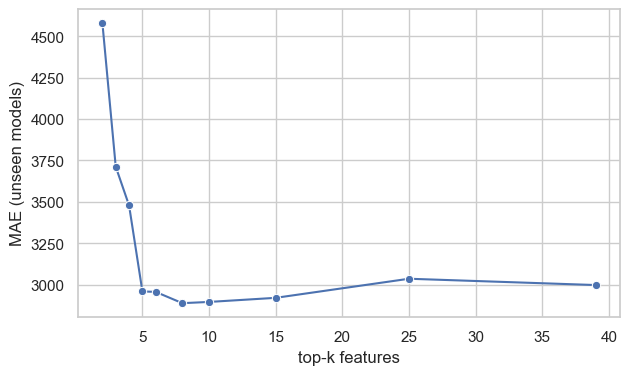

In [93]:
ks = [k for k in [2, 3, 4, 5, 6, 8, 10, 15, 25, len(all_features)] if k <= len(all_features)]
rows = []
for k in ks:
    feats = perm_imp.head(k).index.tolist()
    num_k = [f for f in feats if f in num_features]
    cat_k = [f for f in feats if f in cat_features]
    mdl = make_model(GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE), num=num_k, cat=cat_k)
    mae_k = -cross_val_score(mdl, X_train[feats], y_train, cv=gkf, groups=GROUPS_TRAIN, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
    rows.append({"top-k features": k, "MAE (unseen models)": mae_k})
topk = pd.DataFrame(rows)
display(topk.round(0))
plt.figure(figsize=(7, 4))      # fresh figure, so this chart never draws on top of the previous one
sns.lineplot(data=topk, x="top-k features", y="MAE (unseen models)", marker="o")

best_k_mae = topk["MAE (unseen models)"].min()
k_needed = int(topk[topk["MAE (unseen models)"] <= best_k_mae * 1.05]["top-k features"].min())

In [94]:
best_k = int(topk.loc[topk["MAE (unseen models)"].idxmin(), "top-k features"])
display(Markdown(f"""**📊 Analysis**

- Features are added in order of permutation importance and scored with grouped CV on the **training rows**. Lowest error: Rs {best_k_mae:,.0f} with {best_k} features; with all {len(all_features)} features Rs {topk['MAE (unseen models)'].iloc[-1]:,.0f}.
- Only {k_needed} features are needed to come within 5% of the best error: {perm_imp.head(k_needed).index.tolist()}.
- The ranking of features comes from the test-set permutation importance, the scoring from the training rows, so the two steps do not share the same rows. With a few hundred rows the curve is noisy: treat the number of features as a rough guide."""))

**📊 Analysis**

- Features are added in order of permutation importance and scored with grouped CV on the **training rows**. Lowest error: Rs 2,889 with 8 features; with all 39 features Rs 2,998.
- Only 5 features are needed to come within 5% of the best error: ['spec_score', 'front_camera_mp', 'brand', 'battery_mah', 'processor_tier'].
- The ranking of features comes from the test-set permutation importance, the scoring from the training rows, so the two steps do not share the same rows. With a few hundred rows the curve is noisy: treat the number of features as a rough guide.

### 10.5 Importance by business theme

,theme,share of importance
0,Overall spec level,0.424
1,Brand,0.159
2,Cameras,0.122
3,Battery,0.121
4,Processor,0.068
5,5G label,0.059
6,Model name,0.030
7,RAM and storage,0.008
8,Colour,0.006
9,Screen height,0.003


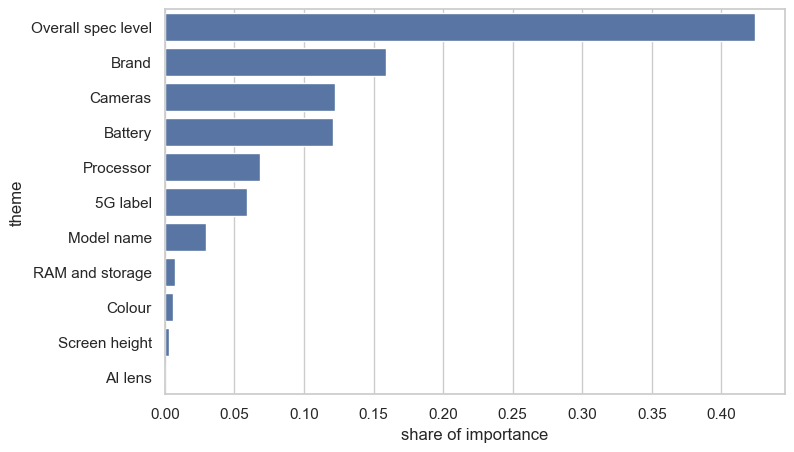

In [95]:
CONCEPT = {
    "Brand": ["brand", "brand_tier", "brand_count", "is_premium_brand", "premium_x_config"],
    "RAM and storage": ["ram_gb", "storage_gb", "config_score", "ram_x_storage", "storage_per_ram", "ram_class", "storage_class"],
    "Cameras": ["rear_camera_mp", "front_camera_mp", "total_camera_mp", "camera_balance", "rear_cam_class", "front_cam_class", "ai_x_rear_cam"],
    "Overall spec level": ["spec_score", "flagship_spec", "budget_spec", "basic_phone"],
    "Battery": ["battery_mah", "battery_class", "battery_per_cm"],
    "Processor": ["processor_brand", "processor_tier", "processor_number", "core_type"],
    "5G label": ["is_5g", "five_g_x_ram"],
    "Colour": ["colour_family", "colour_words"],
    "AI lens": ["ai_lens"],
    "Screen height": ["mobile_height_cm"],
    "Model name": ["name_words", "name_premium", "name_lite", "series_number", "model_variants", "model_colours"],
}
covered = {f for fs in CONCEPT.values() for f in fs}
leftover = [f for f in all_features if f not in covered]
if leftover:
    CONCEPT["Other"] = leftover

theme_share = pd.Series({k: perm_share.reindex(v).sum() for k, v in CONCEPT.items()}).sort_values(ascending=False)
theme_df = theme_share.rename("share of importance").reset_index().rename(columns={"index": "theme"})
plt.figure(figsize=(8, 5))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=theme_df, x="share of importance", y="theme", color="#4C72B0")
display(theme_df.round(3))

In [96]:
display(Markdown(f"""**📊 Analysis**

- Importance of related features is added up so that overlapping features (for example RAM, storage and their combined score) are not under-counted.
- Ranking of themes: {', '.join(f"{k} {v:.0%}" for k, v in theme_share.items())}.
- Biggest theme: {theme_share.index[0]} ({theme_share.iloc[0]:.0%}); smallest: {theme_share.index[-1]} ({theme_share.iloc[-1]:.0%}). Note that permutation importance can give an overall-spec feature near-zero credit when RAM, storage and cameras carry the same information; compare with SHAP in 10.6.5."""))

**📊 Analysis**

- Importance of related features is added up so that overlapping features (for example RAM, storage and their combined score) are not under-counted.
- Ranking of themes: Overall spec level 42%, Brand 16%, Cameras 12%, Battery 12%, Processor 7%, 5G label 6%, Model name 3%, RAM and storage 1%, Colour 1%, Screen height 0%, AI lens 0%.
- Biggest theme: Overall spec level (42%); smallest: AI lens (0%). Note that permutation importance can give an overall-spec feature near-zero credit when RAM, storage and cameras carry the same information; compare with SHAP in 10.6.5.

### 10.6 SHAP explainability (why does the model give *this* price to *this* phone?)
Permutation importance (10.1) says **which features matter overall**. **SHAP** goes further: it splits every single prediction into a **contribution from each feature**.

How to read SHAP, part by part:
- The model works in **log(price)**, so SHAP values are in log units. A SHAP value of +0.10 means "this feature pushes the price about **10 % up**" (`exp(0.10) - 1`); -0.10 pushes it about 9.5 % down.
- For one phone: `base value + all SHAP values = the model's prediction`. The **base value** is the model's price for an "average" phone.
- **Summary (beeswarm) plot:** one dot per phone and feature. Position left/right = push down/up; colour = the feature's own value (red high, blue low). Red dots on the right = "high value raises price".
- **Dependence plot:** the feature's value on the x-axis and its SHAP value on the y-axis = the shape of its effect.
- **Waterfall plot:** the story of one phone, from the base value to its final price.

SHAP needs the `shap` package (`pip install shap`). Dummy (one-hot) columns are added back together, so every bar below is one *original* feature such as `brand`.

#### 10.6.1 Compute the SHAP values

In [97]:
try:
    import shap
except ImportError:
    raise ImportError("SHAP is not installed. Run  pip install shap  in a terminal (or a cell), then re-run this cell.")

pipe = final_model.regressor_                                   # the fitted pipeline inside the log-price wrapper
pre, reg = pipe.named_steps["pre"], pipe.named_steps["reg"]
enc_names = [c.split("__", 1)[1] for c in pre.get_feature_names_out()]
X_test_t = pd.DataFrame(pre.transform(X_test), columns=enc_names, index=X_test.index)       # the numbers the model really sees
X_train_t = pd.DataFrame(pre.transform(X_train), columns=enc_names, index=X_train.index)

if hasattr(reg, "feature_importances_"):                        # tree models: exact and fast
    explainer = shap.TreeExplainer(reg)
else:                                                           # linear models
    explainer = shap.LinearExplainer(reg, X_train_t)
sv = explainer(X_test_t)                                        # SHAP values, in log(price) units
base_price = float(np.exp(np.ravel(sv.base_values)[0]))

gap = np.abs(sv.values.sum(axis=1) + np.ravel(sv.base_values) - reg.predict(X_test_t)).max()
print(f"Explained model: {final_name}; {X_test_t.shape[1]} encoded columns; {len(X_test_t)} test phones")
print(f"Base value (the model's price for an average phone): Rs {base_price:,.0f}")
print(f"Check: base value + SHAP values rebuild the model output (largest gap {gap:.1e})")

shap_cols = pd.DataFrame(sv.values, columns=enc_names, index=X_test.index)
shap_by_feature = shap_cols.T.groupby(origin).sum().T           # one-hot columns added back to their original feature
shap_imp = shap_by_feature.abs().mean().sort_values(ascending=False)
shap_share = shap_imp / shap_imp.sum()
display(pd.DataFrame({"mean |SHAP| (log units)": shap_imp, "typical price effect (%)": (np.exp(shap_imp) - 1) * 100,
                      "share of total": shap_share}).head(15).round(3))

Explained model: Gradient Boosting (tuned); 91 encoded columns; 104 test phones
Base value (the model's price for an average phone): Rs 13,445
Check: base value + SHAP values rebuild the model output (largest gap 2.0e-14)


,mean |SHAP| (log units),typical price effect (%),share of total
spec_score,0.191,21.035,0.277
front_camera_mp,0.080,8.348,0.116
processor_tier,0.054,5.567,0.079
battery_mah,0.048,4.960,0.070
brand_tier,0.045,4.580,0.065
brand,0.039,3.996,0.057
five_g_x_ram,0.037,3.718,0.053
is_5g,0.022,2.261,0.032
storage_gb,0.020,2.011,0.029
series_number,0.013,1.347,0.019


In [98]:
s1, s2 = shap_imp.index[0], shap_imp.index[1]
display(Markdown(f"""**📊 Analysis**

- **The SHAP values are exact:** base value plus SHAP values rebuilds the model output to {gap:.1e}. The base value is Rs {base_price:,.0f}: the model's price for an "average" phone before any feature is considered.
- **Top two features:** `{s1}` (mean |SHAP| {shap_imp[s1]:.3f} log units, a typical push of {(np.exp(shap_imp[s1]) - 1):.0%}, share {shap_share[s1]:.0%}) and `{s2}` ({shap_imp[s2]:.3f}, {(np.exp(shap_imp[s2]) - 1):.0%}, share {shap_share[s2]:.0%}). Together they hold {shap_share[[s1, s2]].sum():.0%} of all SHAP importance.
- **Next group:** {', '.join(f"`{f}` ({shap_share[f]:.1%})" for f in shap_imp.index[2:8])}.
- "Typical price effect" is the average size of the push on a phone (`exp(mean |SHAP|) - 1`), **not** the effect of one extra unit of the feature.
- `spec_score` is a combined feature (a fixed-scale index of RAM, storage and both cameras), so it absorbs part of what RAM and storage would show on their own."""))

**📊 Analysis**

- **The SHAP values are exact:** base value plus SHAP values rebuilds the model output to 2.0e-14. The base value is Rs 13,445: the model's price for an "average" phone before any feature is considered.
- **Top two features:** `spec_score` (mean |SHAP| 0.191 log units, a typical push of 21%, share 28%) and `front_camera_mp` (0.080, 8%, share 12%). Together they hold 39% of all SHAP importance.
- **Next group:** `processor_tier` (7.9%), `battery_mah` (7.0%), `brand_tier` (6.5%), `brand` (5.7%), `five_g_x_ram` (5.3%), `is_5g` (3.2%).
- "Typical price effect" is the average size of the push on a phone (`exp(mean |SHAP|) - 1`), **not** the effect of one extra unit of the feature.
- `spec_score` is a combined feature (a fixed-scale index of RAM, storage and both cameras), so it absorbs part of what RAM and storage would show on their own.

#### 10.6.2 Global view: summary (beeswarm) plot **[shap]**
Each dot is one test phone. The columns are the encoded model inputs (so a brand shows up as `brand_Apple`, a 0/1 column).

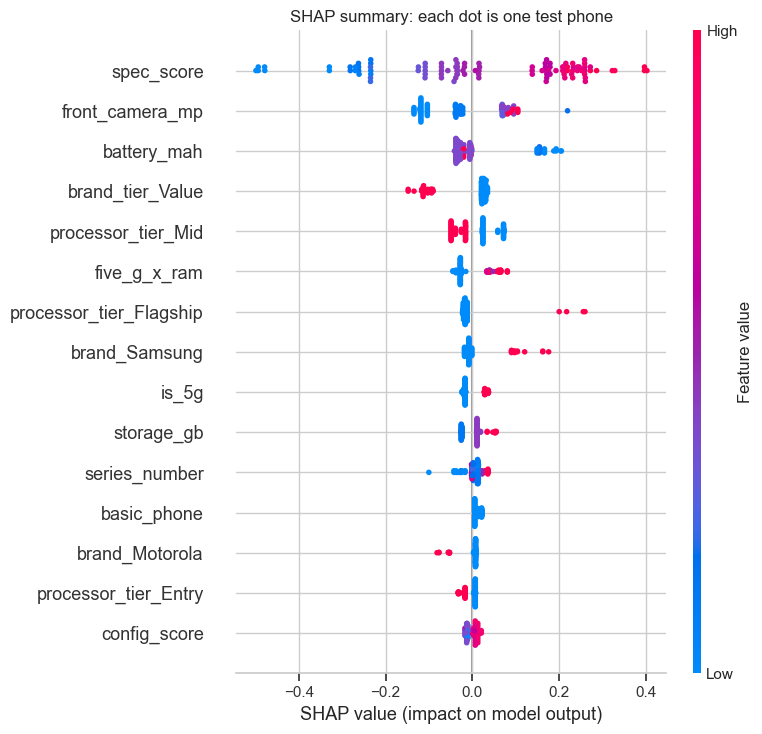

In [99]:
shap.summary_plot(sv.values, X_test_t, max_display=15, show=False)
plt.title("SHAP summary: each dot is one test phone")
plt.tight_layout()
plt.show()

In [100]:
lines = []
for f in shap_imp.index[:6]:
    if f in num_features:
        rho_f = spearmanr(X_test[f], shap_by_feature[f])[0]
        way = "raise" if rho_f > 0.3 else ("lower" if rho_f < -0.3 else "have a mixed effect on")
        lines.append(f"- **{f}:** higher values {way} the predicted price (rank correlation between value and SHAP {rho_f:+.2f}); SHAP ranges from {shap_by_feature[f].min():+.2f} to {shap_by_feature[f].max():+.2f} log units.")
    else:
        g = shap_by_feature[f].groupby(X_test[f]).agg(["mean", "size"])
        g = g[g["size"] >= 3].sort_values("mean")
        if len(g) >= 2:
            lines.append(f"- **{f}:** pushes the price down most for {g.index[0]} ({g['mean'].iloc[0]:+.2f}) and up most for {g.index[-1]} ({g['mean'].iloc[-1]:+.2f}) (categories with 3+ test phones).")
display(Markdown("**📊 Analysis**\n\n" + "\n".join(lines) +
                 "\n\n- A feature that runs the opposite way to common sense (for example a smaller battery pushing the price up) usually stands in for something else, such as a premium brand. Read the direction as an association in this data, not as a reason customers pay more."))

**📊 Analysis**

- **spec_score:** higher values raise the predicted price (rank correlation between value and SHAP +0.97); SHAP ranges from -0.50 to +0.40 log units.
- **front_camera_mp:** higher values raise the predicted price (rank correlation between value and SHAP +0.95); SHAP ranges from -0.13 to +0.22 log units.
- **processor_tier:** pushes the price down most for Mid (-0.05) and up most for Flagship (+0.31) (categories with 3+ test phones).
- **battery_mah:** higher values lower the predicted price (rank correlation between value and SHAP -0.41); SHAP ranges from -0.04 to +0.21 log units.
- **brand_tier:** pushes the price down most for Value (-0.11) and up most for Challenger (+0.03) (categories with 3+ test phones).
- **brand:** pushes the price down most for Motorola (-0.08) and up most for OPPO (+0.13) (categories with 3+ test phones).

- A feature that runs the opposite way to common sense (for example a smaller battery pushing the price up) usually stands in for something else, such as a premium brand. Read the direction as an association in this data, not as a reason customers pay more.

The same information added up per original feature (one bar per feature, one-hot columns merged).

<Axes: xlabel='mean |SHAP| (log units)', ylabel='feature'>

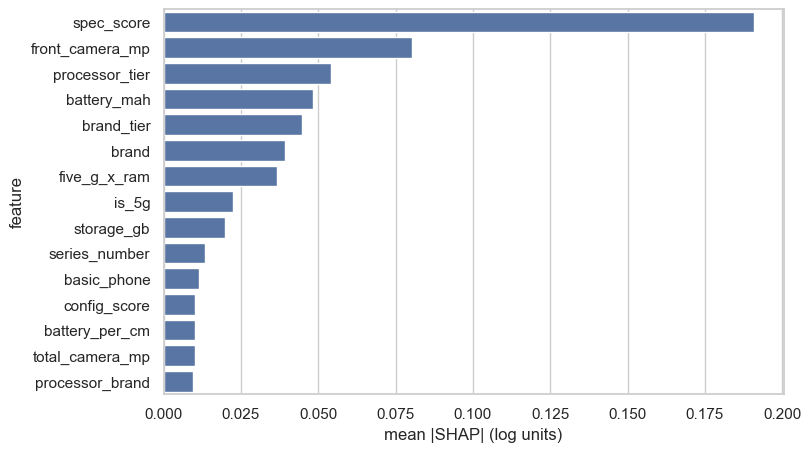

In [101]:
shap_plot = shap_imp.head(15).rename_axis("feature").reset_index(name="mean |SHAP| (log units)")
plt.figure(figsize=(8, 5))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=shap_plot, x="mean |SHAP| (log units)", y="feature", color="#4C72B0")

In [102]:
cum = shap_share.cumsum()
n80 = int((cum < 0.80).sum() + 1)
display(Markdown(f"""**📊 Analysis**

- The same ranking as the table in 10.6.1, now with one bar per original feature. The top bar (`{shap_imp.index[0]}`) is {shap_imp.iloc[0] / shap_imp.iloc[2]:.1f} times as long as the third (`{shap_imp.index[2]}`).
- The first {n80} features carry 80% of the total SHAP importance (out of {len(shap_imp)}); the rest add little. Compare with 10.4: {k_needed} features were enough for near-best accuracy.
- Features with the smallest SHAP importance: {', '.join(shap_imp.index[-5:])}."""))

**📊 Analysis**

- The same ranking as the table in 10.6.1, now with one bar per original feature. The top bar (`spec_score`) is 3.5 times as long as the third (`processor_tier`).
- The first 11 features carry 80% of the total SHAP importance (out of 39); the rest add little. Compare with 10.4: 5 features were enough for near-best accuracy.
- Features with the smallest SHAP importance: front_cam_class, name_premium, budget_spec, name_lite, ai_lens.

#### 10.6.3 Shape of each effect: dependence plots **[shap]**
For the three most important numeric features: the feature's value (x) against how much it moves the predicted log price (y). A rising line = more of it means a higher price; a flat line = no effect; a step = a threshold effect.

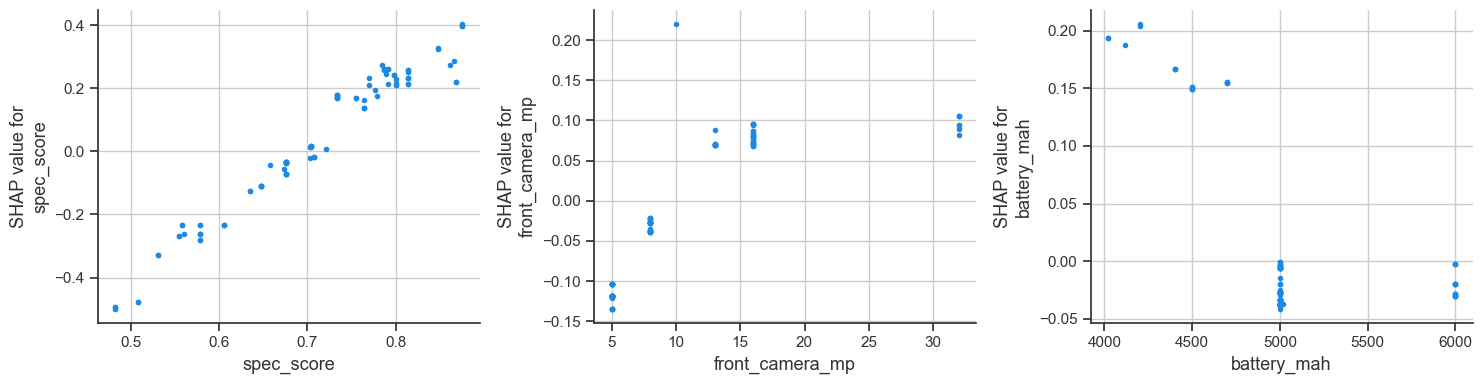

In [103]:
top_num = [f for f in shap_imp.index if f in num_features][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, top_num):
    shap.dependence_plot(f, sv.values, X_test_t, interaction_index=None, ax=ax, show=False)
plt.tight_layout()
plt.show()

In [104]:
lines = []
for f in top_num:
    bins = pd.qcut(X_test[f].rank(method="first"), 4, labels=False)
    m = shap_by_feature[f].groupby(bins).mean()
    shape = "rises steadily" if m.is_monotonic_increasing else ("falls steadily" if m.is_monotonic_decreasing else "is not monotonic")
    lines.append(f"- **{f}:** the average SHAP value by quarter of the feature (low to high) is {', '.join(f'{v:+.2f}' for v in m.values)}; the effect {shape}. From the lowest to the highest quarter the price effect moves by about {np.exp(m.iloc[-1] - m.iloc[0]):.1f}x.")
fc = shap_by_feature["front_camera_mp"].groupby(X_test["front_camera_mp"]).agg(["mean", "size"]) if "front_camera_mp" in shap_by_feature else None
if fc is not None:
    fc = fc[fc["size"] >= 3]
    lines.append("- **front_camera_mp, value by value** (values with 3+ test phones): " + ", ".join(f"{int(i)} MP {row['mean']:+.2f}" for i, row in fc.iterrows()) + ". Where consecutive values show almost no further rise, extra megapixels add little to the predicted price.")
display(Markdown("**📊 Analysis**\n\n" + "\n".join(lines)))

**📊 Analysis**

- **spec_score:** the average SHAP value by quarter of the feature (low to high) is -0.28, -0.04, +0.17, +0.26; the effect rises steadily. From the lowest to the highest quarter the price effect moves by about 1.7x.
- **front_camera_mp:** the average SHAP value by quarter of the feature (low to high) is -0.12, -0.05, +0.04, +0.09; the effect rises steadily. From the lowest to the highest quarter the price effect moves by about 1.2x.
- **battery_mah:** the average SHAP value by quarter of the feature (low to high) is +0.10, -0.03, -0.02, -0.02; the effect is not monotonic. From the lowest to the highest quarter the price effect moves by about 0.9x.
- **front_camera_mp, value by value** (values with 3+ test phones): 5 MP -0.12, 8 MP -0.03, 13 MP +0.07, 16 MP +0.08, 32 MP +0.10. Where consecutive values show almost no further rise, extra megapixels add little to the predicted price.

#### 10.6.4 One phone at a time: waterfall plots **[shap]**
Three cases: the most expensive test phone (which is also the one the model got most wrong), the cheapest one, and a typical mid-range phone. Each bar is one feature (or one-hot column); red pushes the price up, blue pushes it down.

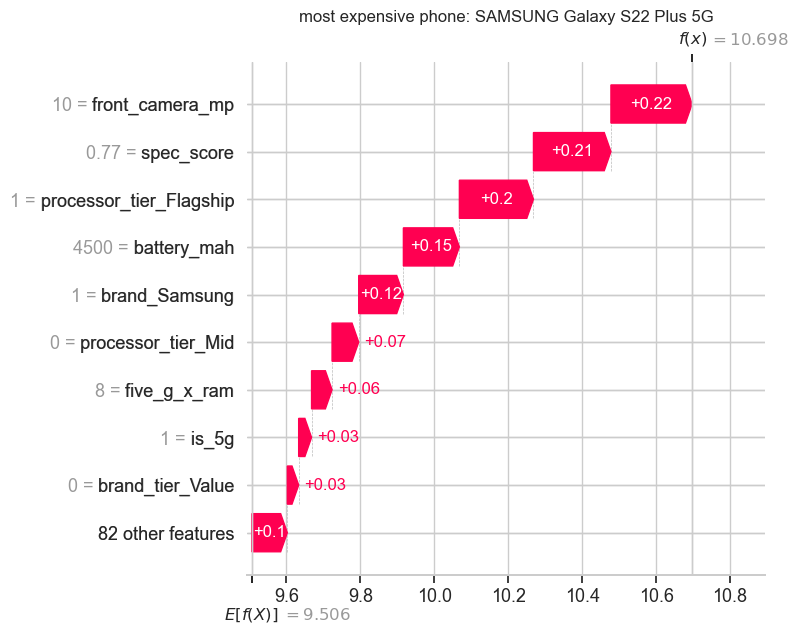

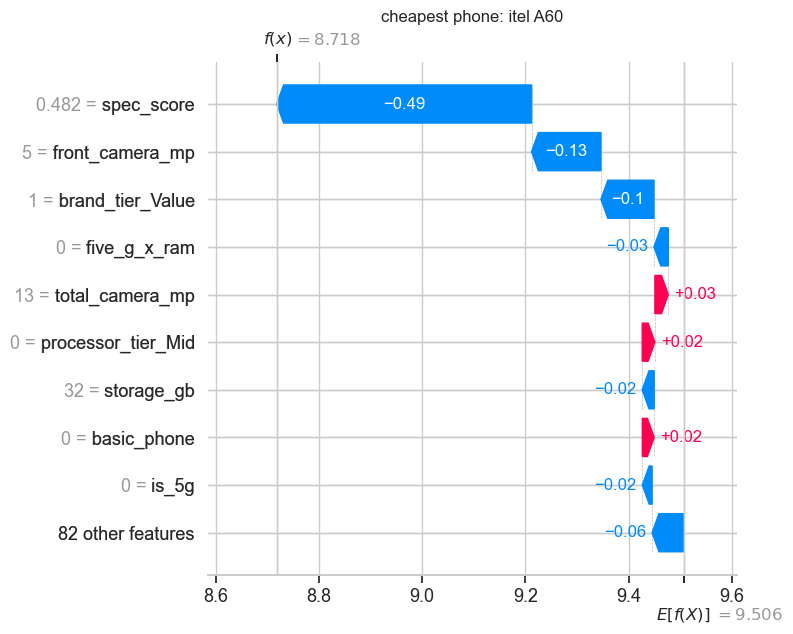

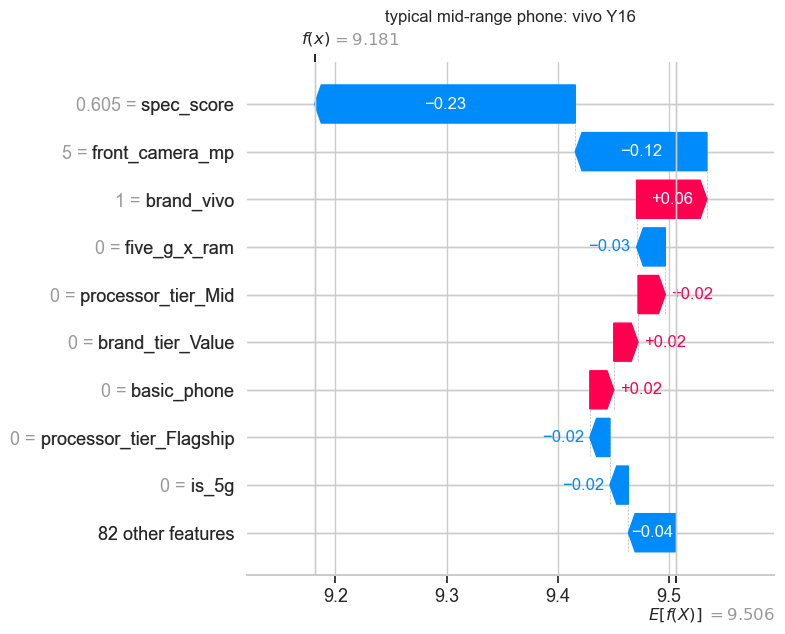

,case,phone,actual (Rs),predicted (Rs)
0,most expensive phone,SAMSUNG Galaxy S22 Plus 5G,49999,44245.0
1,cheapest phone,itel A60,5990,6114.0
2,typical mid-range phone,vivo Y16,12990,9713.0


most expensive phone (SAMSUNG Galaxy S22 Plus 5G): processor_tier (+31%), front_camera_mp (+25%), spec_score (+23%)
cheapest phone (itel A60): spec_score (-39%), front_camera_mp (-13%), brand_tier (-10%)
typical mid-range phone (vivo Y16): spec_score (-21%), front_camera_mp (-11%), brand (+6%)


In [105]:
pos = {"most expensive phone": int(np.argmax(y_test.values)),
       "cheapest phone": int(np.argmin(y_test.values)),
       "typical mid-range phone": int(np.argmin(np.abs(y_test.values - np.median(y_test.values))))}
case_rows = []
for label, i in pos.items():
    top3 = shap_by_feature.iloc[i].sort_values(key=abs, ascending=False).head(3)
    case_rows.append({"case": label, "phone": df.loc[X_test.index[i], "model"], "actual (Rs)": y_test.values[i], "predicted (Rs)": pred[i],
                      "biggest reasons": ", ".join(f"{k} ({(np.exp(v) - 1) * 100:+.0f}%)" for k, v in top3.items())})
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{label}: {df.loc[X_test.index[i], 'model']}")
    plt.tight_layout()
    plt.show()
display(pd.DataFrame(case_rows).drop(columns="biggest reasons").round(0))
for row in case_rows:
    print(f"{row['case']} ({row['phone']}): {row['biggest reasons']}")

In [106]:
lines = []
for row in case_rows:
    ratio = row["predicted (Rs)"] / row["actual (Rs)"]
    lines.append(f"- **{row['case'].capitalize()}, {row['phone']} (real Rs {row['actual (Rs)']:,.0f}, predicted Rs {row['predicted (Rs)']:,.0f}, predicted/real {ratio:.2f}):** biggest reasons: {row['biggest reasons']}. Starting from the base value of Rs {base_price:,.0f}.")
display(Markdown("**📊 Analysis**\n\n" + "\n".join(lines) +
                 "\n\n- **Lesson:** SHAP turns every price into a short list of reasons that a pricing team can check phone by phone. When the reasons look incomplete or the prediction is far from the real price, that is a sign the model needs more data or a feature for that segment, or that the listing itself is wrong."))

**📊 Analysis**

- **Most expensive phone, SAMSUNG Galaxy S22 Plus 5G (real Rs 49,999, predicted Rs 44,245, predicted/real 0.88):** biggest reasons: processor_tier (+31%), front_camera_mp (+25%), spec_score (+23%). Starting from the base value of Rs 13,445.
- **Cheapest phone, itel A60 (real Rs 5,990, predicted Rs 6,114, predicted/real 1.02):** biggest reasons: spec_score (-39%), front_camera_mp (-13%), brand_tier (-10%). Starting from the base value of Rs 13,445.
- **Typical mid-range phone, vivo Y16 (real Rs 12,990, predicted Rs 9,713, predicted/real 0.75):** biggest reasons: spec_score (-21%), front_camera_mp (-11%), brand (+6%). Starting from the base value of Rs 13,445.

- **Lesson:** SHAP turns every price into a short list of reasons that a pricing team can check phone by phone. When the reasons look incomplete or the prediction is far from the real price, that is a sign the model needs more data or a feature for that segment, or that the listing itself is wrong.

#### 10.6.5 Does SHAP agree with permutation importance and with the business themes?
Two independent ways of measuring importance should tell a similar story. Rank correlation near 1 = strong agreement. The theme table adds the SHAP share per business theme next to the permutation share from 10.5.

In [107]:
cmp_sp = pd.DataFrame({"SHAP rank": shap_imp.rank(ascending=False), "permutation rank": perm_imp.rank(ascending=False)}).dropna()
rho_sp, p_sp = spearmanr(cmp_sp["SHAP rank"], cmp_sp["permutation rank"])
agree_sp = sorted(set(shap_imp.head(10).index) & set(perm_imp.head(10).index))
sns.relplot(data=cmp_sp, x="SHAP rank", y="permutation rank", height=4.5, aspect=1.3)
print(f"Spearman rho between SHAP and permutation rankings: {rho_sp:.2f} (p = {p_sp:.3g}); top-10 features in both: {agree_sp}")

theme_shap = pd.Series({k: shap_share.reindex(v).sum() for k, v in CONCEPT.items()}).sort_values(ascending=False)
display(pd.DataFrame({"SHAP share": theme_shap, "Permutation share (10.5)": theme_share.reindex(theme_shap.index)}).round(3))

Spearman rho between SHAP and permutation rankings: 0.56 (p = 0.000245); top-10 features in both: ['battery_mah', 'brand', 'brand_tier', 'five_g_x_ram', 'front_camera_mp', 'is_5g', 'processor_tier', 'series_number', 'spec_score']


,SHAP share,Permutation share (10.5)
Overall spec level,0.299,0.424
Cameras,0.164,0.122
Brand,0.140,0.159
Processor,0.099,0.068
Battery,0.087,0.121
5G label,0.085,0.059
RAM and storage,0.074,0.008
Model name,0.032,0.030
Colour,0.011,0.006
Screen height,0.009,0.003


In [108]:
cmpt = pd.DataFrame({"SHAP": theme_shap, "Permutation": theme_share.reindex(theme_shap.index)})
diff = (cmpt["SHAP"] - cmpt["Permutation"]).abs().sort_values(ascending=False)
lvl = "strong" if rho_sp > 0.6 else ("moderate" if rho_sp > 0.3 else "weak")
d1 = diff.index[0]
display(Markdown(f"""**📊 Analysis**

- **Agreement of the two rankings:** Spearman rho {rho_sp:.2f} (p = {p_sp:.3g}), which is **{lvl}**; {len(agree_sp)} of the top 10 features are the same: {agree_sp}.
- **Business themes, SHAP share vs permutation share:** {'; '.join(f"{k} {row['SHAP']:.0%} vs {row['Permutation']:.0%}" for k, row in cmpt.iterrows())}.
- **Largest disagreement:** {d1} (SHAP {cmpt.loc[d1, 'SHAP']:.0%} vs permutation {cmpt.loc[d1, 'Permutation']:.0%}). When two features carry the same information, permutation importance splits or under-counts their credit, while SHAP shares it, so the theme view is the safer way to compare.
- **Top three themes:** SHAP {', '.join(theme_shap.index[:3])}; permutation {', '.join(theme_share.index[:3])}. {'Both methods agree on the top three.' if set(theme_shap.index[:3]) == set(theme_share.index[:3]) else 'The methods do not agree on the top three, so state conclusions about themes with care.'}"""))

**📊 Analysis**

- **Agreement of the two rankings:** Spearman rho 0.56 (p = 0.000245), which is **moderate**; 9 of the top 10 features are the same: ['battery_mah', 'brand', 'brand_tier', 'five_g_x_ram', 'front_camera_mp', 'is_5g', 'processor_tier', 'series_number', 'spec_score'].
- **Business themes, SHAP share vs permutation share:** Overall spec level 30% vs 42%; Cameras 16% vs 12%; Brand 14% vs 16%; Processor 10% vs 7%; Battery 9% vs 12%; 5G label 9% vs 6%; RAM and storage 7% vs 1%; Model name 3% vs 3%; Colour 1% vs 1%; Screen height 1% vs 0%; AI lens 0% vs 0%.
- **Largest disagreement:** Overall spec level (SHAP 30% vs permutation 42%). When two features carry the same information, permutation importance splits or under-counts their credit, while SHAP shares it, so the theme view is the safer way to compare.
- **Top three themes:** SHAP Overall spec level, Cameras, Brand; permutation Overall spec level, Brand, Cameras. Both methods agree on the top three.

## 11. Report and Visualization
### 11.1 Median price by RAM and storage

In [109]:
pt = df.pivot_table(index="ram_gb", columns="storage_gb", values="price", aggfunc="median")
plt.figure(figsize=(7, 5))      # fresh figure, so this chart never draws on top of the previous one
sns.heatmap(pt, annot=True, fmt=",.0f", cmap="YlGnBu")

<Axes: xlabel='storage_gb', ylabel='ram_gb'>

In [110]:
st_ = pt.stack()
display(Markdown(f"""**📊 Analysis**

- Cheapest configuration shown: {int(st_.idxmin()[0])} GB RAM / {int(st_.idxmin()[1])} GB storage at Rs {st_.min():,.0f}; most expensive: {int(st_.idxmax()[0])} GB / {int(st_.idxmax()[1])} GB at Rs {st_.max():,.0f}.
- Reading across a row shows what extra storage adds; reading down a column shows what extra RAM adds. Empty cells are combinations that do not exist in the data. Cells with a single listing (very high or very low) are less reliable than cells with many.
- Medians are used instead of averages so a few very expensive phones do not distort each cell."""))

**📊 Analysis**

- Cheapest configuration shown: 4 GB RAM / 16 GB storage at Rs 1,310; most expensive: 3 GB / 128 GB at Rs 80,999.
- Reading across a row shows what extra storage adds; reading down a column shows what extra RAM adds. Empty cells are combinations that do not exist in the data. Cells with a single listing (very high or very low) are less reliable than cells with many.
- Medians are used instead of averages so a few very expensive phones do not distort each cell.

### 11.2 Like-for-like effect of each spec step (what does one extra step add, holding the others fixed?)

In [111]:
lf = pd.DataFrame({"RAM doubled": np.log2(df["ram_gb"]), "Storage doubled": np.log2(df["storage_gb"]),
                   "Rear camera +10 MP": df["rear_camera_mp"] / 10, "Front camera +10 MP": df["front_camera_mp"] / 10,
                   "Battery +1000 mAh": df["battery_mah"] / 1000, "5G label": df["is_5g"], "AI lens": df["ai_lens"]})
brand_dummies = pd.get_dummies(df["brand"], drop_first=True, dtype=int)
lin = LinearRegression().fit(pd.concat([lf, brand_dummies], axis=1), df["price_log"])
effects = pd.Series(lin.coef_[:lf.shape[1]], index=lf.columns)
pct = ((np.exp(effects) - 1) * 100).sort_values()
effect_df = pct.rename("price change (%)").reset_index().rename(columns={"index": "spec step"})
plt.figure(figsize=(8, 4.5))      # fresh figure, so this chart never draws on top of the previous one
sns.barplot(data=effect_df, x="price change (%)", y="spec step", color="#55A868")
display(effect_df.round(1))

,spec step,price change (%)
0,AI lens,-5.4
1,Rear camera +10 MP,2.3
2,RAM doubled,11.0
3,Battery +1000 mAh,14.3
4,Front camera +10 MP,18.2
5,Storage doubled,19.5
6,5G label,29.5


In [112]:
ed = effect_df.sort_values("price change (%)", ascending=False)
display(Markdown(f"""**📊 Analysis**

- A linear model on log(price) with the brand included estimates the average % price change for one step of each spec while the brand and the other specs stay the same.
- {'; '.join(f"{row['spec step']}: {row['price change (%)']:+.1f}%" for _, row in ed.iterrows())}.
- Important: these are associations from listing data, not proven causes, and the features overlap, so treat the numbers as rough guides. The model uses all {len(df)} rows and has no hold-out, because it is used for description, not prediction."""))

**📊 Analysis**

- A linear model on log(price) with the brand included estimates the average % price change for one step of each spec while the brand and the other specs stay the same.
- 5G label: +29.5%; Storage doubled: +19.5%; Front camera +10 MP: +18.2%; Battery +1000 mAh: +14.3%; RAM doubled: +11.0%; Rear camera +10 MP: +2.3%; AI lens: -5.4%.
- Important: these are associations from listing data, not proven causes, and the features overlap, so treat the numbers as rough guides. The model uses all 531 rows and has no hold-out, because it is used for description, not prediction.

### 11.3 Dashboard: headline figures

In [113]:
dash = pd.DataFrame({"Value": {
    "Phones in the analysis": f"{len(df)}",
    "Features used (original + engineered)": f"{len(all_features)} ({len(base_num + base_cat)} original + {len(all_features) - len(base_num + base_cat)} engineered)",
    "Final model": final_name,
    "Test MAE": f"Rs {abs_err.mean():,.0f}  (95% interval Rs {ci_lo:,.0f} to {ci_hi:,.0f})",
    "Test RMSE": f"Rs {np.sqrt(mean_squared_error(y_test, pred)):,.0f}",
    "Test R2": f"{r2_score(y_test, pred):.2f}",
    "Test MAPE": f"{np.mean(np.abs(y_test.values - pred) / y_test.values) * 100:.1f}%",
    "Error on unseen phone models (MAE)": f"Rs {grp_results.loc[best, 'MAE (unseen models)']:,.0f}",
    "Error reduction vs baseline": f"{1 - abs_err.mean() / base_mae:.0%}",
    "Top 5 individual features": ", ".join(perm_imp.head(5).index),
    "Top 3 business themes": ", ".join(theme_share.head(3).index),
    "Features needed for near-best accuracy": f"{k_needed}"}})
display(dash)

,Value
Phones in the analysis,531
Features used (original + engineered),39 (11 original + 28 engineered)
Final model,Gradient Boosting (tuned)
Test MAE,"Rs 1,915 (95% interval Rs 1,140 to 3,074)"
Test RMSE,"Rs 3,913"
Test R2,0.71
Test MAPE,12.1%
Error on unseen phone models (MAE),"Rs 3,033"
Error reduction vs baseline,66%
Top 5 individual features,"spec_score, front_camera_mp, brand, battery_ma..."


**📊 Analysis**

- This table is the one-page summary for the report; every figure is computed from the run above.

## 12. Recommendations
### 12.1 Price drivers and guidance (generated from the results of this run)

In [114]:
def level(share):
    return "MAJOR driver" if share >= 0.10 else ("moderate driver" if share >= 0.03 else "minor / no real driver")

ADVICE = {
    "Brand":              ("Price inside the brand's tier: brand positioning sets the starting point of the price ladder.", "Brand adds little once specs are known; compete on specs."),
    "RAM and storage":    ("Build the price ladder around RAM x storage tiers; each step up is a clear price step.", "Do not use RAM or storage alone as the main price lever."),
    "Cameras":            ("Treat camera quality (especially the front camera class) as a price and marketing lever.", "Cameras are not a strong price lever on their own."),
    "Overall spec level": ("Use a combined spec-tier score for product-line positioning (entry, mid, flagship).", "A combined score adds little beyond the individual specs."),
    "Battery":            ("Battery is a real price driver in this data; check whether it is only separating basic phones from smartphones before using it as a lever.", "Battery size is not a strong price lever on its own; check whether it only separates basic phones from smartphones."),
    "Processor":          ("Use the processor tier as part of the spec story.", "Processor family adds little once brand and specs are known."),
    "5G label":           ("Treat 5G as its own price tier.", "The 5G label adds little by itself once the specs are known."),
    "Colour":             ("Colour matters in this data; check it is not just a brand effect before pricing by colour.", "Do not charge a premium for colour."),
    "AI lens":            ("The AI lens label separates phones; test it before using it in price decisions.", "Do not charge a premium for an 'AI lens' label."),
    "Screen height":      ("Screen size is a real price signal.", "Screen height is not a strong price lever."),
    "Model name":         ("Naming words (Pro, Plus, Lite...) signal price tier; keep naming consistent with the price ladder.", "Naming adds little beyond the specs."),
    "Other":              ("Review these features.", "Review these features."),
}
print("PRICE DRIVERS (share of model importance, added up by theme)\n")
for theme, share in theme_share.items():
    lv = level(share)
    text = ADVICE.get(theme, ("", ""))[0 if share >= 0.10 else 1]
    print(f"- {theme:20s} {share:5.0%}  {lv:22s} -> {text}")

print("\nGENERAL GUIDANCE")
print(f"1. Focus on {', '.join(theme_share.head(3).index)}: together {theme_share.head(3).sum():.0%} of the model's reliance.")
print(f"2. A short list of {k_needed} features is enough for near-best accuracy, so collect and track those first: {', '.join(perm_imp.head(k_needed).index)}.")
print(f"3. Use the model as a benchmark range: typical error Rs {abs_err.mean():,.0f} on the held-out test phones and about Rs {grp_results.loc[best, 'MAE (unseen models)']:,.0f} in grouped cross-validation (phone models never seen). Single-split numbers are noisy; see 9.1a.")
print("4. Re-train regularly: phone prices and specs change quickly.")

print("\nLIMITATIONS")
thin = sorted(df["brand"].value_counts()[lambda s: s < 10].index)
print(f"- Only {len(df)} listings" + (f", and {len(thin)} brands have fewer than 10 ({thin}); predictions for them are less reliable." if thin else "."))
print("- Listing prices, not sales: demand and discounts are unknown.")
print("- The 5G flag is a lower bound (taken from the listing text) and some processors are not named.")
print("- All relationships are associations, not proof of cause.")
print("- Specs of the flagged 'spec_suspect' rows may be unreliable.")

PRICE DRIVERS (share of model importance, added up by theme)

- Overall spec level     42%  MAJOR driver           -> Use a combined spec-tier score for product-line positioning (entry, mid, flagship).
- Brand                  16%  MAJOR driver           -> Price inside the brand's tier: brand positioning sets the starting point of the price ladder.
- Cameras                12%  MAJOR driver           -> Treat camera quality (especially the front camera class) as a price and marketing lever.
- Battery                12%  MAJOR driver           -> Battery is a real price driver in this data; check whether it is only separating basic phones from smartphones before using it as a lever.
- Processor               7%  moderate driver        -> Processor family adds little once brand and specs are known.
- 5G label                6%  moderate driver        -> The 5G label adds little by itself once the specs are known.
- Model name              3%  minor / no real driver -> Naming adds little

**📊 Analysis**

- Recommendations use three evidence sources: model importance (Section 10), like-for-like effects (11.2) and the extraction ranking (Section 7).
- Read each line as a hypothesis to confirm with the business: the numbers show what is associated with price in this data, not what would happen if a company changed a spec.

### 12.2 Pricing corridors and pricing audit
The model can be used as a **pricing benchmark**. To avoid flattering the model, every phone is priced by a model that **never saw that phone model** (5-fold GroupKFold predictions). The table gives, per brand tier, how far real prices usually sit from the benchmark, as a **corridor**: `benchmark x (1 +/- p80)`, where `p80` is the error that 80 % of phones stay within. A listing outside its corridor deserves a pricing review.

The second table lists the phone models priced furthest above and below the benchmark. *Priced above* means the listing costs more than its specs predict (a premium that must be justified by brand or other value); *priced below* means it is cheap for its specs (a margin opportunity or a value leader).

In [115]:
oof = cross_val_predict(final_model, X, y, cv=gkf, groups=groups_all, n_jobs=-1)       # each phone predicted by a model that never saw that phone model
audit = df[["model", "brand", "brand_tier", "ram_gb", "storage_gb", "price"]].copy()
audit["benchmark"] = oof
audit["gap %"] = (audit["price"] / audit["benchmark"] - 1) * 100
audit["abs gap %"] = audit["gap %"].abs()

corridor = audit.groupby("brand_tier").agg(phones=("price", "size"), median_price=("price", "median"),
                                           median_benchmark=("benchmark", "median"), MAPE=("abs gap %", "mean"),
                                           p80=("abs gap %", lambda s: s.quantile(0.80)))
corridor["corridor (+/- %)"] = corridor["p80"].round(0)
display(corridor.round(1))
print(f"All phones: MAPE {audit['abs gap %'].mean():.1f} %; 80 % of phones within +/- {audit['abs gap %'].quantile(0.80):.0f} % of the benchmark")

by_model = audit.groupby("model").agg(rows=("price", "size"), brand=("brand", "first"), price=("price", "median"), benchmark=("benchmark", "median"))
by_model["gap %"] = (by_model["price"] / by_model["benchmark"] - 1) * 100
print("--- phone models priced furthest ABOVE the benchmark ---")
display(by_model.sort_values("gap %", ascending=False).head(8).round(0))
print("--- phone models priced furthest BELOW the benchmark ---")
display(by_model.sort_values("gap %").head(8).round(0))
print(f"Listings more than 25 % above the benchmark: {(audit['gap %'] > 25).sum()}; more than 25 % below: {(audit['gap %'] < -25).sum()} (of {len(audit)})")

,phones,median_price,median_benchmark,MAPE,p80,corridor (+/- %)
brand_tier,,,,,,
Challenger,9,29790.0,25788.6,20.3,40.8,41.0
Mainstream,406,14749.0,15008.1,14.2,22.3,22.0
Premium,14,48999.0,37435.0,85.7,110.2,110.0
Value,102,8499.0,8681.2,8.8,13.6,14.0


All phones: MAPE 15.1 %; 80 % of phones within +/- 22 % of the benchmark
--- phone models priced furthest ABOVE the benchmark ---


,rows,brand,price,benchmark,gap %
model,,,,,
APPLE iPhone 14 Plus,3,Apple,80999.0,25800.0,214.0
MOTOROLA Edge 30 Ultra,2,Motorola,49999.0,23016.0,117.0
SAMSUNG Galaxy A54 5G,3,Samsung,40999.0,20019.0,105.0
SAMSUNG Galaxy S23 5G,1,Samsung,79999.0,43973.0,82.0
Google Pixel 7,3,Google,55999.0,30939.0,81.0
nothing phone 1,2,Nothing,29999.0,19773.0,52.0
APPLE iPhone 12,1,Apple,53999.0,35952.0,50.0
SAMSUNG Galaxy S22 Plus 5G,1,Samsung,49999.0,34492.0,45.0


--- phone models priced furthest BELOW the benchmark ---


,rows,brand,price,benchmark,gap %
model,,,,,
realme X3 SuperZoom,2,realme,17999.0,40171.0,-55.0
redmi min,1,Redmi,920.0,1687.0,-45.0
POCO F1,1,POCO,13489.0,24369.0,-45.0
SAMSUNG Galaxy F14 5G,6,Samsung,13990.0,23508.0,-40.0
APPLE iPhone 11,1,Apple,41199.0,62193.0,-34.0
Infinix Zero 20,2,Infinix,15999.0,21815.0,-27.0
Google Pixel 6a,3,Google,28999.0,39492.0,-27.0
micromax 1,1,Micromax,1299.0,1692.0,-23.0


Listings more than 25 % above the benchmark: 63; more than 25 % below: 20 (of 531)


In [116]:
big_ = by_model.sort_values("gap %", ascending=False)
n_up, n_dn = int((audit["gap %"] > 25).sum()), int((audit["gap %"] < -25).sum())
cov_ok = corridor[corridor.index != "Premium"]["phones"].sum()
display(Markdown(f"""**📊 Analysis**

- **Corridors by brand tier** (80% of phones stay inside this band around the benchmark): {'; '.join(f"{k} +/-{row['corridor (+/- %)']:.0f}% ({int(row['phones'])} phones, MAPE {row['MAPE']:.1f}%)" for k, row in corridor.iterrows())}. Overall, MAPE is {audit['abs gap %'].mean():.1f}% and 80% of phones are within +/-{audit['abs gap %'].quantile(0.80):.0f}%.
- **Where the benchmark can be used:** tiers other than Premium hold {int(cov_ok)} of {len(audit)} phones ({cov_ok / len(audit):.0%}). For Premium phones the error ({corridor.loc['Premium', 'MAPE'] if 'Premium' in corridor.index else float('nan'):.0f}% MAPE on {int(corridor.loc['Premium', 'phones']) if 'Premium' in corridor.index else 0} phones) is too large to rely on the model: a flagship price needs brand-level judgement.
- **Priced furthest above the benchmark:** {', '.join(f"{i} ({row['gap %']:+.0f}%, Rs {row['price']:,.0f} vs Rs {row['benchmark']:,.0f})" for i, row in big_.head(5).iterrows())}. These are mostly brand-premium or flagship phones.
- **Priced furthest below the benchmark:** {', '.join(f"{i} ({row['gap %']:+.0f}%)" for i, row in big_.tail(5).iloc[::-1].iterrows())}. Several can be older models or listings with doubtful specs; a model that sees only specs cannot know a phone's age.
- **Review workload:** {n_up} of {len(audit)} listings are more than 25% above their benchmark and {n_dn} are more than 25% below. The full list is saved in `pricing_audit.csv`."""))

**📊 Analysis**

- **Corridors by brand tier** (80% of phones stay inside this band around the benchmark): Challenger +/-41% (9 phones, MAPE 20.3%); Mainstream +/-22% (406 phones, MAPE 14.2%); Premium +/-110% (14 phones, MAPE 85.7%); Value +/-14% (102 phones, MAPE 8.8%). Overall, MAPE is 15.1% and 80% of phones are within +/-22%.
- **Where the benchmark can be used:** tiers other than Premium hold 517 of 531 phones (97%). For Premium phones the error (86% MAPE on 14 phones) is too large to rely on the model: a flagship price needs brand-level judgement.
- **Priced furthest above the benchmark:** APPLE iPhone 14 Plus (+214%, Rs 80,999 vs Rs 25,800), MOTOROLA Edge 30 Ultra (+117%, Rs 49,999 vs Rs 23,016), SAMSUNG Galaxy A54 5G (+105%, Rs 40,999 vs Rs 20,019), SAMSUNG Galaxy S23 5G (+82%, Rs 79,999 vs Rs 43,973), Google Pixel 7 (+81%, Rs 55,999 vs Rs 30,939). These are mostly brand-premium or flagship phones.
- **Priced furthest below the benchmark:** realme X3 SuperZoom (-55%), redmi min (-45%), POCO F1 (-45%), SAMSUNG Galaxy F14 5G (-40%), APPLE iPhone 11 (-34%). Several can be older models or listings with doubtful specs; a model that sees only specs cannot know a phone's age.
- **Review workload:** 63 of 531 listings are more than 25% above their benchmark and 20 are more than 25% below. The full list is saved in `pricing_audit.csv`.

### 12.3 Prioritised business recommendations
Each recommendation below is tied to evidence from this notebook, says what to do, and names a number to track. They are ordered by how much price variation the evidence says they control.

In [117]:
def share(theme, series): return float(series.get(theme, 0.0))
def both_(theme): return f"{share(theme, theme_share):.0%} (permutation) / {share(theme, theme_shap):.0%} (SHAP)"
eff = effect_df.set_index("spec step")["price change (%)"]
top_perm, top_shap = list(theme_share.index[:3]), list(theme_shap.index[:3])
nopay = [t for t in theme_shap.index if theme_shap[t] < 0.03 and share(t, theme_share) < 0.03]
ai_med = df.groupby("ai_lens")["price"].median()
med_price = df["price"].median()
unseen_mae = grp_results.loc[final_name, "MAE (unseen models)"]
tiers = corridor["corridor (+/- %)"]
brand_med = df.groupby("brand")["price"].median()
fc_tab = shap_by_feature["front_camera_mp"].groupby(X_test["front_camera_mp"]).agg(["mean", "size"]); fc_tab = fc_tab[fc_tab["size"] >= 3]
fc_txt = ", ".join(f"{int(i)} MP {row['mean']:+.2f}" for i, row in fc_tab.iterrows())
rho_bat = spearmanr(X_test["battery_mah"], shap_by_feature["battery_mah"])[0]
rho_bat_price = spearmanr(df["battery_mah"], df["price"])[0]
share_5000 = (df["battery_mah"] == 5000).mean()
n_thin = int((df["brand"].value_counts() < 10).sum())
n_prem = int((df["brand_tier"] == "Premium").sum())
n_up, n_dn = int((audit["gap %"] > 25).sum()), int((audit["gap %"] < -25).sum())
prem_corr = tiers.get("Premium", float("nan"))
rg = rr.get_group("grouped by phone model")

display(Markdown(f"""#### Executive summary
1. **Price is set mainly by {', '.join(top_perm)} (permutation) and {', '.join(top_shap)} (SHAP).** Shares of the model's reliance: {'; '.join(f"{t} {both_(t)}" for t in dict.fromkeys(top_perm + top_shap))}.
2. **Things customers do not appear to pay for:** {', '.join(nopay) if nopay else 'no theme falls below 3% in both measures'} (below 3% in both importance measures). AI-lens phones have a median price of Rs {ai_med.get(1, float('nan')):,.0f} against Rs {ai_med.get(0, float('nan')):,.0f} without the label, and the like-for-like effect of the label is {eff['AI lens']:+.1f}%.
3. **The model is a benchmark for ordinary phones and a poor one for flagships.** For a phone it has never seen, the held-out test gives MAE Rs {fin['MAE']:,.0f} (R² {fin['R2']:.2f}, MAPE {fin['MAPE %']:.1f}%) and training-only grouped CV gives MAE Rs {unseen_mae:,.0f}, about {unseen_mae / med_price:.0%} of the median price (Rs {med_price:,.0f}). 80% of phones sit within these distances of the benchmark: {'; '.join(f"{k} +/-{v:.0f}%" for k, v in tiers.items())}.
4. **How to quote the accuracy:** R² {fin['R2']:.2f}, MAPE {fin['MAPE %']:.1f}%, MAE about Rs {fin['MAE']:,.0f} on this notebook's held-out phone models, which contain no Premium phones, so treat it as the optimistic end of the range (20 repeated splits: MAE Rs {rg['MAE'].mean():,.0f} +/- {rg['MAE'].std():,.0f}). The v7 figures (R² 0.84, MAPE 6.8%, MAE about Rs 1,389) come from a random split and only describe phones similar to ones already in the data. No 96% figure is supported by any metric here.
5. **Use the numbers as associations, not as promises:** they come from listing prices, not sales, and a spec can stand in for something else.

#### Prioritised action plan

| # | Recommendation | Evidence in this notebook | What to do | Number to track |
|---|---|---|---|---|
| 1 | **Build the price ladder on overall spec tiers, not on single specs** | Overall spec level {both_('Overall spec level')}; RAM and storage {both_('RAM and storage')}. Like-for-like (11.2): doubling RAM {eff['RAM doubled']:+.1f}%, doubling storage {eff['Storage doubled']:+.1f}%. | Define 3 to 4 spec tiers (entry, mid, upper-mid, flagship) from a combined RAM, storage and camera score and give each tier its own price band. Use the like-for-like steps as a starting point for the gap between variants. | Share of SKUs priced inside their tier's band |
| 2 | **Treat the front camera as a segment signal, and check where it stops adding price** | Cameras {both_('Cameras')}; front camera +10 MP {eff['Front camera +10 MP']:+.1f}% like-for-like, rear camera +10 MP {eff['Rear camera +10 MP']:+.1f}%. Mean SHAP of the front camera by value: {fc_txt}. | Spend camera budget where the SHAP curve (10.6.3) is still rising; do not use megapixels beyond the point where it flattens to justify a higher price. The front camera partly stands in for the phone's segment, so test before relying on it. | Price premium of higher-MP phones over lower-MP phones in the same tier |
| 3 | **Let brand tier set the starting point of the price** | Brand {both_('Brand')}; median price differs {brand_med.max() / brand_med.min():.0f}-fold across brands ({brand_med.idxmin()} Rs {brand_med.min():,.0f}, {brand_med.idxmax()} Rs {brand_med.max():,.0f}). Benchmark corridor by tier: {', '.join(f"{k} +/-{v:.0f}%" for k, v in tiers.items())}. | Position own models inside the tier's corridor. Do not expect to price a mid-tier brand above its tier ceiling on specs alone. Treat flagship pricing as a brand decision. | Average gap to the tier benchmark |
| 4 | **Do not charge for colour or for an "AI lens" label** | Colour {both_('Colour')}; AI lens {both_('AI lens')}, {eff['AI lens']:+.1f}% like-for-like, median Rs {ai_med.get(1, float('nan')):,.0f} with the label vs Rs {ai_med.get(0, float('nan')):,.0f} without. | No colour premium. Cut the {df['colour'].nunique()} colour names to 8 to 10 families to reduce stock complexity. Do not present "AI lens" as a premium feature at the budget end. | SKU count per model; stock-out rate per colour |
| 5 | **Price 5G as its own tier** | 5G label {both_('5G label')}; {eff['5G label']:+.1f}% like-for-like. The flag is read from listing text, so it is a lower bound. | Offer a 5G variant at a clear step above the 4G one rather than burying 5G in the base price. | Price gap between 5G and 4G versions with equal RAM and storage |
| 6 | **Do not use battery size as a price lever without testing it** | Battery {both_('Battery')}. Raw rank correlation with price {rho_bat_price:+.2f}; in the model a higher battery {'raises' if rho_bat > 0.3 else 'lowers' if rho_bat < -0.3 else 'has a mixed effect on'} the price (SHAP rho {rho_bat:+.2f}); {eff['Battery +1000 mAh']:+.1f}% per +1,000 mAh like-for-like; {share_5000:.0%} of phones are exactly 5,000 mAh. | Treat 5,000 mAh as the standard. Check whether battery only separates basic phones from smartphones before pricing it in, and test willingness to pay. | Sales share of high-battery variants |
| 7 | **Use the processor tier as part of the spec story** | Processor {both_('Processor')}. | Name the processor tier in product pages and price sheets and keep it consistent with the spec tier. | Price spread inside each processor tier |
| 8 | **Use the model as a benchmark, inside corridors, and audit outliers** | 12.2: corridors {', '.join(f"{k} +/-{v:.0f}%" for k, v in tiers.items())}; {n_up} listings are more than 25% above and {n_dn} more than 25% below the benchmark. | Run the benchmark on every new listing; send any listing outside its corridor to a pricing review (list in `pricing_audit.csv`). Do not use the model alone for Premium phones{f' (+/-{prem_corr:.0f}%)' if prem_corr == prem_corr else ''}. | Share of listings outside their corridor; MAPE per tier |
| 9 | **Quote the right error to the business** | 9.1a and 9.6: random split MAE Rs {design.iloc[1]['MAE']:,.0f}; held-out phone models MAE Rs {fin['MAE']:,.0f} (test) and Rs {unseen_mae:,.0f} (CV); 20 repeated grouped splits Rs {rg['MAE'].mean():,.0f} +/- {rg['MAE'].std():,.0f}. | Tell decision makers that a new phone's benchmark can be off by about Rs {unseen_mae:,.0f} (about {unseen_mae / med_price:.0%} of the median price); the random-split figure only applies to phones similar to ones already in the data. | MAE on phones launched after the training date |
| 10 | **Fix the data gaps, then retrain on a schedule** | Only {n_prem} Premium-brand rows and {n_thin} brands with fewer than 10 listings; error is highest for phones above Rs 40,000 (MAPE {by_band['MAPE'].iloc[-1]:.0f}% in 9.9). | Collect more flagship and thin-brand listings, add launch date, launch price, discount and sales data (list in 9.9), and retrain every quarter. Keep Ridge as a transparent fallback. | MAPE by tier and by brand, tracked per quarter |

#### What not to do
- Do not read the percentages as promises: a like-for-like step is an *association* in listing prices, not proof that raising a spec will raise the price by that amount.
- Do not quote the random-split error for a new product.
- Do not use this model on its own to price flagship phones.

#### Limits of the evidence
- {len(df)} listings from one source; {colour_only_dups} of them ({colour_only_dups / len(df):.0%}) repeat another listing except for the colour, so the effective number of different phones is closer to {df['phone_group'].nunique()}. Listing prices, not sales, so demand and discounts are unknown.
- The test set is small ({len(X_test)} rows, {GROUPS_TEST.nunique()} phone models); differences between the top models are within the fold-to-fold noise (9.4).
- The 5G flag is a lower bound (taken from listing text) and some processors are not named.
- {int(df['spec_suspect'].sum())} rows are flagged as having possibly unreliable specs; they were kept and some of the biggest misses come from them.
- Features overlap (RAM, storage and camera scores move together), so single-feature percentages are rough guides; the theme view (10.5 and 10.6.5) is more reliable.

#### Suggested next steps (30 / 60 / 90 days)
- **30 days:** review the {n_up + n_dn} listings outside the +/-25% band (12.2) and decide for each whether the price or the spec entry is wrong.
- **60 days:** define the spec tiers and price bands from recommendation 1 and test the camera and 5G steps on a few models.
- **90 days:** retrain with new listings and sales data, compare MAPE by tier with this run, and decide whether a premium-segment model is worth building."""))

#### Executive summary
1. **Price is set mainly by Overall spec level, Brand, Cameras (permutation) and Overall spec level, Cameras, Brand (SHAP).** Shares of the model's reliance: Overall spec level 42% (permutation) / 30% (SHAP); Brand 16% (permutation) / 14% (SHAP); Cameras 12% (permutation) / 16% (SHAP).
2. **Things customers do not appear to pay for:** Colour, Screen height, AI lens (below 3% in both importance measures). AI-lens phones have a median price of Rs 8,999 against Rs 13,999 without the label, and the like-for-like effect of the label is -5.4%.
3. **The model is a benchmark for ordinary phones and a poor one for flagships.** For a phone it has never seen, the held-out test gives MAE Rs 1,915 (R² 0.71, MAPE 12.1%) and training-only grouped CV gives MAE Rs 3,033, about 22% of the median price (Rs 13,999). 80% of phones sit within these distances of the benchmark: Challenger +/-41%; Mainstream +/-22%; Premium +/-110%; Value +/-14%.
4. **How to quote the accuracy:** R² 0.71, MAPE 12.1%, MAE about Rs 1,915 on this notebook's held-out phone models, which contain no Premium phones, so treat it as the optimistic end of the range (20 repeated splits: MAE Rs 3,011 +/- 836). The v7 figures (R² 0.84, MAPE 6.8%, MAE about Rs 1,389) come from a random split and only describe phones similar to ones already in the data. No 96% figure is supported by any metric here.
5. **Use the numbers as associations, not as promises:** they come from listing prices, not sales, and a spec can stand in for something else.

#### Prioritised action plan

| # | Recommendation | Evidence in this notebook | What to do | Number to track |
|---|---|---|---|---|
| 1 | **Build the price ladder on overall spec tiers, not on single specs** | Overall spec level 42% (permutation) / 30% (SHAP); RAM and storage 1% (permutation) / 7% (SHAP). Like-for-like (11.2): doubling RAM +11.0%, doubling storage +19.5%. | Define 3 to 4 spec tiers (entry, mid, upper-mid, flagship) from a combined RAM, storage and camera score and give each tier its own price band. Use the like-for-like steps as a starting point for the gap between variants. | Share of SKUs priced inside their tier's band |
| 2 | **Treat the front camera as a segment signal, and check where it stops adding price** | Cameras 12% (permutation) / 16% (SHAP); front camera +10 MP +18.2% like-for-like, rear camera +10 MP +2.3%. Mean SHAP of the front camera by value: 5 MP -0.12, 8 MP -0.03, 13 MP +0.07, 16 MP +0.08, 32 MP +0.10. | Spend camera budget where the SHAP curve (10.6.3) is still rising; do not use megapixels beyond the point where it flattens to justify a higher price. The front camera partly stands in for the phone's segment, so test before relying on it. | Price premium of higher-MP phones over lower-MP phones in the same tier |
| 3 | **Let brand tier set the starting point of the price** | Brand 16% (permutation) / 14% (SHAP); median price differs 47-fold across brands (Micromax Rs 1,724, Apple Rs 80,999). Benchmark corridor by tier: Challenger +/-41%, Mainstream +/-22%, Premium +/-110%, Value +/-14%. | Position own models inside the tier's corridor. Do not expect to price a mid-tier brand above its tier ceiling on specs alone. Treat flagship pricing as a brand decision. | Average gap to the tier benchmark |
| 4 | **Do not charge for colour or for an "AI lens" label** | Colour 1% (permutation) / 1% (SHAP); AI lens 0% (permutation) / 0% (SHAP), -5.4% like-for-like, median Rs 8,999 with the label vs Rs 13,999 without. | No colour premium. Cut the 271 colour names to 8 to 10 families to reduce stock complexity. Do not present "AI lens" as a premium feature at the budget end. | SKU count per model; stock-out rate per colour |
| 5 | **Price 5G as its own tier** | 5G label 6% (permutation) / 9% (SHAP); +29.5% like-for-like. The flag is read from listing text, so it is a lower bound. | Offer a 5G variant at a clear step above the 4G one rather than burying 5G in the base price. | Price gap between 5G and 4G versions with equal RAM and storage |
| 6 | **Do not use battery size as a price lever without testing it** | Battery 12% (permutation) / 9% (SHAP). Raw rank correlation with price -0.31; in the model a higher battery lowers the price (SHAP rho -0.41); +14.3% per +1,000 mAh like-for-like; 72% of phones are exactly 5,000 mAh. | Treat 5,000 mAh as the standard. Check whether battery only separates basic phones from smartphones before pricing it in, and test willingness to pay. | Sales share of high-battery variants |
| 7 | **Use the processor tier as part of the spec story** | Processor 7% (permutation) / 10% (SHAP). | Name the processor tier in product pages and price sheets and keep it consistent with the spec tier. | Price spread inside each processor tier |
| 8 | **Use the model as a benchmark, inside corridors, and audit outliers** | 12.2: corridors Challenger +/-41%, Mainstream +/-22%, Premium +/-110%, Value +/-14%; 63 listings are more than 25% above and 20 more than 25% below the benchmark. | Run the benchmark on every new listing; send any listing outside its corridor to a pricing review (list in `pricing_audit.csv`). Do not use the model alone for Premium phones (+/-110%). | Share of listings outside their corridor; MAPE per tier |
| 9 | **Quote the right error to the business** | 9.1a and 9.6: random split MAE Rs 1,572; held-out phone models MAE Rs 1,915 (test) and Rs 3,033 (CV); 20 repeated grouped splits Rs 3,011 +/- 836. | Tell decision makers that a new phone's benchmark can be off by about Rs 3,033 (about 22% of the median price); the random-split figure only applies to phones similar to ones already in the data. | MAE on phones launched after the training date |
| 10 | **Fix the data gaps, then retrain on a schedule** | Only 14 Premium-brand rows and 9 brands with fewer than 10 listings; error is highest for phones above Rs 40,000 (MAPE 41% in 9.9). | Collect more flagship and thin-brand listings, add launch date, launch price, discount and sales data (list in 9.9), and retrain every quarter. Keep Ridge as a transparent fallback. | MAPE by tier and by brand, tracked per quarter |

#### What not to do
- Do not read the percentages as promises: a like-for-like step is an *association* in listing prices, not proof that raising a spec will raise the price by that amount.
- Do not quote the random-split error for a new product.
- Do not use this model on its own to price flagship phones.

#### Limits of the evidence
- 531 listings from one source; 216 of them (41%) repeat another listing except for the colour, so the effective number of different phones is closer to 177. Listing prices, not sales, so demand and discounts are unknown.
- The test set is small (104 rows, 36 phone models); differences between the top models are within the fold-to-fold noise (9.4).
- The 5G flag is a lower bound (taken from listing text) and some processors are not named.
- 29 rows are flagged as having possibly unreliable specs; they were kept and some of the biggest misses come from them.
- Features overlap (RAM, storage and camera scores move together), so single-feature percentages are rough guides; the theme view (10.5 and 10.6.5) is more reliable.

#### Suggested next steps (30 / 60 / 90 days)
- **30 days:** review the 83 listings outside the +/-25% band (12.2) and decide for each whether the price or the spec entry is wrong.
- **60 days:** define the spec tiers and price bands from recommendation 1 and test the camera and 5G steps on a few models.
- **90 days:** retrain with new listings and sales data, compare MAPE by tier with this run, and decide whether a premium-segment model is worth building.

## 13. Save deliverables
The next cell writes these files into the same folder as this notebook:

| # | Deliverable file | What it contains | Made in section |
|---|---|---|---|
| 1 | `mobile_phones_cleaned.csv` | the cleaned data with all engineered features (the input for the saved model) | 3 to 4 |
| 2 | `feature_ranking_extraction.csv` | feature ranking from the feature-extraction step | 7 |
| 3 | `model_comparison.csv` | test-set results (MAE, RMSE, R², MAPE) of every model | 9.6 |
| 4 | `model_comparison_full.csv` | one consolidated table: grouped cross-validation (training rows) and test results | 9.8 |
| 5 | `feature_importance_model.csv` | permutation importance of every feature | 10.5 |
| 6 | `feature_importance_shap.csv` | mean absolute SHAP value of every feature | 10.6 |
| 7 | `pricing_audit.csv` | benchmark price and gap % for every listing | 12.2 |
| 8 | `best_price_model.joblib` | the final trained price model (log-price wrapper + preprocessing + regressor) | 9.6 |

In [118]:
df.to_csv("mobile_phones_cleaned.csv", index=False)
extraction_rank.round(4).to_csv("feature_ranking_extraction.csv")
perm_imp.rename("permutation_importance").to_csv("feature_importance_model.csv")
final_table.round(3).to_csv("model_comparison.csv")
comparison.round(3).to_csv("model_comparison_full.csv")
shap_imp.rename("mean_abs_shap").to_csv("feature_importance_shap.csv")
audit.round(2).to_csv("pricing_audit.csv", index=False)
joblib.dump(final_model, "best_price_model.joblib")

print("Saved: mobile_phones_cleaned.csv, feature_ranking_extraction.csv, feature_importance_model.csv, model_comparison.csv, model_comparison_full.csv, feature_importance_shap.csv, pricing_audit.csv, best_price_model.joblib")
display(pd.DataFrame({
    "Deliverable in the brief": ["Report with the whole process", "All code and scripts", "Visualisations and insights on feature importance", "Recommendations"],
    "Where": ["This notebook (every code cell is followed by an Analysis markdown cell); export with File > Download as HTML or PDF",
              "This notebook + saved .csv and .joblib files", "Sections 7, 10 (including SHAP), 11", "Section 12 (12.2 pricing audit, 12.3 action plan)"]}))

Saved: mobile_phones_cleaned.csv, feature_ranking_extraction.csv, feature_importance_model.csv, model_comparison.csv, model_comparison_full.csv, feature_importance_shap.csv, pricing_audit.csv, best_price_model.joblib


,Deliverable in the brief,Where
0,Report with the whole process,This notebook (every code cell is followed by ...
1,All code and scripts,This notebook + saved .csv and .joblib files
2,Visualisations and insights on feature importance,"Sections 7, 10 (including SHAP), 11"
3,Recommendations,"Section 12 (12.2 pricing audit, 12.3 action plan)"


### 13.1 Run the saved model: `best_price_model.joblib`
This cell works on its own, after the save cell above. It loads `best_price_model.joblib`, reads the input features from `mobile_phones_cleaned.csv`, and predicts the price of 5 phones from the held-out test set (phone models the model never saw in training).

How it works, step by step:
1. `joblib.load("best_price_model.joblib")` brings back the trained model exactly as it was saved (it needs the same scikit-learn version as the one that saved it).
2. The model remembers the names of the columns it was trained on (`feature_names_in_`), so the code takes exactly those columns from the CSV, in that order.
3. `model.predict(...)` returns the price **in rupees**, because the log-price wrapper converts the answer back with `exp`.
4. The table puts the predicted price next to the real price so the gap can be read directly.

In [119]:
import joblib
import numpy as np
import pandas as pd

saved_model = joblib.load("best_price_model.joblib")                                   # the final model saved in section 13
feature_names = list(saved_model.regressor_.named_steps["pre"].feature_names_in_)      # the columns the model was trained on

# keep_default_na=False stops text such as "None" or "NA" in a category from being read as a missing value
phones = pd.read_csv("mobile_phones_cleaned.csv", keep_default_na=False, na_values=[""])
sample = phones.loc[X_test.index].sample(5, random_state=42)                                              # 5 phones from the held-out test set (never seen in training); replace with your own rows if you like

predicted = saved_model.predict(sample[feature_names])
run_result = sample[["model", "brand", "ram_gb", "storage_gb"]].copy()
run_result["actual price (Rs)"] = sample["price"].round(0)
run_result["predicted price (Rs)"] = np.round(predicted, 0)
run_result["gap %"] = ((run_result["predicted price (Rs)"] / run_result["actual price (Rs)"] - 1) * 100).round(1)
display(run_result)
print(f"best_price_model.joblib ran on {len(sample)} phones; average absolute gap {run_result['gap %'].abs().mean():.1f} %")

,model,brand,ram_gb,storage_gb,actual price (Rs),predicted price (Rs),gap %
202,POCO X4 Pro 5G,POCO,6,128,17499,17780.0,1.6
372,SAMSUNG Galaxy A14 5G,Samsung,4,64,16499,14891.0,-9.7
361,itel A60,itel,2,32,5999,6122.0,2.1
319,REDMI 10,Redmi,4,64,9499,9992.0,5.2
287,realme Narzo 50i Prime,realme,4,64,8995,8501.0,-5.5


best_price_model.joblib ran on 5 phones; average absolute gap 4.8 %


**📊 Analysis**

- All brief tasks are covered: exploration (2), preprocessing (3, 6), feature extraction (7), model building (8), evaluation (9), importance (10), report (11), recommendations (12).

### 13.2 Price estimator: type the specification of a phone, get an approximate price
This section turns the final model into a small tool. You type the specification of a phone and the notebook returns an **approximate price in rupees** and a **likely price range**.

How it works, step by step:
1. You give the 11 things a buyer can read on a spec sheet: model name (with brand), colour, RAM, storage, battery, rear camera, front camera, screen height, AI lens, 5G and processor.
2. `build_features()` rebuilds **exactly the same 39 features** as Sections 3 to 4 (brand tier, processor tier, spec score, camera classes, 5G flags ...) using the **same helper functions and fixed lists** already defined in this notebook, so the model sees the same kind of input it was trained on.
3. `final_model.predict(...)` returns the price in rupees (the log-price wrapper converts the answer back).
4. The range comes from the **pricing corridor** of Section 12.2: `price x (1 +/- p80)` for the phone's brand tier, i.e. the error that 80 % of phones stay within.

**Run order:** run the notebook first (at least up to Section 9.4, ideally the whole notebook, so the corridors of 12.2 exist). The last cell asks you questions and waits for your typing; press Enter to accept the value in brackets.


In [120]:
# 13.2 Price estimator: functions (uses the helpers and the final model already defined above)
import re
import numpy as np
import pandas as pd

BRAND_FIX = {"Oppo": "OPPO", "Iqoo": "iQOO", "Oneplus": "OnePlus", "Tecno": "TECNO", "Itel": "itel", "Poco": "POCO", "Vivo": "vivo", "Realme": "realme"}

def _band(value, edges, labels):
    return str(pd.cut(pd.Series([value]), edges, labels=labels).astype(str).iloc[0])

def build_features(model_name, colour, ram_gb, storage_gb, battery_mah, rear_mp, front_mp, height_cm, ai_lens, five_g, processor):
    """One phone specification -> one row with exactly the feature columns of the final model."""
    if min(ram_gb, storage_gb, battery_mah, height_cm) <= 0:
        raise ValueError("RAM, storage, battery and screen height must be above 0.")
    if rear_mp < 0 or front_mp < 0:
        raise ValueError("Camera megapixels cannot be negative.")

    model_name = re.sub(r"\s+", " ", str(model_name)).strip()
    colour = re.sub(r"\s+", " ", str(colour)).strip().title() or "Black"
    processor = re.sub(r"\s+", " ", str(processor)).strip()

    # brand = first word of the model name (same rule as Section 3.3)
    first = model_name.split()[0].upper()
    first = {"MICROMAX1": "MICROMAX", "I": "I KALL"}.get(first, first)
    brand = first.title()
    brand = BRAND_FIX.get(brand, brand)
    brand_tier = BRAND_TIER.get(brand, "Mainstream")                      # BRAND_TIER: the hand-written list of Section 4.1

    # model-name features (Section 4.2)
    name = model_name.lower()
    name_words = len(name.split())
    name_premium = int(bool(re.search(r"\b(?:pro|plus|ultra|max|fold|flip)\b|\+", name)))
    name_lite = int(bool(re.search(r"\b(?:lite|neo|go|play|prime)\b", name)))
    m = re.search(r"(\d+)", name)
    series_number = float(m.group(1)) if m else 0.0

    # processor features (Section 4.3), using the notebook's own functions
    p_brand = processor_brand(processor)
    p_tier = processor_tier(processor, p_brand)
    m = re.search(r"(\d{3,4})", processor)
    p_number = float(m.group(1)) if m else 0.0
    pl = processor.lower()
    core_type = "octa" if "octa" in pl else ("hexa" if "hexa" in pl else ("quad" if "quad" in pl else "unspecified"))

    # colour features (Section 4.4)
    c_family = colour_family(colour)
    colour_words = len(colour.split())

    # flags and spec maths (Sections 4.5 to 4.7)
    is_5g = int(bool(five_g) or "5g" in name or "5g" in pl)
    is_premium_brand = int(brand_tier == "Premium")
    config_score = np.log2(ram_gb) + np.log2(storage_gb)
    spec_score = float(np.mean([np.clip(np.log1p(v) / np.log1p(SPEC_REF[k]), 0, 1)
                                for k, v in {"ram_gb": ram_gb, "storage_gb": storage_gb,
                                             "rear_camera_mp": rear_mp, "front_camera_mp": front_mp}.items()]))
    row = {
        "storage_gb": storage_gb, "ram_gb": ram_gb, "battery_mah": battery_mah, "rear_camera_mp": rear_mp,
        "front_camera_mp": front_mp, "mobile_height_cm": height_cm, "ai_lens": int(ai_lens), "is_5g": is_5g,
        "is_premium_brand": is_premium_brand, "name_words": name_words, "name_premium": name_premium,
        "name_lite": name_lite, "series_number": series_number, "processor_number": p_number,
        "colour_words": colour_words, "total_camera_mp": rear_mp + front_mp,
        "camera_balance": front_mp / (rear_mp + 1), "config_score": config_score,
        "ram_x_storage": ram_gb * storage_gb, "storage_per_ram": storage_gb / ram_gb,
        "battery_per_cm": battery_mah / height_cm, "spec_score": spec_score, "basic_phone": int(rear_mp <= 2),
        "flagship_spec": int(ram_gb >= 8 and storage_gb >= 128 and is_5g == 1),
        "budget_spec": int(ram_gb <= 4 and storage_gb <= 64), "five_g_x_ram": is_5g * ram_gb,
        "premium_x_config": is_premium_brand * config_score, "ai_x_rear_cam": int(ai_lens) * rear_mp,
        "brand": brand, "processor_brand": p_brand, "colour_family": c_family, "brand_tier": brand_tier,
        "processor_tier": p_tier, "core_type": core_type,
        "rear_cam_class": _band(rear_mp, [-1, 2, 13, 50, 64, 10_000], ["basic", "entry", "mid", "high", "ultra"]),
        "front_cam_class": _band(front_mp, [-1, 2, 8, 16, 10_000], ["basic", "entry", "mid", "high"]),
        "battery_class": _band(battery_mah, [0, 3000, 5000, 100_000], ["low", "standard", "large"]),
        "ram_class": _band(ram_gb, [0, 3, 6, 100], ["low", "mid", "high"]),
        "storage_class": _band(storage_gb, [0, 32, 128, 10_000], ["small", "medium", "large"]),
    }
    return pd.DataFrame([row])[all_features]                              # same columns, same order as the training data


def predict_phone(model_name, ram_gb, storage_gb, battery_mah, rear_mp, front_mp, processor,
                  colour="Black", height_cm=16.7, ai_lens=False, five_g=False, show=True):
    """Approximate price of one phone from its specification."""
    X_new = build_features(model_name, colour, ram_gb, storage_gb, battery_mah, rear_mp, front_mp, height_cm, ai_lens, five_g, processor)
    price = float(final_model.predict(X_new)[0])
    tier = X_new.loc[0, "brand_tier"]

    # range: pricing corridor of Section 12.2 if it exists, otherwise the overall 22 % band
    try:
        pct = float(corridor.loc[tier, "corridor (+/- %)"])
    except Exception:
        pct = 22.0
    low, high = max(price * (1 - pct / 100), 0), price * (1 + pct / 100)

    notes = []
    if tier == "Premium":
        notes.append("Premium brand: the model has very few premium phones to learn from (14 rows), so treat this price as a rough guide only.")
    if X_new.loc[0, "brand"] not in set(df["brand"]):
        notes.append(f"Brand '{X_new.loc[0, 'brand']}' is not in the data; it was treated as a Mainstream brand.")
    for col, label in [("ram_gb", "RAM"), ("storage_gb", "storage"), ("rear_camera_mp", "rear camera"),
                       ("front_camera_mp", "front camera"), ("battery_mah", "battery")]:
        v = X_new.loc[0, col]
        if v < df[col].min() or v > df[col].max():
            notes.append(f"{label} = {v:g} is outside the range seen in training ({df[col].min():g} to {df[col].max():g}).")
    if X_new.loc[0, "ram_gb"] <= 3 and X_new.loc[0, "storage_gb"] >= 256:
        notes.append("3 GB RAM or less with 256 GB storage is an unusual pairing in this data (often a wrong listing).")

    result = {"approx_price": round(price, -1), "range_low": round(low, -1), "range_high": round(high, -1),
              "corridor_pct": pct, "brand": X_new.loc[0, "brand"], "brand_tier": tier,
              "processor_tier": X_new.loc[0, "processor_tier"], "notes": notes}
    if show:
        print(f"Phone: {model_name}  |  brand: {result['brand']} ({tier})  |  processor tier: {result['processor_tier']}")
        print(f"Approximate price : Rs {result['approx_price']:,.0f}")
        print(f"Likely range (80 %): Rs {result['range_low']:,.0f} to Rs {result['range_high']:,.0f}   (+/- {pct:.0f} % corridor for {tier} phones)")
        for n in notes:
            print("Note:", n)
    return result


In [121]:
# Example with fixed values (runs without typing). Change the numbers to try other phones.
example = predict_phone(model_name="Redmi Note 12 Pro 5G", ram_gb=8, storage_gb=128, battery_mah=5000,
                        rear_mp=50, front_mp=16, processor="Mediatek Dimensity 1080",
                        colour="Midnight Black", height_cm=16.7, ai_lens=False, five_g=True)

# Compare a few different configurations of the same phone: how much does each step add?
steps = []
for ram, sto in [(4, 64), (6, 128), (8, 128), (8, 256)]:
    r = predict_phone("Redmi Note 12 Pro 5G", ram, sto, 5000, 50, 16, "Mediatek Dimensity 1080", five_g=True, show=False)
    steps.append({"RAM (GB)": ram, "storage (GB)": sto, "approx price (Rs)": r["approx_price"]})
display(pd.DataFrame(steps))


Phone: Redmi Note 12 Pro 5G  |  brand: Redmi (Mainstream)  |  processor tier: Upper-mid
Approximate price : Rs 23,570
Likely range (80 %): Rs 18,380 to Rs 28,750   (+/- 22 % corridor for Mainstream phones)


,RAM (GB),storage (GB),approx price (Rs)
0,4,64,16090.0
1,6,128,21680.0
2,8,128,23680.0
3,8,256,24880.0


In [122]:
# Interactive: answer the questions below (press Enter to keep the value in brackets).
def _ask_text(label, default):
    ans = input(f"{label} [{default}]: ").strip()
    return ans or default

def _ask_number(label, default):
    while True:
        ans = input(f"{label} [{default}]: ").strip()
        if not ans:
            return default
        m = re.search(r"\d+(?:\.\d+)?", ans.replace(",", ""))   # accepts 50, 50MP, 5,000 mAh
        if m:
            return float(m.group(0)) if "." in m.group(0) else int(m.group(0))
        print("  Please type a number.")

def _ask_yes_no(label, default="no"):
    while True:
        ans = input(f"{label} (yes/no) [{default}]: ").strip().lower() or default
        if ans in ("y", "yes", "1", "true"):
            return True
        if ans in ("n", "no", "0", "false"):
            return False
        print("  Please type yes or no.")

def predict_phone_interactive():
    print("Describe the phone (brand is the first word of the model name, e.g. 'realme Narzo 50i Prime').\n")
    model_name = _ask_text("Model name with brand", "Redmi Note 12 Pro 5G")
    colour = _ask_text("Colour", "Black")
    ram = _ask_number("RAM in GB (2, 3, 4, 6, 8 ...)", 6)
    storage = _ask_number("Storage in GB (32, 64, 128, 256 ...)", 128)
    battery = _ask_number("Battery in mAh", 5000)
    rear = _ask_number("Rear camera in MP (main camera)", 50)
    front = _ask_number("Front camera in MP", 16)
    height = _ask_number("Screen/phone height in cm (about 16.5 to 17 for most phones)", 16.7)
    processor = _ask_text("Processor (e.g. Snapdragon 680, Mediatek Helio G85, Unisoc T612)", "Qualcomm Snapdragon 695 5G")
    ai = _ask_yes_no("AI lens", "no")
    five_g = _ask_yes_no("5G support", "yes" if "5g" in (model_name + processor).lower() else "no")
    print()
    return predict_phone(model_name, ram, storage, battery, rear, front, processor, colour=colour,
                         height_cm=height, ai_lens=ai, five_g=five_g)

my_phone = predict_phone_interactive()


Describe the phone (brand is the first word of the model name, e.g. 'realme Narzo 50i Prime').



Model name with brand [Redmi Note 12 Pro 5G]:  redmi
Colour [Black]:  black
RAM in GB (2, 3, 4, 6, 8 ...) [6]:  6
Storage in GB (32, 64, 128, 256 ...) [128]:  128
Battery in mAh [5000]:  5000
Rear camera in MP (main camera) [50]:  60
Front camera in MP [16]:  16
Screen/phone height in cm (about 16.5 to 17 for most phones) [16.7]:  16
Processor (e.g. Snapdragon 680, Mediatek Helio G85, Unisoc T612) [Qualcomm Snapdragon 695 5G]:  snapdragon
AI lens (yes/no) [no]:  yes
5G support (yes/no) [no]:  yes



Phone: redmi  |  brand: Redmi (Mainstream)  |  processor tier: Unknown
Approximate price : Rs 18,680
Likely range (80 %): Rs 14,570 to Rs 22,790   (+/- 22 % corridor for Mainstream phones)


**📊 Analysis**

- The estimator rebuilds the same 39 features as training from 11 spec-sheet answers, with the notebook's own functions (`processor_brand`, `processor_tier`, `colour_family`, `BRAND_TIER`, `SPEC_REF`), so there is no second, slightly different copy of the rules.
- The price is a **benchmark, not a quote**. On phone models the model has never seen, 80 % of phones stay within about +/- 14 % (Value brands) or +/- 22 % (Mainstream) of the benchmark (Section 12.2). The printed range uses the corridor of the phone's brand tier.
- **Premium brands** (Apple, Google) have only 14 rows in the data, so their error is far larger; the tool prints a warning instead of a false sense of precision. The same applies to brands not in the data and to specs outside the training range.
- The model sees specifications only. It cannot know a phone's age, launch price, discounts or stock situation (Section 9.9 lists these as data to add), so a very old or heavily discounted phone can sit well outside its range.
- Because the model learned from listing prices of 531 phones, the tool is most reliable for typical budget and mid-range phones (Rs 5,000 to Rs 35,000).
